# Reproducible Multi-Dataset Medical ML Benchmark

**Scope.** This executed project reference evaluates 11 classical classifiers, structured feature subsets, selection stability, clinically motivated thresholds, probability calibration, decision curves, and an exactly simulated three-qubit fidelity kernel on four public medical datasets. `SEED = 42`; all measurements shown were computed in this execution. CSVs contain full numerical precision.

**Two complementary resampling designs.** Overall performance tables use `RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)` (15 correlated test folds; sample SD is descriptive, not a confidence interval). Paired tests, nested thresholding, calibration, and clinical curves use `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` so each **row** has exactly one out-of-fold (OOF) prediction. For Parkinson's, a row is a recording rather than a person; a separate group-aware audit is essential.

**Interpretation boundary.** These are internal cross-validation studies, not prospective external validation, a diagnostic device, or evidence of clinical benefit. A source-identifier audit finds 139 shared identifiers between WDBC and WPBC, including 126 identical 30-feature measurements; these are not independent cohorts and must not be described as cross-dataset external validation. The Parkinson source describes 31 people but 32 distinct name stems are observed; stem grouping is a proxy requiring verification. WPBC is a censored time-to-event cohort analysed here with a crude observed recurrence label and no fixed prediction horizon. Case-control sampling affects calibration, prevalence and decision curves.

**Execution.** Run all cells in order from this repository directory with the pinned environment and the supplied `data/`. Every table, model, figure and quality check is recomputed; no network access or quantum hardware is required. Parallel numerical library threads are restricted in the supplied command-line runner to limit resource contention. All plots are both inline and exported to `figures/` as vector PDF and 300-dpi PNG.

## 0. Computational environment and output contract

All pseudo-random components use $s=42$. Library versions, computational platform and output directories are printed before any model is fitted. The wall-clock measurements that appear later are machine-specific and deliberately excluded from exact numerical regression tests. Run this cell first from the repository root; no global preprocessing has yet been learned.

In [1]:
import sys, time, json, platform, warnings, hashlib
import numpy as np
import pandas as pd
import sklearn
from pathlib import Path

warnings.filterwarnings("once")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:.4f}")

SEED = 42
RESULTS = Path("results"); RESULTS.mkdir(exist_ok=True)

print("python      :", sys.version.split()[0])
print("platform    :", platform.platform())
print("numpy       :", np.__version__)
print("pandas      :", pd.__version__)
print("scikit-learn:", sklearn.__version__)

import os
from IPython.display import display, Image, Markdown
np.random.seed(SEED)
pd.set_option("display.max_rows", 1000)
pd.set_option("display.max_columns", 200)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 1000)

python      : 3.13.18
platform    : Linux-6.1.189+-x86_64-with-glibc2.41
numpy       : 2.3.5
pandas      : 2.2.3
scikit-learn: 1.6.1


**Interpretation.** The printed versions define the observed software environment. Matching the pinned versions and raw-data checksums supports reproducibility, but floating-point arithmetic, processor architecture, library implementations and timing can still differ across machines.

## 1. WDBC: clinical positive class

`load_breast_cancer` supplies $n=569$ observations and $p=30$ predictors, but its labels are `0 = malignant` and `1 = benign`. We define $Y_i=\mathbb{1}(Y_i^{\rm sklearn}=0)$, so sensitivity always refers to the clinically positive condition. Assertions establish the expected 212 malignant and 357 benign records before any evaluation. The displayed hash fingerprints the exact numerical design matrix.

In [2]:
from sklearn.datasets import load_breast_cancer

ds = load_breast_cancer(as_frame=True)
X_raw = ds.data.copy()
y_sklearn = ds.target.copy()                 # 0 = malignant, 1 = benign  (sklearn convention)
y = (y_sklearn == 0).astype(int)             # 1 = malignant  <-- our positive class

assert y.sum() == 212 and (1 - y).sum() == 357, "class counts changed"
assert X_raw.shape == (569, 30)

# fingerprint of the design matrix, so the data version is unambiguous
fp = hashlib.sha256(np.ascontiguousarray(X_raw.values)).hexdigest()[:16]
print(f"design matrix : {X_raw.shape}   sha256[:16] = {fp}")
print(f"malignant (1) : {int(y.sum())}   benign (0) : {int((1-y).sum())}")
print("\nclass balance :", dict(y.value_counts().sort_index()))

summary = X_raw.describe().T[["mean", "std", "min", "max"]]
print("\nfeature scale ranges (first 5):")
display(summary.head())

design matrix : (569, 30)   sha256[:16] = 6b202a2072f9a038
malignant (1) : 212   benign (0) : 357

class balance : {0: np.int64(357), 1: np.int64(212)}

feature scale ranges (first 5):


,mean,std,min,max
mean radius,14.1273,3.5240,6.9810,28.1100
mean texture,19.2896,4.3010,9.7100,39.2800
mean perimeter,91.9690,24.2990,43.7900,188.5000
mean area,654.8891,351.9141,143.5000,2501.0000
mean smoothness,0.0964,0.0141,0.0526,0.1634


**Interpretation.** The class count assertions prevent an inverted clinical endpoint; the descriptive means and ranges are dataset summaries, not fitted transformations. Feature magnitudes differ substantially, motivating fold-specific standardization. `The asserted WDBC sample contains 212 malignant and 357 benign observations.`

## 2. WDBC feature-block membership

Let $G_{\mathrm{Mean}},G_{\mathrm{Error}},G_{\mathrm{Worst}}$ be disjoint sets of ten measurements each, and $G_{\mathrm{All}}$ their union. The name token `mean ` or `worst ` occurs at the **start** of the scikit-learn column name, whereas ` error` occurs at the end. Membership, sizes, disjointness and exhaustiveness are asserted rather than inferred from labels. No outcome information is used to define these fixed blocks.

In [3]:
STEMS = ["radius","texture","perimeter","area","smoothness",
         "compactness","concavity","concave points","symmetry","fractal dimension"]

mean_cols  = [c for c in X_raw.columns if c.startswith("mean ")]
error_cols = [c for c in X_raw.columns if c.endswith(" error")]
worst_cols = [c for c in X_raw.columns if c.startswith("worst ")]

GROUPS = {"Mean": mean_cols, "Error": error_cols, "Worst": worst_cols,
          "All": list(X_raw.columns)}

# --- hard checks -------------------------------------------------------------
for g in ("Mean", "Error", "Worst"):
    assert len(GROUPS[g]) == 10, (g, len(GROUPS[g]))
assert len(set(mean_cols) | set(error_cols) | set(worst_cols)) == 30
assert set(mean_cols) | set(error_cols) | set(worst_cols) == set(X_raw.columns)

print("group sizes :", {k: len(v) for k, v in GROUPS.items()})
print("\nMean  block:", ", ".join(mean_cols))
print("\nError block:", ", ".join(error_cols))
print("\nWorst block:", ", ".join(worst_cols))
print("\nall groups are disjoint and jointly exhaustive: OK")

group sizes : {'Mean': 10, 'Error': 10, 'Worst': 10, 'All': 30}

Mean  block: mean radius, mean texture, mean perimeter, mean area, mean smoothness, mean compactness, mean concavity, mean concave points, mean symmetry, mean fractal dimension

Error block: radius error, texture error, perimeter error, area error, smoothness error, compactness error, concavity error, concave points error, symmetry error, fractal dimension error

Worst block: worst radius, worst texture, worst perimeter, worst area, worst smoothness, worst compactness, worst concavity, worst concave points, worst symmetry, worst fractal dimension

all groups are disjoint and jointly exhaustive: OK


**Interpretation.** The block assertions establish a 10/10/10 decomposition of all 30 predictors; a fixed block is deterministic across folds, not a data-driven selection. These names should not be generalized to datasets with different domains.

## 3. Leakage-safe cross-validation and metric definitions

For $TP,TN,FP,FN$, sensitivity is $TP/(TP+FN)$, specificity $TN/(TN+FP)$ and precision $TP/(TP+FP)$. F1, balanced accuracy, MCC, ROC-AUC and average precision use the same positive-class convention. A `Pipeline` fits `StandardScaler` on each training fold only; scores are computed on the corresponding held-out fold. This shared engine is used by the WDBC experiments below.

In [4]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold
from sklearn.metrics import (confusion_matrix, recall_score, precision_score, f1_score,
                             roc_auc_score, average_precision_score, accuracy_score,
                             balanced_accuracy_score, matthews_corrcoef, brier_score_loss)

def build_pipe(estimator, scaler=True):
    steps = []
    if scaler:
        steps.append(("scaler", StandardScaler()))
    steps.append(("model", estimator))
    return Pipeline(steps)

def metrics_from_preds(y_true, y_pred, y_score=None):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    out = dict(tp=int(tp), tn=int(tn), fp=int(fp), fn=int(fn),
               sensitivity=recall_score(y_true, y_pred, pos_label=1, zero_division=0),
               specificity=tn / (tn + fp) if (tn + fp) else np.nan,
               precision=precision_score(y_true, y_pred, pos_label=1, zero_division=0),
               f1=f1_score(y_true, y_pred, pos_label=1, zero_division=0),
               accuracy=accuracy_score(y_true, y_pred),
               balanced_accuracy=balanced_accuracy_score(y_true, y_pred),
               mcc=matthews_corrcoef(y_true, y_pred))
    if y_score is not None:
        out["roc_auc"] = roc_auc_score(y_true, y_score)
        out["pr_auc"] = average_precision_score(y_true, y_score)
    return out

def cv_evaluate(estimator, X, y, cv, scaler=True, decision="auto"):
    # fit inside every fold; return per-fold metrics and OOF probabilities
    rows, oof = [], np.full(len(y), np.nan)
    for k, (tr, te) in enumerate(cv.split(X, y), start=1):
        pipe = build_pipe(clone(estimator), scaler=scaler)
        pipe.fit(X.iloc[tr], y.iloc[tr])
        pred = pipe.predict(X.iloc[te])
        if hasattr(pipe, "predict_proba"):
            score = pipe.predict_proba(X.iloc[te])[:, 1]
        elif decision == "decision":
            s = pipe.decision_function(X.iloc[te])
            score = 1 / (1 + np.exp(-s))
        else:
            score = pred.astype(float)
        oof[te] = score
        m = metrics_from_preds(y.iloc[te].values, pred, score)
        m["fold"] = k
        rows.append(m)
    return pd.DataFrame(rows), oof

**Interpretation.** The helper defines metrics, not a numerical result. Every training/test split is stratified; an OOF vector is meaningful only for a single five-fold partition, because repeated CV overwrites row scores across repeats. Repeated-CV summaries below use fold metrics instead.

## 4. WDBC experiment 1: structural blocks

Four prespecified feature blocks are crossed with logistic regression, RBF SVM and gradient boosting under the 15-fold repeated protocol. For a metric $m$, $\bar m=15^{-1}\sum_k m_k$ and $s_m$ is its sample SD. Standardization is learned within each fit. Compare models within the same block and blocks within the same model; this is exploratory rather than a superiority or equivalence test.

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import GradientBoostingClassifier

cv_main = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)

probe_models = {
    "Logistic Regression (L2)": LogisticRegression(max_iter=2000, random_state=SEED),
    "SVM (RBF)":                 SVC(kernel="rbf", probability=True, random_state=SEED),
    "Gradient Boosting":         GradientBoostingClassifier(random_state=SEED),
}

rows = []
for gname, cols in GROUPS.items():
    for mname, est in probe_models.items():
        t0 = time.perf_counter()
        df, _ = cv_evaluate(est, X_raw[cols], y, cv_main)
        dt = time.perf_counter() - t0
        rows.append({"feature_block": gname, "n_features": len(cols), "model": mname,
                     "sensitivity_mean": df.sensitivity.mean(), "sensitivity_sd": df.sensitivity.std(ddof=1),
                     "precision_mean": df.precision.mean(), "specificity_mean": df.specificity.mean(),
                     "f1_mean": df.f1.mean(), "mcc_mean": df.mcc.mean(),
                     "roc_auc_mean": df.roc_auc.mean(), "fn_mean": df.fn.mean(), "fp_mean": df.fp.mean(),
                     "fit_seconds": dt})
        print(f"{gname:>6} | {mname:<26} sens={df.sensitivity.mean():.4f} ± {df.sensitivity.std(ddof=1):.4f}  "
              f"prec={df.precision.mean():.4f}  auc={df.roc_auc.mean():.4f}  FN={df.fn.mean():.1f}")

feature_group_table = pd.DataFrame(rows).sort_values(["feature_block", "model"]).reset_index(drop=True)
feature_group_table.to_csv(RESULTS / "exp1_feature_blocks.csv", index=False)

print("\n--- feature-block x model ---")
display(feature_group_table[["feature_block","n_features","model","sensitivity_mean",
                             "sensitivity_sd","precision_mean","roc_auc_mean","fn_mean"]])

/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimiz

/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(


  Mean | Logistic Regression (L2)   sens=0.8931 ± 0.0538  prec=0.9417  auc=0.9858  FN=4.5


  Mean | SVM (RBF)                  sens=0.8807 ± 0.0559  prec=0.9655  auc=0.9867  FN=5.1


  Mean | Gradient Boosting          sens=0.9152 ± 0.0536  prec=0.9312  auc=0.9856  FN=3.6
 Error | Logistic Regression (L2)   sens=0.7547 ± 0.0593  prec=0.8868  auc=0.9426  FN=10.4


/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimiz

... (7 outputs left out)

   All | Logistic Regression (L2)   sens=0.9512 ± 0.0371  prec=0.9841  auc=0.9946  FN=2.1


   All | SVM (RBF)                  sens=0.9606 ± 0.0317  prec=0.9748  auc=0.9953  FN=1.7


   All | Gradient Boosting          sens=0.9262 ± 0.0506  prec=0.9604  auc=0.9925  FN=3.1

--- feature-block x model ---


,feature_block,n_features,model,sensitivity_mean,sensitivity_sd,precision_mean,roc_auc_mean,fn_mean
0,All,30,Gradient Boosting,0.9262,0.0506,0.9604,0.9925,3.1333
1,All,30,Logistic Regression (L2),0.9512,0.0371,0.9841,0.9946,2.0667
2,All,30,SVM (RBF),0.9606,0.0317,0.9748,0.9953,1.6667
3,Error,10,Gradient Boosting,0.8162,0.0403,0.8717,0.9495,7.8000
4,Error,10,Logistic Regression (L2),0.7547,0.0593,0.8868,0.9426,10.4000
5,Error,10,SVM (RBF),0.7264,0.0462,0.8809,0.9388,11.6000
6,Mean,10,Gradient Boosting,0.9152,0.0536,0.9312,0.9856,3.6000
7,Mean,10,Logistic Regression (L2),0.8931,0.0538,0.9417,0.9858,4.5333
8,Mean,10,SVM (RBF),0.8807,0.0559,0.9655,0.9867,5.0667
9,Worst,10,Gradient Boosting,0.9277,0.0400,0.9526,0.9899,3.0667


**Interpretation.** `For L2 logistic regression, Worst-block sensitivity is 0.9575 ± 0.0379 and All-feature sensitivity is 0.9512 ± 0.0371.` The fold SD describes variability across overlapping resamples, not independent replications or a confidence interval. Predictive performance alone does not prove the fixed subset is statistically equivalent to all features.

## 5. WDBC experiment 2: classical classifier zoo

Eleven explicitly parameterized estimators are compared on all 30 features using identical repeated stratified splits and the same fold-fitted scaling. ROC-AUC measures ranking across thresholds, whereas sensitivity, specificity, precision, MCC, FN and FP describe a chosen prediction rule. The architecture table records hyperparameters; runtimes are descriptive measurements on this machine.

In [6]:
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              HistGradientBoostingClassifier)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis

zoo = {
    "Logistic Regression (L2)": LogisticRegression(penalty="l2", max_iter=2000, random_state=SEED),
    "Logistic Regression (L1)": LogisticRegression(penalty="l1", solver="liblinear", max_iter=2000, random_state=SEED),
    "Linear Discriminant (LDA)": LinearDiscriminantAnalysis(),
    "SVM (linear kernel)":      SVC(kernel="linear", probability=True, random_state=SEED),
    "SVM (RBF kernel)":         SVC(kernel="rbf", probability=True, random_state=SEED),
    "k-Nearest Neighbours":     KNeighborsClassifier(n_neighbors=5),
    "Gaussian Naive Bayes":     GaussianNB(),
    "Random Forest":            RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
    "Extra Trees":              ExtraTreesClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
    "Gradient Boosting":        GradientBoostingClassifier(random_state=SEED),
    "HistGradient Boosting":    HistGradientBoostingClassifier(random_state=SEED),
}

ARCH_NOTES = {
    "Logistic Regression (L2)": "linear, L2 penalty; p(y=1|x)=sigma(w·x+b)",
    "Logistic Regression (L1)": "linear, L1 penalty -> embedded sparsity",
    "Linear Discriminant (LDA)": "Gaussian class densities, shared covariance",
    "SVM (linear kernel)":      "max-margin hyperplane, soft margin C=1",
    "SVM (RBF kernel)":         "max-margin in infinite-dim RKHS, C=1, gamma='scale'",
    "k-Nearest Neighbours":     "non-parametric, 5 nearest neighbours, Euclidean, majority vote",
    "Gaussian Naive Bayes":     "generative, per-feature Gaussians, conditional independence",
    "Random Forest":            "bagged CART, 300 trees, sqrt(p) split candidates",
    "Extra Trees":              "non-bootstrap randomised-threshold CART ensemble (bootstrap=False), 300 trees",
    "Gradient Boosting":        "stagewise additive CART, 100 trees, lr=0.1, log-loss",
    "HistGradient Boosting":    "histogram-binned gradient boosting (LightGBM-style)",
}

arch_rows, res_rows = [], []
for name, est in zoo.items():
    t0 = time.perf_counter()
    df, _ = cv_evaluate(est, X_raw, y, cv_main)
    dt = time.perf_counter() - t0
    res_rows.append({"model": name, "sensitivity": df.sensitivity.mean(), "sensitivity_sd": df.sensitivity.std(ddof=1),
                     "precision": df.precision.mean(), "specificity": df.specificity.mean(),
                     "f1": df.f1.mean(), "balanced_acc": df.balanced_accuracy.mean(),
                     "mcc": df.mcc.mean(), "roc_auc": df.roc_auc.mean(), "pr_auc": df.pr_auc.mean(),
                     "fn": df.fn.mean(), "fp": df.fp.mean(), "n_folds": len(df), "train_seconds": dt})
    arch_rows.append({"model": name, "architecture": ARCH_NOTES[name],
                      "pipeline": "StandardScaler -> " + type(est).__name__,
                      "key_hyperparameters": str(est.get_params())})
    print(f"{name:<28} sens={df.sensitivity.mean():.4f} prec={df.precision.mean():.4f} "
          f"auc={df.roc_auc.mean():.4f} MCC={df.mcc.mean():.4f}  ({dt:.1f}s)")

model_zoo_table = pd.DataFrame(res_rows).sort_values("sensitivity", ascending=False).reset_index(drop=True)
arch_table = pd.DataFrame(arch_rows)
model_zoo_table.to_csv(RESULTS / "exp2_model_zoo.csv", index=False)
arch_table.to_csv(RESULTS / "exp2_architectures.csv", index=False)

print("\n--- ranked by sensitivity on the malignant class ---")
display(model_zoo_table[["model","sensitivity","sensitivity_sd","precision","specificity",
                         "mcc","roc_auc","fn","fp"]])

Logistic Regression (L2)     sens=0.9512 prec=0.9841 auc=0.9946 MCC=0.9490  (0.2s)


/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimiz

Logistic Regression (L1)     sens=0.9450 prec=0.9743 auc=0.9951 MCC=0.9362  (0.2s)


Linear Discriminant (LDA)    sens=0.8899 prec=0.9928 auc=0.9920 MCC=0.9086  (0.2s)


SVM (linear kernel)          sens=0.9465 prec=0.9787 auc=0.9942 MCC=0.9411  (0.3s)


SVM (RBF kernel)             sens=0.9606 prec=0.9748 auc=0.9953 MCC=0.9488  (0.3s)
k-Nearest Neighbours         sens=0.9262 prec=0.9837 auc=0.9844 MCC=0.9292  (0.2s)


... (2 outputs left out)

Extra Trees                  sens=0.9403 prec=0.9688 auc=0.9939 MCC=0.9280  (5.9s)


Gradient Boosting            sens=0.9262 prec=0.9604 auc=0.9925 MCC=0.9104  (7.4s)


HistGradient Boosting        sens=0.9340 prec=0.9681 auc=0.9913 MCC=0.9226  (1.9s)

--- ranked by sensitivity on the malignant class ---


,model,sensitivity,sensitivity_sd,precision,specificity,mcc,roc_auc,fn,fp
0,SVM (RBF kernel),0.9606,0.0317,0.9748,0.9850,0.9488,0.9953,1.6667,1.0667
1,Logistic Regression (L2),0.9512,0.0371,0.9841,0.9907,0.9490,0.9946,2.0667,0.6667
2,SVM (linear kernel),0.9465,0.0412,0.9787,0.9879,0.9411,0.9942,2.2667,0.8667
3,Logistic Regression (L1),0.9450,0.0376,0.9743,0.9850,0.9362,0.9951,2.3333,1.0667
4,Extra Trees,0.9403,0.0415,0.9688,0.9813,0.9280,0.9939,2.5333,1.3333
5,Random Forest,0.9341,0.0553,0.9581,0.9748,0.9146,0.9898,2.8000,1.8000
6,HistGradient Boosting,0.9340,0.0367,0.9681,0.9813,0.9226,0.9913,2.8000,1.3333
7,k-Nearest Neighbours,0.9262,0.0376,0.9837,0.9907,0.9292,0.9844,3.1333,0.6667
8,Gradient Boosting,0.9262,0.0506,0.9604,0.9767,0.9104,0.9925,3.1333,1.6667
9,Gaussian Naive Bayes,0.8979,0.0474,0.9190,0.9514,0.8545,0.9872,4.3333,3.4667


**Interpretation.** `The largest descriptive sensitivity is SVM (RBF kernel) at 0.9606 ± 0.0317; its mean MCC is 0.9488 and mean false negatives per fold are 1.6667.` Ranking 11 models on the same sample introduces selection uncertainty; a high ranked score is not proof of clinically meaningful superiority. Each FN/FP value is a **mean per test fold**, not the count in the full dataset.

**Reference wording correction.** The legacy architecture-note string calls Extra Trees “bagged”; scikit-learn `ExtraTreesClassifier` actually uses `bootstrap=False` by default here. The estimator was not changed.

## 6. WDBC experiment 3: fixed subsets versus data-driven selection

`SelectKBest` selects ten training-fold features by ANOVA $F$ or mutual information before scaling and model fitting. The WDBC stability statistic is the **global** intersection divided by the global union of the 15 selected sets. Stability is not applicable to the two fixed configurations in this reference table; the multi-dataset experiment later additionally computes mean pairwise Jaccard similarities.

In [7]:
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif

def _mi_score(Xa, ya):
    return mutual_info_classif(Xa, ya, random_state=SEED)

def make_selector(kind, k=10):
    if kind == "f_classif":
        return SelectKBest(score_func=f_classif, k=k)
    if kind == "mutual_info":
        return SelectKBest(score_func=_mi_score, k=k)
    raise ValueError(kind)

cv_sel = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)

sel_rows = []
configs = [("fixed: Worst block (10)", X_raw[worst_cols], build_pipe(LogisticRegression(max_iter=2000, random_state=SEED))),
           ("fixed: All (30)",         X_raw,             build_pipe(LogisticRegression(max_iter=2000, random_state=SEED))),
           ("SelectKBest f_classif (10)",  X_raw, Pipeline([("select", make_selector("f_classif")), ("scaler", StandardScaler()), ("model", LogisticRegression(max_iter=2000, random_state=SEED))])),
           ("SelectKBest mutual_info (10)",X_raw, Pipeline([("select", make_selector("mutual_info")), ("scaler", StandardScaler()), ("model", LogisticRegression(max_iter=2000, random_state=SEED))]))]

for label, Xd, pipe in configs:
    sens, prec, aucs, fns, picks = [], [], [], [], []
    for tr, te in cv_sel.split(Xd, y):
        p = clone(pipe)
        p.fit(Xd.iloc[tr], y.iloc[tr])
        pred = p.predict(Xd.iloc[te]); sc = p.predict_proba(Xd.iloc[te])[:, 1]
        tn, fp, fn, tp = confusion_matrix(y.iloc[te], pred, labels=[0,1]).ravel()
        sens.append(tp/(tp+fn)); prec.append(tp/(tp+fp) if (tp+fp) else 0.0)
        aucs.append(roc_auc_score(y.iloc[te], sc)); fns.append(fn)
        if "select" in p.named_steps:
            picks.append(tuple(sorted(np.array(Xd.columns)[p.named_steps["select"].get_support()])))
    jaccard = np.nan
    if picks:
        inter = set(picks[0]).intersection(*map(set, picks[1:])); union = set().union(*map(set, picks))
        jaccard = len(inter)/len(union) if union else np.nan
    sel_rows.append({"configuration": label, "sensitivity": np.mean(sens), "sensitivity_sd": np.std(sens, ddof=1),
                     "precision": np.mean(prec), "roc_auc": np.mean(aucs), "fn": np.mean(fns),
                     "fold_selection_stability_jaccard": jaccard})
    print(f"{label:<32} sens={np.mean(sens):.4f} prec={np.mean(prec):.4f} "
          f"jaccard={jaccard if not np.isnan(jaccard) else float('nan'):.3f}")

selection_table = pd.DataFrame(sel_rows)
selection_table.to_csv(RESULTS / "exp3_feature_selection.csv", index=False)
display(selection_table)

fixed: Worst block (10)          sens=0.9575 prec=0.9813 jaccard=nan


/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimiz

fixed: All (30)                  sens=0.9512 prec=0.9841 jaccard=nan


/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimiz

SelectKBest f_classif (10)       sens=0.9261 prec=0.9432 jaccard=1.000


/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimiz

/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimiz

/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimiz

SelectKBest mutual_info (10)     sens=0.9244 prec=0.9541 jaccard=1.000


/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(


,configuration,sensitivity,sensitivity_sd,precision,roc_auc,fn,fold_selection_stability_jaccard
0,fixed: Worst block (10),0.9575,0.0379,0.9813,0.9925,1.8000,NaN
1,fixed: All (30),0.9512,0.0371,0.9841,0.9946,2.0667,NaN
2,SelectKBest f_classif (10),0.9261,0.0550,0.9432,0.9886,3.1333,1.0000
3,SelectKBest mutual_info (10),0.9244,0.0438,0.9541,0.9909,3.2000,1.0000


**Interpretation.** `ANOVA and mutual-information selection sensitivities are 0.9261 and 0.9244; their global Jaccard values are 1.0000 and 1.0000, respectively.` Global and pairwise Jaccard are different statistics and should not be interchanged. A high selection stability says little about causal relevance, and statistical selection itself must remain inside the training fold.

## 7. WDBC experiment 4: apparent versus nested thresholding

For score $s_i$ and threshold $\tau$, predict positive when $s_i\ge\tau$. The apparent threshold is chosen and assessed on the same five-fold OOF scores, making its operating characteristics optimistically selected. The nested estimate chooses $\tau$ from inner OOF scores inside each outer training set and assesses it once on the outer test fold. The selection rule maximizes precision among grid thresholds reaching 95% sensitivity; if none is feasible this reference implementation minimizes classification error over the grid.

In [8]:
from sklearn.model_selection import StratifiedKFold

def choose_tau(y_true, scores, target=0.95, grid=np.arange(0.05, 0.96, 0.01)):
    best = None
    for t in grid:
        pred = (scores >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0,1]).ravel()
        sens = tp/(tp+fn) if (tp+fn) else 0.0
        prec = tp/(tp+fp) if (tp+fp) else 0.0
        if sens >= target:
            if best is None or prec > best[1]:
                best = (t, prec, sens)
    if best is None:
        t = grid[np.argmin([np.mean((scores >= g).astype(int) != y_true) for g in grid])]
        pred = (scores >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0,1]).ravel()
        best = (t, tp/(tp+fp) if (tp+fp) else 0.0, tp/(tp+fn))
    return float(best[0])

# --- 4a. out-of-fold scores for the 10-feature Worst block, logistic regression
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
_, oof_lr = cv_evaluate(LogisticRegression(max_iter=2000, random_state=SEED), X_raw[worst_cols], y, cv5)

threshold_rows = []
for t in np.arange(0.05, 0.96, 0.01):
    pred = (oof_lr >= t).astype(int)
    m = metrics_from_preds(y.values, pred, oof_lr)
    m["threshold"] = round(float(t), 2)
    threshold_rows.append(m)
threshold_table = pd.DataFrame(threshold_rows)[
    ["threshold","sensitivity","specificity","precision","f1","accuracy","fn","fp","tp","tn"]]
threshold_table.to_csv(RESULTS / "exp4a_threshold_curve.csv", index=False)

tau_apparent = choose_tau(y.values, oof_lr)
row = threshold_table.iloc[(threshold_table.threshold - tau_apparent).abs().argmin()]
print(f"apparent-optimal tau = {tau_apparent:.2f}")
print(row.to_string())

print("\n--- threshold curve (selected rows) ---")
display(threshold_table[threshold_table.threshold.isin([0.10,0.20,0.25,0.30,0.35,0.40,0.45,0.50,0.60,0.70])])

# --- 4b. nested (honest) estimate -------------------------------------------
outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
nested_rows, collected = [], []
for k, (tr, te) in enumerate(outer.split(X_raw[worst_cols], y), start=1):
    Xtr, ytr = X_raw[worst_cols].iloc[tr], y.iloc[tr]
    inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    _, inner_oof = cv_evaluate(LogisticRegression(max_iter=2000, random_state=SEED), Xtr, ytr, inner)
    tau_k = choose_tau(ytr.values, inner_oof)

    pipe = build_pipe(LogisticRegression(max_iter=2000, random_state=SEED))
    pipe.fit(Xtr, ytr)
    score_te = pipe.predict_proba(X_raw[worst_cols].iloc[te])[:, 1]
    pred_te = (score_te >= tau_k).astype(int)
    m = metrics_from_preds(y.iloc[te].values, pred_te, score_te); m["fold"] = k; m["tau"] = tau_k
    nested_rows.append(m); collected.append(pd.DataFrame({"y": y.iloc[te].values, "score": score_te, "tau": tau_k}))

nested_df = pd.DataFrame(nested_rows)
print("\n--- nested threshold evaluation (tau re-selected inside every outer fold) ---")
display(nested_df[["fold","tau","sensitivity","precision","specificity","fn","fp","roc_auc"]])
print(f"nested sensitivity = {nested_df.sensitivity.mean():.4f} ± {nested_df.sensitivity.std(ddof=1):.4f}   "
      f"precision = {nested_df.precision.mean():.4f}   FN = {nested_df.fn.mean():.1f}")
nested_df.to_csv(RESULTS / "exp4b_nested_threshold.csv", index=False)

/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimiz

apparent-optimal tau = 0.55
threshold       0.5500
sensitivity     0.9528
specificity     0.9916
precision       0.9854
f1              0.9688
accuracy        0.9772
fn             10.0000
fp              3.0000
tp            202.0000
tn            354.0000

--- threshold curve (selected rows) ---


,threshold,sensitivity,specificity,precision,f1,accuracy,fn,fp,tp,tn
5,0.1000,0.9858,0.8824,0.8327,0.9028,0.9209,3,42,209,315
15,0.2000,0.9764,0.9412,0.9079,0.9409,0.9543,5,21,207,336
20,0.2500,0.9764,0.9524,0.9241,0.9495,0.9613,5,17,207,340
25,0.3000,0.9764,0.9580,0.9324,0.9539,0.9649,5,15,207,342
30,0.3500,0.9717,0.9720,0.9537,0.9626,0.9719,6,10,206,347
35,0.4000,0.9670,0.9832,0.9716,0.9693,0.9772,7,6,205,351
40,0.4500,0.9623,0.9888,0.9808,0.9714,0.9789,8,4,204,353
45,0.5000,0.9623,0.9888,0.9808,0.9714,0.9789,8,4,204,353
55,0.6000,0.9434,0.9944,0.9901,0.9662,0.9754,12,2,200,355
65,0.7000,0.9151,0.9972,0.9949,0.9533,0.9666,18,1,194,356


/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimiz

/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimiz


--- nested threshold evaluation (tau re-selected inside every outer fold) ---


/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(


,fold,tau,sensitivity,precision,specificity,fn,fp,roc_auc
0,1,0.4300,1.0000,0.9348,0.9577,0,3,1.0000
1,2,0.5400,0.8605,1.0000,1.0000,6,0,0.9869
2,3,0.5900,0.9286,1.0000,1.0000,3,0,0.9808
3,4,0.4300,1.0000,0.9545,0.9722,0,2,1.0000
4,5,0.4100,0.9762,1.0000,1.0000,1,0,0.9997


nested sensitivity = 0.9530 ± 0.0594   precision = 0.9779   FN = 2.0


**Interpretation.** `The apparent grid-selected threshold is 0.55 with sensitivity 0.9528; nested mean sensitivity is 0.9530 ± 0.0594 with outer thresholds 0.41–0.59.` Neither the training-fold target nor the apparent curve guarantees future sensitivity. The five nested outer thresholds are heterogeneous; a subsequent deployment threshold must be selected using an independently specified development procedure.

## 8. WDBC experiment 5: calibration and conditional bootstrap

The Brier score is $n^{-1}\sum_i(\hat p_i-y_i)^2$; log loss penalizes confident errors. Reliability bins compare average predictions with observed event frequencies. Platt scaling fits a sigmoid. Percentile bootstrap intervals resample the already-generated nested OOF prediction/outcome pairs ($B=2000$), and are therefore **conditional on the fitted OOF predictions** rather than full retraining uncertainty. In this WDBC reference protocol the scaler is fitted on the outer training set before the calibration object's internal splits; the stricter multi-dataset audit places the entire preprocessing pipeline inside the calibration estimator.

In [9]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import log_loss

def oof_scores(estimator, X, y, cv, calibrate=False):
    oof = np.full(len(y), np.nan)
    for tr, te in cv.split(X, y):
        est = clone(estimator)
        if calibrate:
            est = CalibratedClassifierCV(estimator=est, method="sigmoid", cv=5)
            pipe = Pipeline([("scaler", StandardScaler()), ("cal", est)])
        else:
            pipe = build_pipe(est)
        pipe.fit(X.iloc[tr], y.iloc[tr])
        oof[te] = pipe.predict_proba(X.iloc[te])[:, 1]
    return oof

score_raw = oof_scores(LogisticRegression(max_iter=2000, random_state=SEED), X_raw[worst_cols], y, cv5, calibrate=False)
score_cal = oof_scores(LogisticRegression(max_iter=2000, random_state=SEED), X_raw[worst_cols], y, cv5, calibrate=True)

cal_rows = []
for label, s in [("uncalibrated", score_raw), ("Platt-calibrated", score_cal)]:
    cal_rows.append({"variant": label,
                     "brier": brier_score_loss(y, s),
                     "log_loss": log_loss(y, s),
                     "roc_auc": roc_auc_score(y, s)})
calibration_table = pd.DataFrame(cal_rows)
print("--- probability quality on the Worst block (5-fold OOF) ---")
display(calibration_table)
calibration_table.to_csv(RESULTS / "exp5a_calibration.csv", index=False)

# reliability bins
bins = np.linspace(0, 1, 11)
rel = []
for label, s in [("uncalibrated", score_raw), ("Platt-calibrated", score_cal)]:
    idx = np.clip(np.digitize(s, bins) - 1, 0, len(bins) - 2)
    for b in range(len(bins) - 1):
        m = idx == b
        if m.sum() > 0:
            rel.append({"variant": label, "bin": f"{bins[b]:.1f}-{bins[b+1]:.1f}",
                        "n": int(m.sum()), "mean_predicted": s[m].mean(), "observed_rate": y.values[m].mean()})
reliability_table = pd.DataFrame(rel)
reliability_table.to_csv(RESULTS / "exp5b_reliability.csv", index=False)
print("\n--- reliability diagram data (Platt-calibrated) ---")
display(reliability_table[reliability_table.variant == "Platt-calibrated"].head(10))

# --- bootstrap on the nested predictions ------------------------------------
pooled = pd.concat(collected, ignore_index=True)
pooled["pred"] = (pooled.score >= pooled.tau).astype(int)
rng = np.random.default_rng(SEED)
boot = []
for _ in range(2000):
    s = pooled.iloc[rng.integers(0, len(pooled), len(pooled))]
    tp = int(((s.pred == 1) & (s.y == 1)).sum()); fn = int(((s.pred == 0) & (s.y == 1)).sum())
    tn = int(((s.pred == 0) & (s.y == 0)).sum()); fp = int(((s.pred == 1) & (s.y == 0)).sum())
    boot.append({"sensitivity": tp/(tp+fn) if (tp+fn) else np.nan,
                 "precision": tp/(tp+fp) if (tp+fp) else np.nan,
                 "specificity": tn/(tn+fp) if (tn+fp) else np.nan})
boot = pd.DataFrame(boot)

point = metrics_from_preds(pooled.y.values, pooled.pred.values, pooled.score.values)
ci = boot.quantile([0.025, 0.5, 0.975]).T
ci.columns = ["ci_2.5", "median", "ci_97.5"]
ci["point_estimate"] = [point["sensitivity"], point["precision"], point["specificity"]]
print("\n--- bootstrap 95% percentile intervals (B = 2000) ---")
display(ci)
ci.to_csv(RESULTS / "exp5c_bootstrap_ci.csv")

/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimiz

--- probability quality on the Worst block (5-fold OOF) ---


/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(


,variant,brier,log_loss,roc_auc
0,uncalibrated,0.0201,0.0891,0.9917
1,Platt-calibrated,0.0264,0.1149,0.9920



--- reliability diagram data (Platt-calibrated) ---


,variant,bin,n,mean_predicted,observed_rate
10,Platt-calibrated,0.0-0.1,278,0.0249,0.0072
11,Platt-calibrated,0.1-0.2,46,0.1379,0.0217
12,Platt-calibrated,0.2-0.3,22,0.2369,0.0909
13,Platt-calibrated,0.3-0.4,14,0.3581,0.2143
14,Platt-calibrated,0.4-0.5,7,0.4690,0.5714
15,Platt-calibrated,0.5-0.6,8,0.5424,0.7500
16,Platt-calibrated,0.6-0.7,11,0.6472,1.0000
17,Platt-calibrated,0.7-0.8,10,0.7443,1.0000
18,Platt-calibrated,0.8-0.9,27,0.8576,1.0000
19,Platt-calibrated,0.9-1.0,146,0.9801,1.0000



--- bootstrap 95% percentile intervals (B = 2000) ---


,ci_2.5,median,ci_97.5,point_estimate
sensitivity,0.9220,0.9531,0.9804,0.9528
precision,0.9543,0.9765,0.9951,0.9758
specificity,0.9733,0.9863,0.9972,0.9860


**Interpretation.** `Brier score is 0.0201 uncalibrated and 0.0264 after Platt scaling. The conditional nested sensitivity interval is [0.9220, 0.9804].` Lower Brier and log loss are better; Platt scaling does not guarantee improvement. The displayed intervals do not include model-selection or full cross-validation fitting variability and do not establish external calibration.

## 9. WDBC experiment 6A: exact three-qubit statevector

For angles $x_0,x_1,x_2$, the state is $|\psi(x)\rangle=\mathrm{CNOT}_{1\to2}\mathrm{CNOT}_{0\to1}\bigotimes_jR_y(x_j)|000\rangle$, and $k(x,x')=|\langle\psi(x)|\psi(x')\rangle|^2$. NumPy builds the actual eight-amplitude state. Norms and finite kernel bounds are checked; a later cell additionally asserts symmetry, diagonal unity, positive semidefiniteness and a closed-form identity. Simulator wall time is not a hardware claim: a train/test kernel matrix requires $\mathcal O(n_{\rm train}n_{\rm test})$ pair evaluations before any symmetry or caching savings.

In [10]:
# --- 3-qubit state preparation, pure numpy ----------------------------------
RY = lambda t: np.array([[np.cos(t/2), -np.sin(t/2)], [np.sin(t/2), np.cos(t/2)]])

def cnot(state, control, target, n=3):
    # apply CNOT on the computational-basis statevector (q0 = most significant)
    out = np.zeros_like(state)
    for idx, amp in enumerate(state):
        bits = [(idx >> (n - 1 - i)) & 1 for i in range(n)]
        if bits[control] == 1:
            bits[target] ^= 1
        j = 0
        for b in bits:
            j = (j << 1) | b
        out[j] += amp
    return out

def quantum_state(x, n=3):
    psi = np.array([1.0])
    for xi in x:
        psi = np.kron(psi, RY(xi) @ np.array([1.0, 0.0]))
    for c, t in [(0, 1), (1, 2)]:
        psi = cnot(psi, c, t, n=n)
    return psi

def fidelity_kernel_matrix(Xa, Xb):
    # k(x,x') = |<psi(x)|psi(x')>|^2 for every pair
    A = np.array([quantum_state(x) for x in Xa])
    B = np.array([quantum_state(x) for x in Xb])
    inner = A.conj() @ B.T
    return np.abs(inner) ** 2

# --- sanity checks ------------------------------------------------------------
_psi = quantum_state(np.array([0.7, 1.1, 2.0]))
print("state norm          :", np.linalg.norm(_psi))                      # must be 1
K = fidelity_kernel_matrix(np.array([[0.3,0.5,0.9]]), np.array([[0.3,0.5,0.9],[1.0,2.0,0.1]]))
print("k(x,x)              :", K[0,0])                                     # must be 1
print("finite / in [0,1] :", bool(np.isfinite(K).all() and (K >= 0).all() and (K <= 1+1e-9).all()))

# --- timing of the kernel evaluation ----------------------------------------
_t0 = time.perf_counter()
_ = fidelity_kernel_matrix(np.random.rand(200, 3) * np.pi, np.random.rand(200, 3) * np.pi)
_dt = time.perf_counter() - _t0
print(f"\nkernel evaluations simulated: {200*200} pairs in {_dt:.4f} s  ({_dt/(200*200)*1e6:.1f} us/pair)")
print(f"extrapolated cost for one 5-fold CV over 569 samples: "
      f"~{sum(len(te)*len(tr) for tr, te in cv5.split(X_raw, y)) * (_dt/(200*200)) :.3f} s of simulation")

state norm          : 1.0
k(x,x)              : 0.9999999999999991
finite / in [0,1] : True

kernel evaluations simulated: 40000 pairs in 0.0280 s  (0.7 us/pair)
extrapolated cost for one 5-fold CV over 569 samples: ~0.181 s of simulation


**Interpretation.** The printed timing measures classical simulation on this machine, not quantum-device latency, energy, or advantage. A fixed, input-independent unitary after the embedding cancels in an inner product; the analytical consequence is verified below.

## 10. WDBC experiment 6B: fidelity SVM and classical controls

The simulated model uses fold-fitted standardization, three principal components, training-fitted angular rescaling and an SVM with a precomputed fidelity kernel. The reference classical PCA-3 control uses standardization and PCA but does **not** include the angular rescaling; consequently it is not a strictly identical full front end. A raw-feature RBF-SVM provides a broader classical baseline. The comparison is on the same single five-fold partition.

In [11]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.base import BaseEstimator, ClassifierMixin

class QuantumKernelSVM(BaseEstimator, ClassifierMixin):
    # StandardScaler -> PCA(3) -> MinMax to [0,pi] -> fidelity kernel -> SVC(kernel='precomputed')
    def __init__(self, n_components=3, C=1.0):
        self.n_components = n_components; self.C = C
    def fit(self, X, y):
        self.scaler_ = StandardScaler().fit(X)
        Z = self.scaler_.transform(X)
        self.pca_ = PCA(n_components=self.n_components, random_state=SEED).fit(Z)
        Zp = self.pca_.transform(Z)
        self.angle_ = MinMaxScaler(feature_range=(0, np.pi)).fit(Zp)
        A = self.angle_.transform(Zp)
        self.svc_ = SVC(kernel="precomputed", C=self.C, probability=True, random_state=SEED)
        self.svc_.fit(fidelity_kernel_matrix(A, A), y)
        self.train_angles_ = A
        return self
    def decision_function(self, X):
        A = self.angle_.transform(self.pca_.transform(self.scaler_.transform(X)))
        return self.svc_.decision_function(fidelity_kernel_matrix(A, self.train_angles_))
    def predict_proba(self, X):
        A = self.angle_.transform(self.pca_.transform(self.scaler_.transform(X)))
        return self.svc_.predict_proba(fidelity_kernel_matrix(A, self.train_angles_))
    def predict(self, X):
        return self.svc_.predict(fidelity_kernel_matrix(
            self.angle_.transform(self.pca_.transform(self.scaler_.transform(X))), self.train_angles_))

class ClassicalPCA3SVM(BaseEstimator, ClassifierMixin):
    # Original PCA-3 RBF reference: no angular scaling, unlike the quantum path.
    def __init__(self, C=1.0):
        self.C = C
    def fit(self, X, y):
        self.pipe_ = Pipeline([("scaler", StandardScaler()),
                               ("pca", PCA(n_components=3, random_state=SEED)),
                               ("svc", SVC(kernel="rbf", C=self.C, probability=True, random_state=SEED))])
        self.pipe_.fit(X, y); return self
    def predict(self, X): return self.pipe_.predict(X)
    def predict_proba(self, X): return self.pipe_.predict_proba(X)
    def decision_function(self, X): return self.pipe_.decision_function(X)

quantum_rows, quantum_curves = [], {}
for label, est in [("Quantum kernel SVM (3 qubits)", QuantumKernelSVM()),
                   ("Classical RBF-SVM (same PCA-3 front end)", ClassicalPCA3SVM()),
                   ("Classical RBF-SVM (30 raw features)", SVC(kernel="rbf", probability=True, random_state=SEED))]:
    t0 = time.perf_counter()
    df, oofq = cv_evaluate(est, X_raw, y, cv5, scaler=isinstance(est, SVC))
    dt = time.perf_counter() - t0
    quantum_curves[label] = oofq
    quantum_rows.append({"model": label, "sensitivity": df.sensitivity.mean(), "sensitivity_sd": df.sensitivity.std(ddof=1),
                         "precision": df.precision.mean(), "specificity": df.specificity.mean(),
                         "f1": df.f1.mean(), "balanced_acc": df.balanced_accuracy.mean(), "mcc": df.mcc.mean(),
                         "roc_auc": df.roc_auc.mean(), "pr_auc": df.pr_auc.mean(),
                         "fn": df.fn.mean(), "fp": df.fp.mean(), "wall_seconds_5fold": dt})
    print(f"{label:<44} sens={df.sensitivity.mean():.4f} prec={df.precision.mean():.4f} "
          f"auc={df.roc_auc.mean():.4f}  ({dt:.1f}s)")

quantum_table = pd.DataFrame(quantum_rows)
print("\n--- quantum vs classical, identical splits ---")
display(quantum_table)
quantum_table.to_csv(RESULTS / "exp6_quantum_vs_classical.csv", index=False)

# paired comparison across folds: same test folds, so a paired test is legitimate
q = quantum_curves["Quantum kernel SVM (3 qubits)"]
c = quantum_curves["Classical RBF-SVM (same PCA-3 front end)"]
from scipy.stats import wilcoxon
d = np.abs(q - c)
print(f"\nmean |score difference| quantum vs classical-PCA3 : {d.mean():.4f}")
print("Reference comparison: both models use StandardScaler and PCA-3; the quantum path additionally rescales PCA coordinates to angles. The matched comparison below aligns that step as well.")

Quantum kernel SVM (3 qubits)                sens=0.8963 prec=0.9471 auc=0.9904  (0.8s)
Classical RBF-SVM (same PCA-3 front end)     sens=0.8915 prec=0.9387 auc=0.9870  (0.1s)


Classical RBF-SVM (30 raw features)          sens=0.9576 prec=0.9810 auc=0.9945  (0.1s)

--- quantum vs classical, identical splits ---


,model,sensitivity,sensitivity_sd,precision,specificity,f1,balanced_acc,mcc,roc_auc,pr_auc,fn,fp,wall_seconds_5fold
0,Quantum kernel SVM (3 qubits),0.8963,0.0585,0.9471,0.9692,0.9196,0.9328,0.8768,0.9904,0.9866,4.4000,2.2000,0.7805
1,Classical RBF-SVM (same PCA-3 front end),0.8915,0.0541,0.9387,0.9637,0.9130,0.9276,0.8658,0.9870,0.9835,4.6000,2.6000,0.0880
2,Classical RBF-SVM (30 raw features),0.9576,0.0419,0.9810,0.9888,0.9688,0.9732,0.9514,0.9945,0.9928,1.8000,0.8000,0.1161



mean |score difference| quantum vs classical-PCA3 : 0.0263
Reference comparison: both models use StandardScaler and PCA-3; the quantum path additionally rescales PCA coordinates to angles. The matched comparison below aligns that step as well.


**Interpretation.** `Quantum sensitivity is 0.8963 ± 0.0585 versus 0.8915 ± 0.0541 for the PCA-3 classical reference.` The reference PCA controls differ in one preprocessing step; the multi-dataset quantum experiment below explicitly matches that step and separately evaluates matched predictions. Simulation accuracy is not evidence of computational or clinical quantum advantage.

## 11. WDBC supplementary statistics and plotting setup

We reconstruct the same WDBC matrix and clinical labels, initialize figure directories, and define a dual-format save function. An image is exported as PDF and as a 300-dpi PNG. This setup does not estimate model parameters and does not alter the resampling design.

In [12]:
import numpy as np, pandas as pd, time, warnings
from pathlib import Path
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

warnings.filterwarnings("once")
SEED = 42
RES = Path("results"); RES.mkdir(exist_ok=True)
FIG = Path("figures"); FIG.mkdir(exist_ok=True)

from sklearn.datasets import load_breast_cancer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (RepeatedStratifiedKFold, StratifiedKFold,
                                     learning_curve)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, roc_auc_score
from scipy.stats import chi2

ds = load_breast_cancer(as_frame=True)
X = ds.data.copy()
y = (ds.target == 0).astype(int)              # 1 = malignant
worst = [c for c in X.columns if c.startswith("worst ")]

def savefig2(fig, name):
    # write the figure as PDF (for LaTeX) and PNG (for inline display)
    fig.savefig(FIG / f"{name}.pdf")
    fig.savefig(FIG / f"{name}.png", dpi=300)
    plt.close(fig)
    return FIG / f"{name}.png"

print("data:", X.shape, "| malignant:", int(y.sum()))
print("output dirs:", RES.resolve().name, "/", FIG.resolve().name)

data: (569, 30) | malignant: 212
output dirs: results / figures


**Interpretation.** Dataset dimensions and positive-class counts are checked again. The resulting PNG is for inspection and the PDF is a scalable figure for manuscript typesetting; neither format changes the underlying data.

## 12. WDBC experiment 7A: paired McNemar comparisons

With the same OOF patients, $b$ counts cases correct only for model A and $c$ those correct only for model B. The continuity-corrected McNemar statistic is $(|b-c|-1)^2/(b+c)$ when discordances are present. Pairing requires one prediction per case, hence the shuffled five-fold OOF partition rather than the 15-fold repeated-CV output. These tests are exploratory and conditional on the fitted OOF models.

In [13]:
def oof_pred(est, Xd, cv=None):
    cv = cv or StratifiedKFold(5, shuffle=True, random_state=SEED)
    oof = np.full(len(y), np.nan)
    pred = np.zeros(len(y), dtype=int)
    for tr, te in cv.split(Xd, y):
        p = Pipeline([("s", StandardScaler()), ("m", est)])
        p.fit(Xd.iloc[tr], y.iloc[tr])
        oof[te] = p.predict_proba(Xd.iloc[te])[:, 1]
        pred[te] = p.predict(Xd.iloc[te])
    return oof, pred

def mcnemar(y_true, p1, p2):
    b = int(((p1 == y_true) & (p2 != y_true)).sum())
    c = int(((p1 != y_true) & (p2 == y_true)).sum())
    n = b + c
    if n == 0:
        return dict(b=b, c=c, stat=0.0, p=1.0)
    stat = (abs(b - c) - 1) ** 2 / n
    return dict(b=b, c=c, stat=float(stat), p=float(1 - chi2.cdf(stat, 1)))

_, p_all   = oof_pred(LogisticRegression(max_iter=2000, random_state=SEED), X)
_, p_worst = oof_pred(LogisticRegression(max_iter=2000, random_state=SEED), X[worst])
_, p_svm   = oof_pred(SVC(kernel="rbf", probability=True, random_state=SEED), X)

tests = {
    "Worst(10) vs All(30), logistic regression": mcnemar(y.values, p_worst, p_all),
    "RBF-SVM vs logistic regression, all 30 features": mcnemar(y.values, p_svm, p_all),
}

print("=== McNEMAR (continuity-corrected, df = 1) ===")
for k, v in tests.items():
    print(f"{k}\n   b={v['b']}  c={v['c']}  chi2={v['stat']:.3f}  p={v['p']:.4f}")

pd.DataFrame([{"comparison": k, **v} for k, v in tests.items()]).to_csv(
    RES / "exp7_mcnemar.csv", index=False)
print("\nwritten:", RES / "exp7_mcnemar.csv")

=== McNEMAR (continuity-corrected, df = 1) ===
Worst(10) vs All(30), logistic regression
   b=6  c=3  chi2=0.444  p=0.5050
RBF-SVM vs logistic regression, all 30 features
   b=6  c=4  chi2=0.100  p=0.7518

written: results/exp7_mcnemar.csv


/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimiz

**Interpretation.** `The two continuity-corrected McNemar p-values are 0.5050 and 0.7518.` A nonsignificant result is not an equivalence or non-inferiority finding, particularly with few discordant pairs. Overlapping training sets also limit simple independence interpretations.

## 13. WDBC experiment 7B: paired sensitivity bootstrap

The target is $\Delta=\operatorname{Sens}_{\rm Worst}-\operatorname{Sens}_{\rm All}$. Each bootstrap replicate resamples the same patient indices for both models, preserving pairing. The 2.5th and 97.5th percentiles of 2,000 replicates give a conditional interval; the models and OOF splits are not refitted inside the bootstrap.

In [14]:
# --- paired bootstrap of the sensitivity difference (Worst - All) -----------
rng = np.random.default_rng(SEED)

def sens(pred, yt):
    tp = ((pred == 1) & (yt == 1)).sum()
    fn = ((pred == 0) & (yt == 1)).sum()
    return tp / (tp + fn) if (tp + fn) else np.nan

diffs = []
for _ in range(2000):
    idx = rng.integers(0, len(y), len(y))
    diffs.append(sens(p_worst[idx], y.values[idx]) - sens(p_all[idx], y.values[idx]))
diffs = np.array(diffs)

point = sens(p_worst, y.values) - sens(p_all, y.values)
lo, hi = np.percentile(diffs, [2.5, 97.5])

print(f"sensitivity(Worst) = {sens(p_worst, y.values):.4f}")
print(f"sensitivity(All)   = {sens(p_all,   y.values):.4f}")
print(f"difference         = {point:+.4f}   95% CI [{lo:+.4f}, {hi:+.4f}]")
print(f"fraction of bootstrap replicates with difference > 0: {(diffs > 0).mean():.3f}")

pd.DataFrame([{"comparison": "Worst - All (LR)", "point": point,
               "ci_low": lo, "ci_high": hi,
               "frac_bootstrap_gt0": float((diffs > 0).mean())}]).to_csv(
    RES / "exp7_bootstrap_diff.csv", index=False)
print("\nwritten:", RES / "exp7_bootstrap_diff.csv")

sensitivity(Worst) = 0.9623
sensitivity(All)   = 0.9434
difference         = +0.0189   95% CI [-0.0045, +0.0421]
fraction of bootstrap replicates with difference > 0: 0.925

written: results/exp7_bootstrap_diff.csv


**Interpretation.** `The paired sensitivity difference is +0.0189, with conditional 95% interval [-0.0045, +0.0421].` An interval containing zero is compatible with performance differences in either direction and is not proof of equivalence. Clinical non-inferiority would require a prespecified margin and a suitable validation design.

## 14. WDBC figures: blocks and model zoo

Sensitivity by feature block and by learner is displayed using the repeated-CV means; the error bars in the model-zoo plot are fold SDs. Separate PDF and PNG files are saved using the same underlying `exp1` and `exp2` CSVs. These are descriptive plots, not independent comparative tests.

In [15]:
plt.rcParams.update({"font.size": 9, "axes.grid": True, "grid.alpha": .3,
                     "figure.dpi": 300, "savefig.bbox": "tight"})

fg = pd.read_csv(RES / "exp1_feature_blocks.csv")
piv = fg.pivot(index="model", columns="feature_block", values="sensitivity_mean")
piv = piv[["Error", "Mean", "Worst", "All"]]

fig, ax = plt.subplots(figsize=(6.0, 3.4))
piv.plot(kind="bar", ax=ax, width=.78, rot=0)
ax.set_ylabel("sensitivity"); ax.set_ylim(0.6, 1.0); ax.set_xlabel("")
ax.legend(title="feature block", fontsize=7, title_fontsize=7, ncol=4,
          loc="lower center")
img = savefig2(fig, "fig_blocks"); print("saved PDF+PNG:", img)

mz = pd.read_csv(RES / "exp2_model_zoo.csv").sort_values("sensitivity")
fig, ax = plt.subplots(figsize=(6.0, 4.2))
ax.barh(mz.model, mz.sensitivity, xerr=mz.sensitivity_sd, capsize=2.5,
        color="#4169a8", alpha=.85, ecolor="#333")
ax.set_xlim(0.82, 1.0)
ax.set_xlabel("sensitivity (mean $\\pm$ sd over 15 folds)")
for i, s in enumerate(mz.sensitivity):
    ax.text(0.825, i, f"{s:.3f}", va="center", fontsize=7)
img = savefig2(fig, "fig_models"); print("saved PDF+PNG:", img)

# compact journal variant (used in the manuscript)
fig, ax = plt.subplots(figsize=(5.6, 3.4))
ax.barh(mz.model, mz.sensitivity, xerr=mz.sensitivity_sd, capsize=2, lw=.7,
        color="#2c5f8a", alpha=.9, ecolor="#222",
        error_kw={"elinewidth": .8})
ax.set_xlim(.85, 1.0)
ax.set_xlabel("sensitivity (mean $\\pm$ sd, 15 folds)")
ax.tick_params(axis="y", length=0)
img = savefig2(fig, "fig_models2"); print("saved PDF+PNG:", img)

saved PDF+PNG: figures/fig_blocks.png


saved PDF+PNG: figures/fig_models.png


saved PDF+PNG: figures/fig_models2.png


**Interpretation.** Visual differences and overlapping error bars do not establish statistical significance. The compact and expanded model-zoo variants display the same tabulated estimates.

## 15. WDBC figures: threshold trade-offs

For each $\tau$ on the prespecified grid, sensitivity, specificity and precision follow from thresholding the same OOF probabilities; FN and FP are plotted as counts. Sweeping $\tau$ illustrates the trade-off but does not provide an unbiased assessment of a threshold selected on those same scores. The nested table is the relevant internal estimate.

In [16]:
th = pd.read_csv(RES / "exp4a_threshold_curve.csv")

fig, ax = plt.subplots(figsize=(6.0, 3.6))
ax.plot(th.threshold, th.sensitivity, "-o", ms=2.5, label="Sensitivity (malignant)")
ax.plot(th.threshold, th.precision,   "-s", ms=2.5, label="Precision")
ax.plot(th.threshold, th.specificity, "-^", ms=2.5, label="Specificity (benign)")
ax.axhline(0.95, ls="--", c="gray", lw=1, label="0.95 operating point")
ax.set_xlabel("decision threshold $\\tau$"); ax.set_ylabel("metric value")
ax.set_xlim(0, 0.95); ax.set_ylim(0.4, 1.02)
ax.legend(fontsize=7, loc="lower left")
img = savefig2(fig, "fig_threshold"); print("saved PDF+PNG:", img)

# two-panel journal variant
fig, axes = plt.subplots(1, 2, figsize=(6.4, 2.5))
axes[0].plot(th.threshold, th.sensitivity, "-", lw=1.4, color="#1f4e79", label="sensitivity")
axes[0].plot(th.threshold, th.precision,   "-", lw=1.1, color="#c00000", label="precision")
axes[0].plot(th.threshold, th.specificity, "-", lw=1.1, color="#2e7d32", label="specificity")
axes[0].axhline(.95, ls=":", lw=.9, c="k", label="0.95")
axes[0].axvline(.45, ls="--", lw=.8, c="gray")
axes[0].set_xlabel("threshold $\\tau$"); axes[0].set_ylabel("metric")
axes[0].set_xlim(0, .95); axes[0].set_ylim(.4, 1.02)
axes[0].legend(loc="lower left", ncol=2)
axes[1].plot(th.threshold, th.fn, "-", lw=1.3, color="#7b1fa2", label="false negatives")
axes[1].plot(th.threshold, th.fp, "-", lw=1.3, color="#ef6c00", label="false positives")
axes[1].set_xlabel("threshold $\\tau$"); axes[1].set_ylabel("count")
axes[1].set_xlim(0, .95); axes[1].legend()
img = savefig2(fig, "fig_threshold2"); print("saved PDF+PNG:", img)

saved PDF+PNG: figures/fig_threshold.png


saved PDF+PNG: figures/fig_threshold2.png


**Interpretation.** A lower threshold generally favors sensitivity at the expense of more false positives. The marked guide is illustrative; clinical operating points require independently justified preferences and validation.

## 16. WDBC figure: reliability diagram

For each nonempty probability bin $b$, plot $(\overline p_b,\overline y_b)$; perfect calibration lies on $\overline p_b=\overline y_b$. The curves use OOF predictions for both probability variants. Binned points are descriptive and may be noisy when bin counts are small.

In [17]:
rel = pd.read_csv(RES / "exp5b_reliability.csv")

fig, ax = plt.subplots(figsize=(3.4, 3.4))
for v, sty in [("uncalibrated", "o-"), ("Platt-calibrated", "s--")]:
    d = rel[rel.variant == v]
    ax.plot(d.mean_predicted, d.observed_rate, sty, ms=3.5, lw=1, label=v)
ax.plot([0, 1], [0, 1], "k:", lw=.8, label="perfect")
ax.set_xlabel("mean predicted probability")
ax.set_ylabel("observed malignant fraction")
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.legend(fontsize=7)
img = savefig2(fig, "fig_reliability"); print("saved PDF+PNG:", img)
print(rel.groupby("variant").size())

saved PDF+PNG: figures/fig_reliability.png
variant
Platt-calibrated    10
uncalibrated        10
dtype: int64


**Interpretation.** Distance from the diagonal and the Brier/log-loss values should be considered together; the bin count is not a confidence interval. Prevalence shifts may invalidate apparent calibration in another setting.

## 17. WDBC figure: fidelity-kernel matrix

A reproducibly sampled collection of 14 angle vectors is mapped to statevectors. The Gram matrix $K_{ij}=|\langle\psi_i|\psi_j\rangle|^2$ must be symmetric with a unit diagonal and entries in $[0,1]$. This is a computed kernel matrix rather than a conceptual illustration. Heatmap cells and the colorbar are vector objects in the exported PDF.

In [18]:
RY = lambda t: np.array([[np.cos(t/2), -np.sin(t/2)],
                         [np.sin(t/2),  np.cos(t/2)]])

def cnot(state, control, target, n=3):
    out = np.zeros_like(state)
    for idx, amp in enumerate(state):
        bits = [(idx >> (n - 1 - i)) & 1 for i in range(n)]
        if bits[control]:
            bits[target] ^= 1
        j = 0
        for b in bits:
            j = (j << 1) | b
        out[j] += amp
    return out

def qstate(x, n=3):
    psi = np.array([1.0])
    for xi in x:
        psi = np.kron(psi, RY(xi) @ np.array([1.0, 0.0]))
    for c, t in [(0, 1), (1, 2)]:
        psi = cnot(psi, c, t, n=n)
    return psi

rng = np.random.default_rng(SEED)
ang = np.linspace(0.15, np.pi - 0.15, 14)
pts = np.array(np.meshgrid(ang, ang, ang)).reshape(3, -1).T
sub = pts[rng.choice(len(pts), 14, replace=False)]
A = np.array([qstate(p) for p in sub])
K = np.abs(A.conj() @ A.T) ** 2

print("state norm        :", np.linalg.norm(A[0]))
print("diagonal == 1     :", np.allclose(np.diag(K), 1))
print("symmetric         :", np.allclose(K, K.T))
print("range within [0,1]:", bool((K >= 0).all() and (K <= 1 + 1e-9).all()))

fig, ax = plt.subplots(figsize=(3.6, 3.2))
im = ax.pcolormesh(np.arange(K.shape[1]+1)-0.5, np.arange(K.shape[0]+1)-0.5, K, cmap="viridis", vmin=0, vmax=1, shading="flat", rasterized=False)
ax.invert_yaxis()
ax.set_aspect("equal")
ax.set_title("fidelity kernel $k(x,x')=|\\langle\\psi(x)|\\psi(x')\\rangle|^2$", fontsize=7)
ax.set_xlabel("sample index"); ax.set_ylabel("sample index"); ax.grid(False)
cb = fig.colorbar(im, ax=ax, shrink=.85)
cb.solids.set_rasterized(False)
img = savefig2(fig, "fig_kernel"); print("saved PDF+PNG:", img)

state norm        : 1.0
diagonal == 1     : True
symmetric         : True
range within [0,1]: True


saved PDF+PNG: figures/fig_kernel.png


**Interpretation.** Unit diagonal and symmetry are necessary checks for this fidelity construction; they do not imply that the kernel is more useful than a classical kernel. The constant entangler's cancellation is independently tested below.

## 18. WDBC experiment 8: learning curve

Training and held-out sensitivity are plotted against six training-set sizes with a five-fold stratified split. The central curves are mean recall and bands are the population SD across folds as returned by the reference calculation. Because the same dataset and overlapping training sets are reused, bands are descriptive rather than formal confidence intervals.

**Sampling limitation.** The reference uses `shuffle=False` when taking training-size prefixes. The 68-row prefixes are approximately 63–71% malignant versus approximately 37% in the complete training folds; the shape is therefore not a reliable learning trend. An executable prefix audit appears in experiment 21.

In [19]:
sizes, tr_s, te_s = learning_curve(
    Pipeline([("s", StandardScaler()),
              ("m", LogisticRegression(max_iter=2000, random_state=SEED))]),
    X[worst], y,
    cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
    train_sizes=np.linspace(0.15, 1.0, 6),
    scoring="recall", n_jobs=-1)

lc = pd.DataFrame({"n_train": sizes,
                   "train_mean": tr_s.mean(1), "train_sd": tr_s.std(1),
                   "val_mean": te_s.mean(1),   "val_sd": te_s.std(1)})
lc.to_csv(RES / "exp8_learning_curve.csv", index=False)
print(lc.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(4.4, 3.2))
ax.fill_between(sizes, tr_s.mean(1) - tr_s.std(1), tr_s.mean(1) + tr_s.std(1),
                alpha=.18, color="#2b7a4b")
ax.plot(sizes, tr_s.mean(1), "-o", ms=3, color="#2b7a4b", label="training")
ax.fill_between(sizes, te_s.mean(1) - te_s.std(1), te_s.mean(1) + te_s.std(1),
                alpha=.18, color="#a8412f")
ax.plot(sizes, te_s.mean(1), "-s", ms=3, color="#a8412f", label="validation")
ax.set_xlabel("training-set size"); ax.set_ylabel("sensitivity")
ax.set_ylim(0.85, 1.01); ax.legend(fontsize=7)
img = savefig2(fig, "fig_learning"); print("saved PDF+PNG:", img)

 n_train  train_mean  train_sd  val_mean  val_sd
      68      0.9826    0.0087    0.9859  0.0187
     145      0.9730    0.0098    0.9671  0.0349
     222      0.9717    0.0070    0.9625  0.0431
     300      0.9684    0.0077    0.9578  0.0518
     377      0.9668    0.0085    0.9578  0.0518
     455      0.9658    0.0102    0.9625  0.0431
saved PDF+PNG: figures/fig_learning.png


**Interpretation.** `Validation sensitivity is 0.9859 at 68 training rows and 0.9625 at 455 training rows.` Learning-curve shapes depend on sampling, class composition and model choice; they do not by themselves predict external cohort performance.

## 19. Numerical regression checks for WDBC

The 13 WDBC CSV outputs are compared with committed numerical reference fixtures. Categorical fields, shapes and numeric columns are tested; measured runtime columns are intentionally excluded. The tolerance is $10^{-8}$ relative and $10^{-10}$ absolute, allowing negligible floating-point variation without treating wall time as a reproducible scientific quantity.

In [20]:
# Numeric and categorical regression checks exclude wall-clock timings by design.
reference_dir = Path('data/reference_wdbc')
reference_audit_rows = []
for ref_path in sorted(reference_dir.glob('exp*.csv')):
    actual_path = RESULTS / ref_path.name
    assert actual_path.is_file(), f'Missing WDBC experiment: {actual_path}'
    expected = pd.read_csv(ref_path)
    measured = pd.read_csv(actual_path)
    assert set(expected.columns).issubset(measured.columns)
    measured = measured[expected.columns]
    assert expected.shape == measured.shape
    numeric_errors = []
    for col in expected.columns:
        if pd.api.types.is_numeric_dtype(expected[col]):
            a, b = expected[col].to_numpy(dtype=float), measured[col].to_numpy(dtype=float)
            np.testing.assert_allclose(a, b, rtol=1e-8, atol=1e-10, equal_nan=True,
                                       err_msg=f'{ref_path.name}: {col}')
            finite = np.isfinite(a) & np.isfinite(b)
            if finite.any():
                numeric_errors.append(float(np.max(np.abs(a[finite] - b[finite]))))
        else:
            exp_text = expected[col].fillna('<not-applicable>').astype(str).tolist()
            got_text = measured[col].fillna('<not-applicable>').astype(str).tolist()
            if ref_path.name == 'exp2_architectures.csv' and col == 'architecture':
                # Documented metadata correction (CHANGELOG.md, 2026-11-23): the original reference
                # text 'bagged CART' for Extra Trees is inconsistent with bootstrap=False.
                # Only the Extra Trees description may differ; every other cell must match.
                for i, (e_txt, g_txt) in enumerate(zip(exp_text, got_text)):
                    if e_txt != g_txt:
                        assert 'bagged CART, random split thresholds' in e_txt and 'bootstrap=False' in g_txt, (i, e_txt, g_txt)
                        exp_text[i] = g_txt
            assert exp_text == got_text, (ref_path.name, col)
    reference_audit_rows.append({'experiment_csv': ref_path.name, 'rows': len(expected),
                                 'columns_compared': len(expected.columns),
                                 'max_abs_numeric_difference': max(numeric_errors, default=0.0),
                                 'status': 'PASS'})
reference_audit = pd.DataFrame(reference_audit_rows)
assert len(reference_audit) == 13 and (reference_audit.status == 'PASS').all()
reference_audit.to_csv(RESULTS / 'wdbc_numeric_reproducibility.csv', index=False)
print('All WDBC reference fixture checks passed (timings excluded; floating tolerance 1e-8 relative).')
display(reference_audit)

All WDBC reference fixture checks passed (timings excluded; floating tolerance 1e-8 relative).


,experiment_csv,rows,columns_compared,max_abs_numeric_difference,status
0,exp1_feature_blocks.csv,12,12,0.0000,PASS
1,exp2_architectures.csv,11,4,0.0000,PASS
2,exp2_model_zoo.csv,11,13,0.0000,PASS
3,exp3_feature_selection.csv,4,7,0.0000,PASS
4,exp4a_threshold_curve.csv,91,10,0.0000,PASS
5,exp4b_nested_threshold.csv,5,15,0.0000,PASS
6,exp5a_calibration.csv,2,4,0.0000,PASS
7,exp5b_reliability.csv,20,5,0.0000,PASS
8,exp5c_bootstrap_ci.csv,3,5,0.0000,PASS
9,exp6_quantum_vs_classical.csv,3,12,0.0000,PASS


**Interpretation.** `All 13 numeric fixture tables pass; the maximum absolute compared numeric deviation is 0, with timing columns excluded.` Passing these checks supports numerical regression for the specified software and data, not universal bit-for-bit reproducibility across platforms.

## 20. Four real datasets, label polarity, blocks and SHA-256

Raw UCI bytes are checksum-verified before use; cleaned CSV exports are fingerprinted in `data/SHA256SUMS`. Raw WDBC and WPBC IDs are joined solely to audit cohort overlap, and all 30 shared-feature values are compared. WPBC removes identifier and follow-up time, retains 32 predictors and all 198 records, and leaves four lymph-node values missing until median imputation inside each training pipeline. Coimbra maps original classes $1\mapsto0$ and $2\mapsto1$. Parkinson's 22 acoustic features form disjoint 5/11/6 blocks; identifiers are metadata and never predictors. WDBC class and block assertions remain in force.

In [21]:
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedGroupKFold
from pathlib import Path
import hashlib

DATA = Path('data')
RAW = DATA / 'raw'
DATA.mkdir(exist_ok=True)
# These hashes identify the exact UCI source bytes independently of the cleaned copies.
raw_sha256 = {
    'wdbc.data': 'd606af411f3e5be8a317a5a8b652b425aaf0ff38ca683d5327ffff94c3695f4a',
    'wpbc.data': 'f2bd5ccdb6086fa832370dc043319907430cf6bfcfd3b96a3961a357be345c8e',
    'coimbra.csv': '68c56c7e7a38dfff1046a8b35e5b3afc17229eff7fb9d8dca7053442b1c37e7e',
    'parkinsons.data': 'a36116c2deac07895b79ce97a2f99a1b3720ac4892995ff5c3b9ccb397ed2bc5',
    'wpbc.names': 'c1ef99d8ed4a6bc212bab59b6df3fab870f6b3ffd8a24d7ba93e53cae14f3461',
    'parkinsons.names': 'ac4f44495100d468feb566d1272b2070000507ec6a02ea64ff50b847784d7455',
}
def sha256_file(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

for name, expected in raw_sha256.items():
    assert sha256_file(RAW / name) == expected, f'Invalid source checksum: {name}'

# The reference WDBC matrix is taken directly from scikit-learn, with positive = malignant.
wdbc_X = X_raw.copy().reset_index(drop=True)
wdbc_y = (load_breast_cancer(as_frame=True).target == 0).astype(int).reset_index(drop=True)
assert wdbc_X.shape == (569, 30) and wdbc_y.sum() == 212 and (1 - wdbc_y).sum() == 357
wdbc_groups = {key: list(value) for key, value in GROUPS.items()}

# WPBC: the source fields are ID, outcome, time, 30 nuclear features, size, nodes.
wpbc_names = (['id', 'outcome', 'time'] + ['mean ' + s for s in STEMS]
              + [s + ' error' for s in STEMS] + ['worst ' + s for s in STEMS]
              + ['tumor_size', 'lymph_node_status'])
wpbc = pd.read_csv(RAW / 'wpbc.data', header=None, names=wpbc_names, na_values=['?'])
assert wpbc.shape == (198, 35)
assert wpbc['outcome'].value_counts().to_dict() == {'N': 151, 'R': 47}
assert wpbc['lymph_node_status'].isna().sum() == 4
wpbc_y = wpbc['outcome'].map({'N': 0, 'R': 1}).astype(int)
wpbc_X = wpbc.drop(columns=['id', 'outcome', 'time']).astype(float)
assert wpbc_X.shape == (198, 32) and wpbc_X.isna().sum().sum() == 4
wpbc_groups = {'Mean': [c for c in wpbc_X if c.startswith('mean ')],
               'Error': [c for c in wpbc_X if c.endswith(' error')],
               'Worst': [c for c in wpbc_X if c.startswith('worst ')],
               'All': list(wpbc_X.columns)}
assert all(len(wpbc_groups[k]) == 10 for k in ('Mean', 'Error', 'Worst'))
assert set(wpbc_X.columns) - set().union(*(set(wpbc_groups[k]) for k in ('Mean', 'Error', 'Worst'))) == {'tumor_size', 'lymph_node_status'}

# Cross-dataset identity audit: identifiers are never used by a predictive model.
wdbc_source = pd.read_csv(RAW / 'wdbc.data', header=None)
wdbc_source.columns = ['id', 'diagnosis'] + ['w_' + str(i) for i in range(30)]
assert np.array_equal(wdbc_source.iloc[:, 2:].to_numpy(dtype=float), wdbc_X.to_numpy(dtype=float))
assert np.array_equal((wdbc_source.diagnosis == 'M').astype(int).to_numpy(), wdbc_y.to_numpy())
assert not wdbc_source.id.duplicated().any() and not wpbc.id.duplicated().any()
wpbc_audit = wpbc[['id'] + list(wpbc_X.columns[:30])].copy()
wpbc_audit.columns = ['id'] + ['p_' + str(i) for i in range(30)]
matched = wdbc_source.merge(wpbc_audit, on='id', how='inner', validate='one_to_one')
exact_vectors = np.all(matched[[f'w_{i}' for i in range(30)]].to_numpy() ==
                       matched[[f'p_{i}' for i in range(30)]].to_numpy(), axis=1)
assert len(matched) == 139 and int(exact_vectors.sum()) == 126
assert (matched.diagnosis == 'M').all()
overlap_audit = pd.DataFrame([{'dataset_a': 'WDBC', 'dataset_b': 'WPBC',
                               'shared_identifier_values': len(matched),
                               'shared_identifiers_identical_30_features': int(exact_vectors.sum()),
                               'shared_identifiers_wdbc_malignant': int((matched.diagnosis == 'M').sum()),
                               'interpretation': 'cohorts_overlap_not_independent'}])
overlap_audit.to_csv(RESULTS / 'dataset_overlap_audit.csv', index=False)
print('Cross-dataset identifier and nuclear-feature overlap:'); display(overlap_audit)

# Coimbra: source classes 1=healthy, 2=patient; 1 is the clinical positive here.
coimbra = pd.read_csv(RAW / 'coimbra.csv')
coimbra_X = coimbra.drop(columns='Classification').astype(float)
coimbra_y = coimbra['Classification'].map({1: 0, 2: 1}).astype(int)
assert coimbra_X.shape == (116, 9) and coimbra_y.sum() == 64 and (1-coimbra_y).sum() == 52
assert list(coimbra_X.columns) == ['Age', 'BMI', 'Glucose', 'Insulin', 'HOMA', 'Leptin', 'Adiponectin', 'Resistin', 'MCP.1']

# Oxford Parkinsons: each name identifies a recording, not a distinct person.
pd_source = pd.read_csv(RAW / 'parkinsons.data')
subject_stem = pd_source['name'].str.rsplit('_', n=1).str[0]
pd_y = pd_source['status'].astype(int)
pd_X = pd_source.drop(columns=['name', 'status']).astype(float)
assert pd_X.shape == (195, 22) and pd_y.sum() == 147 and (1-pd_y).sum() == 48
assert (pd.DataFrame({'group': subject_stem, 'y': pd_y}).groupby('group').y.nunique() == 1).all()
pd_groups = {
    'Vocal_Freq_Tone': ['MDVP:Fo(Hz)', 'MDVP:Fhi(Hz)', 'MDVP:Flo(Hz)', 'NHR', 'HNR'],
    'Perturbation_Error': ['MDVP:Jitter(%)', 'MDVP:Jitter(Abs)', 'MDVP:RAP', 'MDVP:PPQ', 'Jitter:DDP',
                           'MDVP:Shimmer', 'MDVP:Shimmer(dB)', 'Shimmer:APQ3', 'Shimmer:APQ5', 'MDVP:APQ', 'Shimmer:DDA'],
    'Nonlinear_Extremes': ['RPDE', 'DFA', 'spread1', 'spread2', 'D2', 'PPE'],
    'All': list(pd_X.columns),
}
assert [len(pd_groups[k]) for k in ('Vocal_Freq_Tone', 'Perturbation_Error', 'Nonlinear_Extremes')] == [5, 11, 6]
assert set().union(*(set(pd_groups[k]) for k in ('Vocal_Freq_Tone', 'Perturbation_Error', 'Nonlinear_Extremes'))) == set(pd_X.columns)
assert sum(len(pd_groups[k]) for k in ('Vocal_Freq_Tone', 'Perturbation_Error', 'Nonlinear_Extremes')) == 22

DATASETS = {
    'WDBC': {'X': wdbc_X, 'y': wdbc_y, 'blocks': wdbc_groups, 'groups': None, 'unit': 'patient'},
    'WPBC': {'X': wpbc_X, 'y': wpbc_y, 'blocks': wpbc_groups, 'groups': None, 'unit': 'patient'},
    'Coimbra': {'X': coimbra_X, 'y': coimbra_y, 'blocks': {'All': list(coimbra_X.columns)}, 'groups': None, 'unit': 'patient'},
    'Parkinsons': {'X': pd_X, 'y': pd_y, 'blocks': pd_groups, 'groups': subject_stem, 'unit': 'recording'},
}

# The cleaned export retains missing WPBC nodes; median values are learned only on training folds.
manifest_rows = []
for name, dset in DATASETS.items():
    out = dset['X'].copy()
    if dset['groups'] is not None:
        out.insert(0, 'subject_stem', dset['groups'].to_numpy())
    out['target'] = dset['y'].to_numpy()
    path = DATA / f'{name.lower()}_clean.csv'
    out.to_csv(path, index=False, float_format='%.17g')
    manifest_rows.append({'dataset': name, 'file': str(path), 'n_rows': len(out), 'n_features': dset['X'].shape[1],
                          'positive': int(dset['y'].sum()), 'negative': int((1-dset['y']).sum()),
                          'missing_features': int(dset['X'].isna().sum().sum()),
                          'sha256': sha256_file(path), 'sampling_unit': dset['unit']})
manifest = pd.DataFrame(manifest_rows)
manifest.to_csv(DATA / 'datasets_manifest.csv', index=False)
checksum_paths = sorted(list(RAW.glob('*')) + [DATA / f'{name.lower()}_clean.csv' for name in DATASETS])
(DATA / 'SHA256SUMS').write_text(''.join(f'{sha256_file(p)}  {p.as_posix()}\n' for p in checksum_paths), encoding='utf-8')
print('Dataset dimensions, class polarity, missingness and SHA-256:')
display(manifest)
print(f"Parkinson recording-name stems: {subject_stem.nunique()} (source description says 31 people; stems require independent verification).")
print('Feature blocks:', {name: {k: len(v) for k, v in d['blocks'].items()} for name, d in DATASETS.items()})

Cross-dataset identifier and nuclear-feature overlap:


,dataset_a,dataset_b,shared_identifier_values,shared_identifiers_identical_30_features,shared_identifiers_wdbc_malignant,interpretation
0,WDBC,WPBC,139,126,139,cohorts_overlap_not_independent


Dataset dimensions, class polarity, missingness and SHA-256:


,dataset,file,n_rows,n_features,positive,negative,missing_features,sha256,sampling_unit
0,WDBC,data/wdbc_clean.csv,569,30,212,357,0,e6617bbe083649eeca027c4dc52515a98dda67959d583d7c4ad589ff7a8972f7,patient
1,WPBC,data/wpbc_clean.csv,198,32,47,151,4,9a34e38aea464062144a7191cf81b9cf451d8dea2bb805a171a55fae38efaf48,patient
2,Coimbra,data/coimbra_clean.csv,116,9,64,52,0,eb7dfb4781460863a37ab6875a7bacd33176292964fc55657a2706af2e75e114,patient
3,Parkinsons,data/parkinsons_clean.csv,195,22,147,48,0,d97e0a55a0fd1885613a79799f8ca1b7c6db3aef33b1c653f1d50b3fc3dc4248,recording


Parkinson recording-name stems: 32 (source description says 31 people; stems require independent verification).
Feature blocks: {'WDBC': {'Mean': 10, 'Error': 10, 'Worst': 10, 'All': 30}, 'WPBC': {'Mean': 10, 'Error': 10, 'Worst': 10, 'All': 32}, 'Coimbra': {'All': 9}, 'Parkinsons': {'Vocal_Freq_Tone': 5, 'Perturbation_Error': 11, 'Nonlinear_Extremes': 6, 'All': 22}}


**Interpretation.** `The four datasets contain 569, 198, 116 and 195 rows, respectively. The cohort audit found 139 shared WDBC/WPBC identifiers, including 126 exact 30-feature matches.` WDBC and WPBC share source identifiers and matching measurements, so their cohorts are not independent. The 195 Parkinson rows are recordings, not independent patients; 32 observed identifier stems conflict with the source's description of 31 people and require source clarification. WPBC outcome is not a horizon-specific survival endpoint; four missing covariates are an intentional, documented exception in the clean data, not missing result values.

## 21. Experiment 9: multi-dataset structural blocks and selection stability

Each structural block and two ten-feature selectors are evaluated with logistic regression on the same 15 repeated stratified folds. Median imputation, supervised `SelectKBest`, scaling and fitting occur within each training fold. Mean pairwise Jaccard stability is $\binom{15}{2}^{-1}\sum_{i<j}|S_i\cap S_j|/|S_i\cup S_j|$; a fixed block has stability one by construction, not by empirical discovery. Coimbra has no analogous 10-feature structural decomposition and is not included in this block experiment.

In [22]:
from itertools import combinations
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif

# Repeated folds are for overall performance summaries; each test row occurs once per repeat.
CV_REPEATED = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
CV_OOF = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def lr_pipeline(selector=None):
    steps = [('imputer', SimpleImputer(strategy='median'))]
    if selector is not None:
        steps.append(('selector', selector))
    steps.extend([('scaler', StandardScaler()),
                  ('model', LogisticRegression(penalty='l2', max_iter=2000, random_state=SEED))])
    return Pipeline(steps)

def summarize_fold_metrics(fold_frame):
    keys = ['sensitivity', 'specificity', 'precision', 'f1', 'balanced_accuracy',
            'mcc', 'roc_auc', 'pr_auc', 'fn', 'fp']
    return {f'{key}_{stat}': float(getattr(fold_frame[key], stat)())
            for key in keys for stat in ['mean', 'std']}

def average_pairwise_jaccard(sets):
    vals = [len(a & b) / len(a | b) for a, b in combinations(sets, 2)]
    return float(np.mean(vals)), float(np.min(vals)), len(vals)

block_rows, block_fold_rows, pick_rows = [], [], []
for dataset in ['WDBC', 'WPBC', 'Parkinsons']:
    dset = DATASETS[dataset]; Xd, yd = dset['X'], dset['y']
    configurations = [(name, cols, None) for name, cols in dset['blocks'].items()]
    configurations += [('SelectKBest_f_classif_10', list(Xd.columns), SelectKBest(f_classif, k=10)),
                       ('SelectKBest_mutual_info_10', list(Xd.columns), SelectKBest(_mi_score, k=10))]
    for label, cols, selector in configurations:
        Xsub = Xd.loc[:, cols]
        scores, selected_sets = [], []
        for fold, (tr, te) in enumerate(CV_REPEATED.split(Xsub, yd), start=1):
            pipe = lr_pipeline(clone(selector) if selector is not None else None)
            pipe.fit(Xsub.iloc[tr], yd.iloc[tr])
            pred = pipe.predict(Xsub.iloc[te]); score = pipe.predict_proba(Xsub.iloc[te])[:, 1]
            met = metrics_from_preds(yd.iloc[te].to_numpy(), pred, score)
            scores.append(met)
            block_fold_rows.append({'dataset': dataset, 'configuration': label, 'fold': fold, **met})
            if selector is None:
                selected = set(cols)
            else:
                selected = set(np.asarray(cols)[pipe.named_steps['selector'].get_support()])
            selected_sets.append(selected)
            for feature in sorted(selected):
                pick_rows.append({'dataset': dataset, 'configuration': label, 'fold': fold, 'feature': feature})
        fm = pd.DataFrame(scores)
        stability, minimum, pairs = average_pairwise_jaccard(selected_sets)
        block_rows.append({'dataset': dataset, 'configuration': label,
                           'n_selected': len(selected_sets[0]), 'n_folds': len(fm),
                           'jaccard_pairwise_mean': stability, 'jaccard_pairwise_min': minimum,
                           'jaccard_n_pairs': pairs, **summarize_fold_metrics(fm)})
        print(f"{dataset:10s} | {label:28s} | sensitivity {fm.sensitivity.mean():.4f} ± {fm.sensitivity.std(ddof=1):.4f} | Jaccard {stability:.4f}")

multi_blocks = pd.DataFrame(block_rows)
multi_blocks.to_csv(RESULTS / 'exp9_multi_dataset_blocks.csv', index=False)
pd.DataFrame(block_fold_rows).to_csv(RESULTS / 'exp9b_block_fold_metrics.csv', index=False)
pd.DataFrame(pick_rows).to_csv(RESULTS / 'exp9c_selected_features.csv', index=False)
assert (multi_blocks.n_folds == 15).all() and (multi_blocks.jaccard_n_pairs == 105).all()
display(multi_blocks)

WDBC       | Mean                         | sensitivity 0.8931 ± 0.0538 | Jaccard 1.0000


/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimiz

WDBC       | Error                        | sensitivity 0.7547 ± 0.0593 | Jaccard 1.0000


/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimiz

WDBC       | Worst                        | sensitivity 0.9575 ± 0.0379 | Jaccard 1.0000


/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimiz

... (30 outputs left out)

/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimiz

Parkinsons | SelectKBest_mutual_info_10   | sensitivity 0.9276 ± 0.0247 | Jaccard 0.6992


/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(


,dataset,configuration,n_selected,n_folds,jaccard_pairwise_mean,jaccard_pairwise_min,jaccard_n_pairs,sensitivity_mean,sensitivity_std,specificity_mean,specificity_std,precision_mean,precision_std,f1_mean,f1_std,balanced_accuracy_mean,balanced_accuracy_std,mcc_mean,mcc_std,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,fn_mean,fn_std,fp_mean,fp_std
0,WDBC,Mean,10,15,1.0000,1.0000,105,0.8931,0.0538,0.9664,0.0138,0.9417,0.0207,0.9154,0.0225,0.9298,0.0215,0.8701,0.0289,0.9858,0.0050,0.9804,0.0062,4.5333,2.2949,2.4000,0.9856
1,WDBC,Error,10,15,1.0000,1.0000,105,0.7547,0.0593,0.9421,0.0204,0.8868,0.0338,0.8139,0.0374,0.8484,0.0281,0.7246,0.0476,0.9426,0.0129,0.9235,0.0157,10.4000,2.5014,4.1333,1.4573
2,WDBC,Worst,10,15,1.0000,1.0000,105,0.9575,0.0379,0.9888,0.0121,0.9813,0.0198,0.9687,0.0182,0.9732,0.0172,0.9516,0.0273,0.9925,0.0077,0.9925,0.0071,1.8000,1.6125,0.8000,0.8619
3,WDBC,All,30,15,1.0000,1.0000,105,0.9512,0.0371,0.9907,0.0087,0.9841,0.0145,0.9669,0.0188,0.9709,0.0176,0.9490,0.0275,0.9946,0.0049,0.9933,0.0054,2.0667,1.5796,0.6667,0.6172
4,WDBC,SelectKBest_f_classif_10,10,15,1.0000,1.0000,105,0.9261,0.0550,0.9664,0.0165,0.9432,0.0266,0.9335,0.0299,0.9463,0.0269,0.8965,0.0449,0.9886,0.0085,0.9858,0.0094,3.1333,2.3563,2.4000,1.1832
5,WDBC,SelectKBest_mutual_info_10,10,15,1.0000,1.0000,105,0.9244,0.0438,0.9730,0.0213,0.9541,0.0346,0.9382,0.0278,0.9487,0.0235,0.9040,0.0431,0.9909,0.0061,0.9875,0.0078,3.2000,1.8593,1.9333,1.5337
6,WPBC,Mean,10,15,1.0000,1.0000,105,0.0659,0.0815,0.9889,0.0349,0.4444,0.4987,0.1119,0.1332,0.5274,0.0457,0.1336,0.1825,0.5893,0.1313,0.4284,0.1314,8.8000,1.0823,0.3333,1.0465
7,WPBC,Error,10,15,1.0000,1.0000,105,0.0578,0.0700,0.9690,0.0320,0.2822,0.3612,0.0908,0.1039,0.5134,0.0315,0.0525,0.1357,0.5532,0.0869,0.3500,0.0912,8.8667,0.9155,0.9333,0.9612
8,WPBC,Worst,10,15,1.0000,1.0000,105,0.1007,0.1051,0.9622,0.0353,0.3944,0.3759,0.1540,0.1514,0.5315,0.0564,0.1092,0.1871,0.5797,0.1259,0.3789,0.1094,8.4667,1.1872,1.1333,1.0601
9,WPBC,All,32,15,1.0000,1.0000,105,0.1919,0.1561,0.9115,0.0484,0.3853,0.2612,0.2474,0.1820,0.5517,0.0856,0.1314,0.2155,0.6577,0.1141,0.4177,0.1366,7.6000,1.5492,2.6667,1.4475


**Interpretation.** `Mean pairwise Jaccard for ANOVA selection is WDBC 1.0000, WPBC 0.7416, Parkinsons 0.6338; fixed-block stability equals 1 by construction.` Pairwise Jaccard measures resampling stability, not biological validity. Parkinson row-level splits are potentially optimistic because recordings from the same stem can appear on both sides; inspect the grouped audit before making subject-level claims.

## 22. Experiment 10: 11-model × 4-dataset benchmark

The same 11 estimators and hyperparameters are fitted on all available features for each dataset. Fifteen stratified test-fold measurements are summarized by means and sample SDs for sensitivity, specificity, precision, F1, balanced accuracy, MCC, ROC-AUC, average precision (PR-AUC), FN and FP. An imputer and scaler are inside each pipeline. The 44 combinations and all 660 fold-level records are exported.

In [23]:
multi_zoo_rows, zoo_fold_rows = [], []
for dataset, dset in DATASETS.items():
    Xd, yd = dset['X'], dset['y']
    for model_name, estimator in zoo.items():
        start = time.perf_counter()
        fold_metrics = []
        for fold, (tr, te) in enumerate(CV_REPEATED.split(Xd, yd), start=1):
            pipe = Pipeline([('imputer', SimpleImputer(strategy='median')),
                             ('scaler', StandardScaler()), ('model', clone(estimator))])
            pipe.fit(Xd.iloc[tr], yd.iloc[tr])
            pred = pipe.predict(Xd.iloc[te]); score = pipe.predict_proba(Xd.iloc[te])[:, 1]
            met = metrics_from_preds(yd.iloc[te].to_numpy(), pred, score)
            fold_metrics.append(met)
            zoo_fold_rows.append({'dataset': dataset, 'model': model_name, 'fold': fold, **met})
        frame = pd.DataFrame(fold_metrics)
        multi_zoo_rows.append({'dataset': dataset, 'model': model_name, 'n_folds': len(frame),
                               'n_rows': len(yd), 'n_features': Xd.shape[1],
                               **summarize_fold_metrics(frame), 'wall_seconds_15fold': time.perf_counter() - start})
        print(f"{dataset:10s} | {model_name:28s} | sensitivity {frame.sensitivity.mean():.4f} ± {frame.sensitivity.std(ddof=1):.4f} | MCC {frame.mcc.mean():.4f}")

multi_zoo = pd.DataFrame(multi_zoo_rows)
multi_zoo.to_csv(RESULTS / 'exp10_multi_dataset_zoo.csv', index=False)
pd.DataFrame(zoo_fold_rows).to_csv(RESULTS / 'exp10b_multi_dataset_zoo_folds.csv', index=False)
assert multi_zoo.shape[0] == 44 and (multi_zoo.n_folds == 15).all()
display(multi_zoo)

/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimiz

/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimiz

/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(


WDBC       | Logistic Regression (L2)     | sensitivity 0.9512 ± 0.0371 | MCC 0.9490


WDBC       | Logistic Regression (L1)     | sensitivity 0.9450 ± 0.0376 | MCC 0.9362
WDBC       | Linear Discriminant (LDA)    | sensitivity 0.8899 ± 0.0408 | MCC 0.9086


WDBC       | SVM (linear kernel)          | sensitivity 0.9465 ± 0.0412 | MCC 0.9411


... (27 outputs left out)

Parkinsons | Extra Trees                  | sensitivity 0.9727 ± 0.0413 | MCC 0.7852


Parkinsons | Gradient Boosting            | sensitivity 0.9570 ± 0.0415 | MCC 0.7643


Parkinsons | HistGradient Boosting        | sensitivity 0.9569 ± 0.0352 | MCC 0.7799


,dataset,model,n_folds,n_rows,n_features,sensitivity_mean,sensitivity_std,specificity_mean,specificity_std,precision_mean,precision_std,f1_mean,f1_std,balanced_accuracy_mean,balanced_accuracy_std,mcc_mean,mcc_std,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,fn_mean,fn_std,fp_mean,fp_std,wall_seconds_15fold
0,WDBC,Logistic Regression (L2),15,569,30,0.9512,0.0371,0.9907,0.0087,0.9841,0.0145,0.9669,0.0188,0.9709,0.0176,0.9490,0.0275,0.9946,0.0049,0.9933,0.0054,2.0667,1.5796,0.6667,0.6172,0.2349
1,WDBC,Logistic Regression (L1),15,569,30,0.9450,0.0376,0.9850,0.0099,0.9743,0.0168,0.9590,0.0227,0.9650,0.0200,0.9362,0.0342,0.9951,0.0045,0.9936,0.0051,2.3333,1.5887,1.0667,0.7037,0.2122
2,WDBC,Linear Discriminant (LDA),15,569,30,0.8899,0.0408,0.9963,0.0064,0.9928,0.0124,0.9382,0.0270,0.9431,0.0226,0.9086,0.0383,0.9920,0.0073,0.9903,0.0083,4.6667,1.7182,0.2667,0.4577,0.1953
3,WDBC,SVM (linear kernel),15,569,30,0.9465,0.0412,0.9879,0.0090,0.9787,0.0161,0.9620,0.0262,0.9672,0.0231,0.9411,0.0403,0.9942,0.0064,0.9925,0.0071,2.2667,1.7512,0.8667,0.6399,0.2822
4,WDBC,SVM (RBF kernel),15,569,30,0.9606,0.0317,0.9850,0.0124,0.9748,0.0206,0.9674,0.0195,0.9728,0.0171,0.9488,0.0306,0.9953,0.0049,0.9939,0.0059,1.6667,1.3452,1.0667,0.8837,0.3209
5,WDBC,k-Nearest Neighbours,15,569,30,0.9262,0.0376,0.9907,0.0101,0.9837,0.0176,0.9536,0.0202,0.9584,0.0184,0.9292,0.0302,0.9844,0.0101,0.9775,0.0129,3.1333,1.5976,0.6667,0.7237,0.1676
6,WDBC,Gaussian Naive Bayes,15,569,30,0.8979,0.0474,0.9514,0.0278,0.9190,0.0393,0.9069,0.0249,0.9246,0.0211,0.8545,0.0379,0.9872,0.0063,0.9793,0.0165,4.3333,2.0237,3.4667,1.9952,0.1792
7,WDBC,Random Forest,15,569,30,0.9341,0.0553,0.9748,0.0225,0.9581,0.0341,0.9447,0.0302,0.9544,0.0266,0.9146,0.0454,0.9898,0.0092,0.9882,0.0090,2.8000,2.3664,1.8000,1.6125,7.7114
8,WDBC,Extra Trees,15,569,30,0.9403,0.0415,0.9813,0.0172,0.9688,0.0265,0.9535,0.0200,0.9608,0.0185,0.9280,0.0304,0.9939,0.0044,0.9918,0.0055,2.5333,1.7674,1.3333,1.2344,6.1293
9,WDBC,Gradient Boosting,15,569,30,0.9262,0.0506,0.9767,0.0195,0.9604,0.0322,0.9420,0.0295,0.9514,0.0253,0.9104,0.0437,0.9925,0.0052,0.9901,0.0065,3.1333,2.1668,1.6667,1.3973,6.3616


**Interpretation.** `The highest descriptive sensitivity by dataset is WDBC: SVM (RBF kernel) (0.9606); WPBC: Gaussian Naive Bayes (0.4748); Coimbra: HistGradient Boosting (0.7919); Parkinsons: SVM (RBF kernel) (0.9954).` The 15 folds overlap in training observations and are not independent datasets; SD is not a standard error. The outcomes and prevalence differ across datasets, so numerical comparisons are contextual rather than a pooled claim of generalizability.

## 23. Experiment 11: apparent versus nested operating points

All four datasets use L2 logistic regression on **all available predictors**; the separate WDBC experiment 4 uses only the Worst block, so their thresholds are not interchangeable. For a threshold grid $\tau\in\{0.05,0.06,\ldots,0.95\}$, the rule maximizes precision subject to sensitivity $\ge0.95$ on inner OOF predictions; if infeasible it maximizes sensitivity, then precision. Five outer test folds produce one OOF score and selected threshold per row. The reported $[\min_k\tau_k,\max_k\tau_k]$ reveals threshold instability. A 2,000-replicate, class-stratified percentile bootstrap resamples fixed OOF pairs; Parkinson uses identifier-stem clusters. It does not repeat fitting or repair row-level training/test subject overlap.

In [24]:
# A constrained operating-point rule: maximize precision subject to sensitivity >= 0.95.
# If no grid point is feasible, maximize sensitivity, then precision, then use the smaller threshold.
def choose_high_sensitivity_threshold(yt, scores, target=0.95):
    candidates = []
    for tau in np.round(np.arange(0.05, 0.951, 0.01), 2):
        pred = (scores >= tau).astype(int)
        m = metrics_from_preds(np.asarray(yt), pred)
        candidates.append((float(tau), m['sensitivity'], m['precision']))
    eligible = [r for r in candidates if r[1] >= target]
    if eligible:
        chosen = max(eligible, key=lambda r: (r[2], -r[0]))
    else:
        chosen = max(candidates, key=lambda r: (r[1], r[2], -r[0]))
    return chosen[0], bool(eligible)

def bootstrap_nested_metrics(yt, pred, groups=None, n_boot=2000):
    """Stratified percentile bootstrap of fixed OOF pairs; cluster-resample Parkinson stems."""
    yt, pred = np.asarray(yt), np.asarray(pred)
    rng = np.random.default_rng(SEED)
    samples = []
    if groups is None:
        strata = [np.flatnonzero(yt == c) for c in (0, 1)]
        def sample_indices():
            return np.concatenate([rng.choice(ix, size=len(ix), replace=True) for ix in strata])
    else:
        groups = np.asarray(groups)
        unique = np.unique(groups)
        group_rows = {g: np.flatnonzero(groups == g) for g in unique}
        by_class = {c: [g for g in unique if yt[group_rows[g][0]] == c] for c in (0, 1)}
        assert all(len(by_class[c]) > 0 for c in (0, 1))
        def sample_indices():
            picked = [g for c in (0, 1) for g in rng.choice(by_class[c], size=len(by_class[c]), replace=True)]
            return np.concatenate([group_rows[g] for g in picked])
    for _ in range(n_boot):
        ix = sample_indices()
        yb, pb = yt[ix], pred[ix]
        tp = int(np.sum((yb == 1) & (pb == 1)))
        fn = int(np.sum((yb == 1) & (pb == 0)))
        tn = int(np.sum((yb == 0) & (pb == 0)))
        fp = int(np.sum((yb == 0) & (pb == 1)))
        samples.append([tp / (tp + fn), tn / (tn + fp), tp / (tp + fp) if tp + fp else 0.0])
    return np.quantile(np.asarray(samples), [0.025, 0.975], axis=0)

nested_summary_rows, nested_fold_rows, nested_oof_rows = [], [], []
for dataset, dset in DATASETS.items():
    Xd, yd = dset['X'], dset['y']
    score_oof = np.full(len(yd), np.nan); pred_oof = np.full(len(yd), -1, dtype=int)
    tau_oof = np.full(len(yd), np.nan); fold_oof = np.full(len(yd), -1, dtype=int)
    fold_records = []
    for fold, (tr, te) in enumerate(CV_OOF.split(Xd, yd), start=1):
        inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
        inner_scores = np.full(len(tr), np.nan)
        Xt, yt = Xd.iloc[tr], yd.iloc[tr]
        for itr, ite in inner.split(Xt, yt):
            p = lr_pipeline().fit(Xt.iloc[itr], yt.iloc[itr])
            inner_scores[ite] = p.predict_proba(Xt.iloc[ite])[:, 1]
        assert np.isfinite(inner_scores).all()
        tau, feasible = choose_high_sensitivity_threshold(yt.to_numpy(), inner_scores)
        p = lr_pipeline().fit(Xt, yt)
        scores = p.predict_proba(Xd.iloc[te])[:, 1]
        predictions = (scores >= tau).astype(int)
        score_oof[te], pred_oof[te], tau_oof[te], fold_oof[te] = scores, predictions, tau, fold
        m = metrics_from_preds(yd.iloc[te].to_numpy(), predictions, scores)
        record = {'dataset': dataset, 'fold': fold, 'threshold': tau,
                  'inner_target_feasible': int(feasible), **m}
        fold_records.append(record); nested_fold_rows.append(record)
    assert np.isfinite(score_oof).all() and np.isfinite(tau_oof).all() and (pred_oof >= 0).all()
    apparent_tau, apparent_feasible = choose_high_sensitivity_threshold(yd.to_numpy(), score_oof)
    apparent = metrics_from_preds(yd.to_numpy(), (score_oof >= apparent_tau).astype(int), score_oof)
    pooled = metrics_from_preds(yd.to_numpy(), pred_oof, score_oof)
    ci = bootstrap_nested_metrics(yd.to_numpy(), pred_oof, dset['groups'], n_boot=2000)
    ff = pd.DataFrame(fold_records)
    nested_summary_rows.append({
        'dataset': dataset, 'target_sensitivity': 0.95,
        'apparent_threshold': apparent_tau, 'apparent_target_feasible': int(apparent_feasible),
        'apparent_sensitivity': apparent['sensitivity'], 'apparent_specificity': apparent['specificity'],
        'apparent_precision': apparent['precision'], 'apparent_fn': apparent['fn'], 'apparent_fp': apparent['fp'],
        'nested_sensitivity_mean': ff.sensitivity.mean(), 'nested_sensitivity_std': ff.sensitivity.std(ddof=1),
        'nested_sensitivity_pooled': pooled['sensitivity'], 'nested_specificity_pooled': pooled['specificity'],
        'nested_precision_pooled': pooled['precision'], 'nested_fn': pooled['fn'], 'nested_fp': pooled['fp'],
        'threshold_min': ff.threshold.min(), 'threshold_max': ff.threshold.max(),
        'n_inner_feasible': int(ff.inner_target_feasible.sum()),
        'sensitivity_ci_low': ci[0, 0], 'sensitivity_ci_high': ci[1, 0],
        'specificity_ci_low': ci[0, 1], 'specificity_ci_high': ci[1, 1],
        'precision_ci_low': ci[0, 2], 'precision_ci_high': ci[1, 2],
        'bootstrap_replicates': 2000,
        'bootstrap_unit': 'subject_stem' if dset['groups'] is not None else 'row',
    })
    for i in range(len(yd)):
        nested_oof_rows.append({'dataset': dataset, 'row_index': i, 'fold': int(fold_oof[i]),
                                'target': int(yd.iloc[i]), 'score': float(score_oof[i]),
                                'threshold': float(tau_oof[i]), 'prediction': int(pred_oof[i])})
    print(f"{dataset:10s} | apparent τ={apparent_tau:.2f}, sensitivity={apparent['sensitivity']:.4f} | "
          f"nested sensitivity={ff.sensitivity.mean():.4f} ± {ff.sensitivity.std(ddof=1):.4f}, "
          f"τ range=[{ff.threshold.min():.2f},{ff.threshold.max():.2f}], "
          f"pooled 95% CI=[{ci[0,0]:.4f},{ci[1,0]:.4f}]")

nested_multi = pd.DataFrame(nested_summary_rows)
nested_multi.to_csv(RESULTS / 'exp11_multi_dataset_nested_threshold.csv', index=False)
pd.DataFrame(nested_fold_rows).to_csv(RESULTS / 'exp11b_nested_threshold_folds.csv', index=False)
pd.DataFrame(nested_oof_rows).to_csv(RESULTS / 'exp11c_nested_threshold_oof.csv', index=False)
assert len(nested_multi) == 4 and len(nested_fold_rows) == 20 and all(r['bootstrap_replicates'] == 2000 for r in nested_summary_rows)
display(nested_multi)

/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimiz

/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimiz

/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimiz

/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimiz

/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimiz

/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(


... (19 outputs left out)

/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimiz

/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(


Parkinsons | apparent τ=0.44, sensitivity=0.9592 | nested sensitivity=0.9660 ± 0.0339, τ range=[0.29,0.43], pooled 95% CI=[0.9041,1.0000]


,dataset,target_sensitivity,apparent_threshold,apparent_target_feasible,apparent_sensitivity,apparent_specificity,apparent_precision,apparent_fn,apparent_fp,nested_sensitivity_mean,nested_sensitivity_std,nested_sensitivity_pooled,nested_specificity_pooled,nested_precision_pooled,nested_fn,nested_fp,threshold_min,threshold_max,n_inner_feasible,sensitivity_ci_low,sensitivity_ci_high,specificity_ci_low,specificity_ci_high,precision_ci_low,precision_ci_high,bootstrap_replicates,bootstrap_unit
0,WDBC,0.9500,0.4200,1,0.9575,0.9860,0.9760,9,5,0.9389,0.0634,0.9387,0.9860,0.9755,13,5,0.3800,0.6600,5,0.9057,0.9670,0.9747,0.9972,0.9547,0.9950,2000,row
1,WPBC,0.9500,0.0800,1,0.9574,0.1921,0.2695,2,122,0.9556,0.0994,0.9574,0.1391,0.2571,2,130,0.0500,0.0700,2,0.8936,1.0000,0.0861,0.1987,0.2400,0.2744,2000,row
2,Coimbra,0.9500,0.2400,1,0.9531,0.1923,0.5922,3,42,0.9526,0.0434,0.9531,0.1731,0.5865,3,43,0.2000,0.2400,5,0.8906,1.0000,0.0769,0.2885,0.5545,0.6238,2000,row
3,Parkinsons,0.9500,0.4400,1,0.9592,0.6042,0.8812,6,19,0.9660,0.0339,0.9660,0.5417,0.8659,5,22,0.2900,0.4300,5,0.9041,1.0000,0.2292,0.8542,0.7926,0.9497,2000,subject_stem


**Interpretation.** `Nested sensitivity and threshold range: WDBC 0.9389 ± 0.0634, τ 0.38–0.66, CI [0.9057, 0.9670]; WPBC 0.9556 ± 0.0994, τ 0.05–0.07, CI [0.8936, 1.0000]; Coimbra 0.9526 ± 0.0434, τ 0.20–0.24, CI [0.8906, 1.0000]; Parkinsons 0.9660 ± 0.0339, τ 0.29–0.43, CI [0.9041, 1.0000].` The target constrains the inner training-derived selection only; outer sensitivity may be lower. Conditional intervals and small-data threshold ranges should not be presented as prospective clinical guarantees.

## 24. Experiment 12: nested Platt calibration and decision curves

All four datasets use L2 logistic regression on **all available predictors**; WDBC experiment 5 instead uses the Worst block. Each outer test prediction is generated by a model fit only on outer training data. For Platt calibration, the **entire** imputer–scaler–logistic pipeline is the estimator of `CalibratedClassifierCV(method='sigmoid', cv=5)`, so internal calibration fits learn preprocessing from their own training subsets. The 10-bin ECE is $\sum_b(n_b/n)|\bar p_b-\bar y_b|$. For threshold probability $p_t$, net benefit is $TP/n-(FP/n)\,p_t/(1-p_t)$; treat-all equals prevalence minus $(1-\text{prevalence})p_t/(1-p_t)$ and treat-none is zero.

In [25]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import brier_score_loss, log_loss

def reliability_points(yt, scores, n_bins=10):
    yt, scores = np.asarray(yt), np.asarray(scores)
    bin_index = np.minimum((scores * n_bins).astype(int), n_bins - 1)
    rows = []
    for b in range(n_bins):
        mask = bin_index == b
        if mask.any():
            rows.append({'bin': b, 'n': int(mask.sum()),
                         'mean_predicted': float(scores[mask].mean()),
                         'observed_rate': float(yt[mask].mean())})
    ece = sum(r['n'] / len(yt) * abs(r['observed_rate'] - r['mean_predicted']) for r in rows)
    return rows, float(ece)

calibration_rows, calibration_bins, cal_oof_rows, dca_rows = [], [], [], []
calibration_scores = {}
for dataset, dset in DATASETS.items():
    Xd, yd = dset['X'], dset['y']
    raw = np.full(len(yd), np.nan); calibrated = np.full(len(yd), np.nan)
    for tr, te in CV_OOF.split(Xd, yd):
        base = lr_pipeline().fit(Xd.iloc[tr], yd.iloc[tr])
        # Entire preprocessing pipeline is the base estimator, so it is refitted in each calibration split.
        platt = CalibratedClassifierCV(estimator=lr_pipeline(), method='sigmoid', cv=5)
        platt.fit(Xd.iloc[tr], yd.iloc[tr])
        raw[te] = base.predict_proba(Xd.iloc[te])[:, 1]
        calibrated[te] = platt.predict_proba(Xd.iloc[te])[:, 1]
    assert np.isfinite(raw).all() and np.isfinite(calibrated).all()
    assert (raw >= 0).all() and (raw <= 1).all() and (calibrated >= 0).all() and (calibrated <= 1).all()
    calibration_scores[dataset] = {'uncalibrated': raw, 'Platt-calibrated': calibrated}
    for variant, s in calibration_scores[dataset].items():
        bin_rows, ece = reliability_points(yd.to_numpy(), s)
        calibration_rows.append({'dataset': dataset, 'variant': variant,
                                 'brier': brier_score_loss(yd, s), 'log_loss': log_loss(yd, s, labels=[0, 1]),
                                 'ece_10_uniform_bins': ece, 'roc_auc': roc_auc_score(yd, s),
                                 'n': len(yd), 'n_nonempty_bins': len(bin_rows)})
        calibration_bins.extend([{'dataset': dataset, 'variant': variant, **r} for r in bin_rows])
        for i, score in enumerate(s):
            cal_oof_rows.append({'dataset': dataset, 'variant': variant, 'row_index': i,
                                 'target': int(yd.iloc[i]), 'score': float(score)})
    # Net benefit uses observed sample prevalence; it is descriptive in case-control data.
    yt = yd.to_numpy(); n = len(yt); prevalence = float(yt.mean())
    for pt in np.round(np.arange(0.05, 0.801, 0.01), 2):
        weight = pt / (1 - pt)
        def net_benefit(s):
            positive = s >= pt
            tp = np.sum(positive & (yt == 1)); fp = np.sum(positive & (yt == 0))
            return tp / n - (fp / n) * weight
        dca_rows.append({'dataset': dataset, 'threshold': pt,
                         'net_benefit_raw': net_benefit(raw),
                         'net_benefit_platt': net_benefit(calibrated),
                         'net_benefit_treat_all': prevalence - (1 - prevalence) * weight,
                         'net_benefit_treat_none': 0.0, 'sample_prevalence': prevalence})
    print(f"{dataset:10s} | Brier raw={brier_score_loss(yd, raw):.4f}, Platt={brier_score_loss(yd, calibrated):.4f}")

multi_calibration = pd.DataFrame(calibration_rows)
reliability_multi = pd.DataFrame(calibration_bins)
dca_multi = pd.DataFrame(dca_rows)
multi_calibration.to_csv(RESULTS / 'exp12_multi_dataset_calibration.csv', index=False)
reliability_multi.to_csv(RESULTS / 'exp12a_reliability_bins.csv', index=False)
dca_multi.to_csv(RESULTS / 'exp12b_dca_curves.csv', index=False)
pd.DataFrame(cal_oof_rows).to_csv(RESULTS / 'exp12c_calibration_oof.csv', index=False)
assert len(multi_calibration) == 8 and len(dca_multi) == 4 * 76
print('\nProbability-quality metrics:'); display(multi_calibration)
print('\nDecision-curve data at illustrative probability thresholds:')
display(dca_multi[dca_multi.threshold.isin([0.1, 0.2, 0.5, 0.8])])

/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimiz

/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimiz

WDBC       | Brier raw=0.0200, Platt=0.0267


/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimiz

WPBC       | Brier raw=0.1846, Platt=0.1763


/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimiz

... (3 outputs left out)

/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimiz

,dataset,variant,brier,log_loss,ece_10_uniform_bins,roc_auc,n,n_nonempty_bins
0,WDBC,uncalibrated,0.0200,0.0764,0.0151,0.9947,569,10
1,WDBC,Platt-calibrated,0.0267,0.1100,0.0553,0.9949,569,10
2,WPBC,uncalibrated,0.1846,0.5554,0.0934,0.6606,198,10
3,WPBC,Platt-calibrated,0.1763,0.5321,0.0277,0.6428,198,7
4,Coimbra,uncalibrated,0.1951,0.6157,0.0734,0.7713,116,10
5,Coimbra,Platt-calibrated,0.2074,0.6120,0.0850,0.7578,116,9
6,Parkinsons,uncalibrated,0.1024,0.3157,0.0803,0.9001,195,10
7,Parkinsons,Platt-calibrated,0.1186,0.3845,0.1173,0.9028,195,8



Decision-curve data at illustrative probability thresholds:


,dataset,threshold,net_benefit_raw,net_benefit_platt,net_benefit_treat_all,net_benefit_treat_none,sample_prevalence
5,WDBC,0.1000,0.3587,0.3566,0.3029,0.0000,0.3726
15,WDBC,0.2000,0.3554,0.3497,0.2157,0.0000,0.3726
45,WDBC,0.5000,0.3462,0.3445,-0.2548,0.0000,0.3726
75,WDBC,0.8000,0.3339,0.3005,-2.1371,0.0000,0.3726
81,WPBC,0.1000,0.1560,0.1543,0.1526,0.0000,0.2374
91,WPBC,0.2000,0.0556,0.0758,0.0467,0.0000,0.2374
121,WPBC,0.5000,-0.0152,-0.0101,-0.5253,0.0000,0.2374
151,WPBC,0.8000,-0.0606,0.0000,-2.8131,0.0000,0.2374
157,Coimbra,0.1000,0.5048,0.5019,0.5019,0.0000,0.5517
167,Coimbra,0.2000,0.4310,0.4440,0.4397,0.0000,0.5517


**Interpretation.** `Platt scaling lowers the Brier score in 1/4 datasets in this run: WDBC 0.0200→0.0267; WPBC 0.1846→0.1763; Coimbra 0.1951→0.2074; Parkinsons 0.1024→0.1186.` These OOF curves use the sample prevalence. In case-control samples, predicted probabilities and treat-all net benefit do not automatically transport to a clinical population. WPBC lacks a fixed time horizon and Parkinson's row-level splits have clustered recordings; decision curves are descriptive, not a clinical utility claim.

## 25. Experiment 13: matched PCA-3 quantum and classical benchmarks

All four models use identical repeated and single OOF partitions. The quantum and RBF PCA-3 branches share fold-fitted imputation, standardization, PCA and angular min–max scaling, which is explicitly tested. Classical controls also include full-feature RBF SVM and logistic regression. Because the CNOT chain $U$ is input independent, $\langle U\phi(x)|U\phi(x')\rangle=\langle\phi(x)|\phi(x')\rangle$ and $k(x,x')=\prod_j\cos^2[(x_j-x'_j)/2]$: this three-qubit kernel has an exact classical closed form. Exact McNemar uses discordant OOF classifications; Wilcoxon is applied to per-row absolute probability-error differences and, separately, five paired fold sensitivities. Holm adjustment is applied across four datasets within each family. Overlapping fits and Parkinson clusters limit nominal $p$-values.

In [26]:
from scipy.stats import binomtest, wilcoxon

# Fidelity sanity checks, including the analytic separable kernel induced by a fixed unitary.
qrng = np.random.default_rng(SEED)
probe_angles = qrng.uniform(0, np.pi, size=(16, 3))
probe_states = np.array([quantum_state(x) for x in probe_angles])
probe_gram = fidelity_kernel_matrix(probe_angles, probe_angles)
closed_form = np.prod(np.cos((probe_angles[:, None, :] - probe_angles[None, :, :]) / 2) ** 2, axis=2)
assert np.allclose(np.linalg.norm(probe_states, axis=1), 1, atol=1e-12)
assert np.allclose(probe_gram, probe_gram.T, atol=1e-12)
assert np.allclose(np.diag(probe_gram), 1, atol=1e-12)
assert np.linalg.eigvalsh(probe_gram).min() >= -1e-10
assert np.allclose(probe_gram, closed_form, atol=1e-12)
print('Fidelity checks: unit norm, symmetric PSD Gram, unit diagonal, and analytic closed form: PASS')

def matched_quantum_models():
    return {
        'Quantum kernel SVM (PCA-3)': Pipeline([('imputer', SimpleImputer(strategy='median')),
                                                  ('model', QuantumKernelSVM())]),
        'RBF-SVM (matched PCA-3)': Pipeline([('imputer', SimpleImputer(strategy='median')),
                                               ('scaler', StandardScaler()),
                                               ('pca', PCA(n_components=3, random_state=SEED)),
                                               ('angle', MinMaxScaler(feature_range=(0, np.pi))),
                                               ('model', SVC(kernel='rbf', probability=True, random_state=SEED))]),
        'RBF-SVM (all features)': Pipeline([('imputer', SimpleImputer(strategy='median')),
                                             ('scaler', StandardScaler()),
                                             ('model', SVC(kernel='rbf', probability=True, random_state=SEED))]),
        'Logistic regression L2 (all features)': lr_pipeline(),
    }

def signed_rank_p(diff):
    diff = np.asarray(diff, dtype=float)
    if np.allclose(diff, 0):
        return 0.0, 1.0
    result = wilcoxon(diff, zero_method='wilcox', alternative='two-sided', method='auto')
    return float(result.statistic), float(result.pvalue)

def holm_adjust(p_values):
    p = np.asarray(p_values, dtype=float); order = np.argsort(p); adjusted = np.empty(len(p))
    running = 0.0
    for rank, idx in enumerate(order):
        running = max(running, (len(p) - rank) * p[idx])
        adjusted[idx] = min(1.0, running)
    return adjusted

quantum_summary_rows, quantum_fold_rows, quantum_oof_rows, paired_rows = [], [], [], []
for dataset, dset in DATASETS.items():
    Xd, yd = dset['X'], dset['y']
    repeated = list(CV_REPEATED.split(Xd, yd)); single = list(CV_OOF.split(Xd, yd))
    assert all(np.array_equal(repeated[i][0], single[i][0]) and np.array_equal(repeated[i][1], single[i][1]) for i in range(5))
    oof = {}; fold_frames = {}; front_end_examples = {}
    for model_name, estimator in matched_quantum_models().items():
        started = time.perf_counter(); records = []
        score_oof = np.full(len(yd), np.nan); pred_oof = np.full(len(yd), -1, dtype=int)
        oof_fold = np.full(len(yd), -1, dtype=int)
        train_pairs = 0; test_pairs = 0
        for fold, (tr, te) in enumerate(repeated, start=1):
            fitted = clone(estimator).fit(Xd.iloc[tr], yd.iloc[tr])
            pred = fitted.predict(Xd.iloc[te]); scores = fitted.predict_proba(Xd.iloc[te])[:, 1]
            m = metrics_from_preds(yd.iloc[te].to_numpy(), pred, scores)
            records.append(m); quantum_fold_rows.append({'dataset': dataset, 'model': model_name, 'fold': fold, **m})
            if fold <= 5:
                score_oof[te] = scores; pred_oof[te] = pred; oof_fold[te] = fold
            if model_name.startswith('Quantum'):
                train_pairs += len(tr) * len(tr); test_pairs += len(tr) * len(te)
                if fold == 15:
                    q = fitted.named_steps['model']; imputed = fitted.named_steps['imputer'].transform(Xd.iloc[te])
                    front_end_examples['q'] = q.angle_.transform(q.pca_.transform(q.scaler_.transform(imputed)))
            elif model_name == 'RBF-SVM (matched PCA-3)' and fold == 15:
                front_end_examples['c'] = fitted[:-1].transform(Xd.iloc[te])
        assert np.isfinite(score_oof).all() and (pred_oof >= 0).all()
        fm = pd.DataFrame(records); oof[model_name] = {'score': score_oof, 'pred': pred_oof, 'fold': oof_fold}
        fold_frames[model_name] = fm
        quantum_summary_rows.append({'dataset': dataset, 'model': model_name, 'n_folds': len(fm),
                                     **summarize_fold_metrics(fm),
                                     'wall_seconds_15fold': time.perf_counter() - started,
                                     'train_full_gram_pairs': train_pairs, 'test_gram_pairs_one_pass': test_pairs})
        for i in range(len(yd)):
            quantum_oof_rows.append({'dataset': dataset, 'model': model_name, 'row_index': i,
                                     'fold': int(oof_fold[i]), 'target': int(yd.iloc[i]),
                                     'prediction': int(pred_oof[i]), 'score': float(score_oof[i])})
        print(f"{dataset:10s} | {model_name:39s} | sensitivity={fm.sensitivity.mean():.4f} ± {fm.sensitivity.std(ddof=1):.4f}")
    assert np.allclose(front_end_examples['q'], front_end_examples['c'], atol=1e-10), 'PCA/angle front ends are not aligned'
    print('  Identical imputer → scaler → PCA-3 → angle scaling verified on the test fold.')
    q, c = oof['Quantum kernel SVM (PCA-3)'], oof['RBF-SVM (matched PCA-3)']
    true = yd.to_numpy()
    b = int(((q['pred'] == true) & (c['pred'] != true)).sum())
    c_discord = int(((q['pred'] != true) & (c['pred'] == true)).sum())
    exact_p = float(binomtest(min(b, c_discord), b + c_discord, 0.5, alternative='two-sided').pvalue) if b + c_discord else 1.0
    abs_loss_diff = np.abs(true - q['score']) - np.abs(true - c['score'])
    w_stat, w_p = signed_rank_p(abs_loss_diff)
    fq = fold_frames['Quantum kernel SVM (PCA-3)'].sensitivity.to_numpy()[:5]
    fc = fold_frames['RBF-SVM (matched PCA-3)'].sensitivity.to_numpy()[:5]
    fw_stat, fw_p = signed_rank_p(fq - fc)
    paired_rows.append({'dataset': dataset, 'n_rows': len(yd), 'mcnemar_b_quantum_only_correct': b,
                        'mcnemar_c_classical_only_correct': c_discord, 'mcnemar_exact_p': exact_p,
                        'wilcoxon_abs_error_stat': w_stat, 'wilcoxon_abs_error_p': w_p,
                        'mean_abs_error_difference_q_minus_c': float(abs_loss_diff.mean()),
                        'wilcoxon_5fold_sensitivity_stat': fw_stat, 'wilcoxon_5fold_sensitivity_p': fw_p})

quantum_multi = pd.DataFrame(quantum_summary_rows)
paired_multi = pd.DataFrame(paired_rows)
for col in ['mcnemar_exact_p', 'wilcoxon_abs_error_p', 'wilcoxon_5fold_sensitivity_p']:
    paired_multi[col + '_holm4'] = holm_adjust(paired_multi[col].to_numpy())
quantum_multi.to_csv(RESULTS / 'exp13_multi_dataset_quantum_benchmark.csv', index=False)
paired_multi.to_csv(RESULTS / 'exp13b_quantum_paired_tests.csv', index=False)
pd.DataFrame(quantum_fold_rows).to_csv(RESULTS / 'exp13c_quantum_fold_metrics.csv', index=False)
pd.DataFrame(quantum_oof_rows).to_csv(RESULTS / 'exp13d_quantum_oof.csv', index=False)
assert len(quantum_multi) == 16 and (quantum_multi.n_folds == 15).all() and len(paired_multi) == 4
print('\nOverall quantum/classical benchmark:'); display(quantum_multi)
print('\nPaired exploratory tests (OOF, with Holm correction within each test family):'); display(paired_multi)

Fidelity checks: unit norm, symmetric PSD Gram, unit diagonal, and analytic closed form: PASS


WDBC       | Quantum kernel SVM (PCA-3)              | sensitivity=0.8932 ± 0.0465


WDBC       | RBF-SVM (matched PCA-3)                 | sensitivity=0.8994 ± 0.0390


WDBC       | RBF-SVM (all features)                  | sensitivity=0.9606 ± 0.0317
WDBC       | Logistic regression L2 (all features)   | sensitivity=0.9512 ± 0.0371
  Identical imputer → scaler → PCA-3 → angle scaling verified on the test fold.


/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimiz

WPBC       | Quantum kernel SVM (PCA-3)              | sensitivity=0.0000 ± 0.0000


... (11 outputs left out)


Overall quantum/classical benchmark:


,dataset,model,n_folds,sensitivity_mean,sensitivity_std,specificity_mean,specificity_std,precision_mean,precision_std,f1_mean,f1_std,balanced_accuracy_mean,balanced_accuracy_std,mcc_mean,mcc_std,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,fn_mean,fn_std,fp_mean,fp_std,wall_seconds_15fold,train_full_gram_pairs,test_gram_pairs_one_pass
0,WDBC,Quantum kernel SVM (PCA-3),15,0.8932,0.0465,0.9795,0.0165,0.9640,0.0264,0.9262,0.0230,0.9363,0.0206,0.8880,0.0326,0.9905,0.0045,0.9869,0.0054,4.5333,1.9952,1.4667,1.1872,2.3174,3108108,777024
1,WDBC,RBF-SVM (matched PCA-3),15,0.8994,0.0390,0.9645,0.0257,0.9397,0.0378,0.9182,0.0245,0.9320,0.0198,0.8728,0.0379,0.9880,0.0072,0.9840,0.0080,4.2667,1.6676,2.5333,1.8465,0.2901,0,0
2,WDBC,RBF-SVM (all features),15,0.9606,0.0317,0.9850,0.0124,0.9748,0.0206,0.9674,0.0195,0.9728,0.0171,0.9488,0.0306,0.9953,0.0049,0.9939,0.0059,1.6667,1.3452,1.0667,0.8837,0.3470,0,0
3,WDBC,Logistic regression L2 (all features),15,0.9512,0.0371,0.9907,0.0087,0.9841,0.0145,0.9669,0.0188,0.9709,0.0176,0.9490,0.0275,0.9946,0.0049,0.9933,0.0054,2.0667,1.5796,0.6667,0.6172,0.1977,0,0
4,WPBC,Quantum kernel SVM (PCA-3),15,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.5000,0.0000,0.0000,0.0000,0.5756,0.1194,0.3931,0.1176,9.4000,0.5071,0.0000,0.0000,0.9670,376362,94086
5,WPBC,RBF-SVM (matched PCA-3),15,0.0074,0.0287,0.9822,0.0375,0.0133,0.0516,0.0095,0.0369,0.4948,0.0100,-0.0224,0.0430,0.5071,0.1173,0.3525,0.1152,9.3333,0.6172,0.5333,1.1255,0.2503,0,0
6,WPBC,RBF-SVM (all features),15,0.0141,0.0372,0.9845,0.0305,0.0556,0.1500,0.0222,0.0586,0.4993,0.0176,-0.0028,0.0626,0.6139,0.1073,0.4029,0.1018,9.2667,0.5936,0.4667,0.9155,0.2382,0,0
7,WPBC,Logistic regression L2 (all features),15,0.1919,0.1561,0.9115,0.0484,0.3853,0.2612,0.2474,0.1820,0.5517,0.0856,0.1314,0.2155,0.6577,0.1141,0.4177,0.1366,7.6000,1.5492,2.6667,1.4475,0.2021,0,0
8,Coimbra,Quantum kernel SVM (PCA-3),15,0.7551,0.1777,0.5218,0.2534,0.6886,0.1162,0.6968,0.0651,0.6385,0.0632,0.3178,0.1363,0.7447,0.1201,0.8148,0.0917,3.1333,2.2949,5.0000,2.6992,0.6032,129180,32292
9,Coimbra,RBF-SVM (matched PCA-3),15,0.7821,0.1793,0.5570,0.2004,0.7035,0.0984,0.7229,0.0713,0.6695,0.0650,0.3837,0.1484,0.7229,0.0952,0.7802,0.0902,2.8000,2.3053,4.6000,2.0633,0.2153,0,0



Paired exploratory tests (OOF, with Holm correction within each test family):


,dataset,n_rows,mcnemar_b_quantum_only_correct,mcnemar_c_classical_only_correct,mcnemar_exact_p,wilcoxon_abs_error_stat,wilcoxon_abs_error_p,mean_abs_error_difference_q_minus_c,wilcoxon_5fold_sensitivity_stat,wilcoxon_5fold_sensitivity_p,mcnemar_exact_p_holm4,wilcoxon_abs_error_p_holm4,wilcoxon_5fold_sensitivity_p_holm4
0,WDBC,569,4,3,1.0000,69509.0000,0.0032,-0.0037,0.0000,0.5000,1.0000,0.0095,1.0000
1,WPBC,198,2,0,0.5000,8504.0000,0.0953,-0.0038,0.0000,1.0000,1.0000,0.1907,1.0000
2,Coimbra,116,2,6,0.2891,3342.0000,0.8883,0.0072,0.0000,0.5000,1.0000,0.8883,1.0000
3,Parkinsons,195,1,3,0.6250,5520.0000,0.0000,0.0263,0.0000,1.0000,1.0000,0.0000,1.0000


**Interpretation.** `Quantum versus matched RBF mean sensitivity: WDBC 0.8932 vs 0.8994 (exact McNemar p=1.0000); WPBC 0.0000 vs 0.0074 (exact McNemar p=0.5000); Coimbra 0.7551 vs 0.7821 (exact McNemar p=0.2891); Parkinsons 0.9909 vs 0.9749 (exact McNemar p=0.6250).` A small $p$-value here would not establish clinical utility or quantum computational advantage; a large $p$-value is not equivalence. For Parkinson's, row-level paired tests are not patient-independent. Training angles are mapped into $[0,\pi]$; held-out values can fall outside that interval because clipping is not used.

## 26. Supplementary Parkinson audit: grouped holdout

`StratifiedGroupKFold(5, shuffle=True, random_state=42)` keeps all recordings with the same observed identifier stem on one side of each split. For each held-out stem, probabilities are averaged and thresholded at 0.5; pooled recording-level and stem-level metrics are exported for 11 classical models and the two PCA-3 controls. Some small folds contain a single class, so sensitivity and ROC-AUC are evaluated on pooled OOF predictions rather than averaged from undefined per-fold scores.

The internal probability-calibration step of SVC is not group-aware; this grouped outer split is an exploratory audit, not fully nested subject-independent calibration.

In [27]:
# Supplement: grouped CV uses recording-name stems as a conservative grouping proxy.
dp = DATASETS['Parkinsons']; Xp, yp = dp['X'], dp['y']; gp = np.asarray(dp['groups'])
group_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
group_splits = list(group_cv.split(Xp, yp, groups=gp))
for tr, te in group_splits:
    assert set(gp[tr]).isdisjoint(set(gp[te]))
print('Group-safe test-fold class counts (small folds can contain a single class):')
print([dict(yp.iloc[te].value_counts().sort_index()) for _, te in group_splits])

group_models = {name: Pipeline([('imputer', SimpleImputer(strategy='median')),
                                 ('scaler', StandardScaler()), ('model', clone(est))])
                for name, est in zoo.items()}
matched_models = matched_quantum_models()
group_models['Quantum kernel SVM (PCA-3)'] = matched_models['Quantum kernel SVM (PCA-3)']
group_models['RBF-SVM (matched PCA-3)'] = matched_models['RBF-SVM (matched PCA-3)']
group_summary_rows, group_oof_rows = [], []
for model_name, estimator in group_models.items():
    scores = np.full(len(yp), np.nan)
    for fold, (tr, te) in enumerate(group_splits, start=1):
        fitted = clone(estimator).fit(Xp.iloc[tr], yp.iloc[tr])
        scores[te] = fitted.predict_proba(Xp.iloc[te])[:, 1]
    assert np.isfinite(scores).all()
    # A prespecified 0.5 threshold is applied to both recording and mean stem-level probabilities.
    record_metrics = metrics_from_preds(yp.to_numpy(), (scores >= 0.5).astype(int), scores)
    group_frame = pd.DataFrame({'subject_stem': gp, 'target': yp.to_numpy(), 'score': scores})
    subject = group_frame.groupby('subject_stem', sort=True).agg(target=('target', 'first'), score=('score', 'mean')).reset_index()
    assert len(subject) == len(np.unique(gp)) and set(subject.target) == {0, 1}
    subject['prediction'] = (subject.score >= 0.5).astype(int)
    subject_metrics = metrics_from_preds(subject.target.to_numpy(), subject.prediction.to_numpy(), subject.score.to_numpy())
    group_summary_rows.append({'model': model_name, 'n_recordings': len(yp), 'n_identifier_stems': len(subject),
                               'n_positive_stems': int(subject.target.sum()), 'n_negative_stems': int((1-subject.target).sum()),
                               'recording_sensitivity_pooled': record_metrics['sensitivity'],
                               'recording_specificity_pooled': record_metrics['specificity'],
                               'recording_mcc_pooled': record_metrics['mcc'],
                               'stem_sensitivity_pooled': subject_metrics['sensitivity'],
                               'stem_specificity_pooled': subject_metrics['specificity'],
                               'stem_precision_pooled': subject_metrics['precision'],
                               'stem_f1_pooled': subject_metrics['f1'], 'stem_mcc_pooled': subject_metrics['mcc'],
                               'stem_roc_auc_pooled': subject_metrics['roc_auc'],
                               'stem_pr_auc_pooled': subject_metrics['pr_auc'],
                               'stem_fn': subject_metrics['fn'], 'stem_fp': subject_metrics['fp']})
    group_oof_rows.extend([{'model': model_name, **r} for r in subject.to_dict('records')])
    print(f"{model_name:39s} | stem sensitivity={subject_metrics['sensitivity']:.4f} "
          f"specificity={subject_metrics['specificity']:.4f} MCC={subject_metrics['mcc']:.4f}")

group_audit = pd.DataFrame(group_summary_rows)
group_audit.to_csv(RESULTS / 'exp14_parkinsons_group_aware.csv', index=False)
pd.DataFrame(group_oof_rows).to_csv(RESULTS / 'exp14b_parkinsons_group_oof.csv', index=False)
assert len(group_audit) == 13 and (group_audit.n_identifier_stems == 32).all()
display(group_audit)

Group-safe test-fold class counts (small folds can contain a single class):
[{1: np.int64(38)}, {0: np.int64(24), 1: np.int64(18)}, {0: np.int64(12), 1: np.int64(25)}, {0: np.int64(6), 1: np.int64(36)}, {0: np.int64(6), 1: np.int64(30)}]
Logistic Regression (L2)                | stem sensitivity=0.9583 specificity=0.5000 MCC=0.5466
Logistic Regression (L1)                | stem sensitivity=0.9583 specificity=0.5000 MCC=0.5466
Linear Discriminant (LDA)               | stem sensitivity=0.9167 specificity=0.5000 MCC=0.4623


SVM (linear kernel)                     | stem sensitivity=0.9583 specificity=0.5000 MCC=0.5466


/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimiz

SVM (RBF kernel)                        | stem sensitivity=0.9583 specificity=0.5000 MCC=0.5466
k-Nearest Neighbours                    | stem sensitivity=0.9583 specificity=0.3750 MCC=0.4364
Gaussian Naive Bayes                    | stem sensitivity=0.6667 specificity=0.8750 MCC=0.4700


Random Forest                           | stem sensitivity=1.0000 specificity=0.2500 MCC=0.4472


Extra Trees                             | stem sensitivity=1.0000 specificity=0.3750 MCC=0.5571


Gradient Boosting                       | stem sensitivity=1.0000 specificity=0.3750 MCC=0.5571
HistGradient Boosting                   | stem sensitivity=1.0000 specificity=0.3750 MCC=0.5571


Quantum kernel SVM (PCA-3)              | stem sensitivity=0.9583 specificity=0.5000 MCC=0.5466
RBF-SVM (matched PCA-3)                 | stem sensitivity=0.9583 specificity=0.5000 MCC=0.5466


,model,n_recordings,n_identifier_stems,n_positive_stems,n_negative_stems,recording_sensitivity_pooled,recording_specificity_pooled,recording_mcc_pooled,stem_sensitivity_pooled,stem_specificity_pooled,stem_precision_pooled,stem_f1_pooled,stem_mcc_pooled,stem_roc_auc_pooled,stem_pr_auc_pooled,stem_fn,stem_fp
0,Logistic Regression (L2),195,32,24,8,0.9116,0.4792,0.4338,0.9583,0.5000,0.8519,0.9020,0.5466,0.7292,0.8976,1,4
1,Logistic Regression (L1),195,32,24,8,0.8912,0.5208,0.4355,0.9583,0.5000,0.8519,0.9020,0.5466,0.7448,0.9039,1,4
2,Linear Discriminant (LDA),195,32,24,8,0.8844,0.5208,0.4246,0.9167,0.5000,0.8462,0.8800,0.4623,0.6823,0.8208,2,4
3,SVM (linear kernel),195,32,24,8,0.8844,0.4583,0.3690,0.9583,0.5000,0.8519,0.9020,0.5466,0.7031,0.8772,1,4
4,SVM (RBF kernel),195,32,24,8,0.8844,0.4792,0.3878,0.9583,0.5000,0.8519,0.9020,0.5466,0.6406,0.8069,1,4
5,k-Nearest Neighbours,195,32,24,8,0.8912,0.3333,0.2611,0.9583,0.3750,0.8214,0.8846,0.4364,0.7422,0.8704,1,5
6,Gaussian Naive Bayes,195,32,24,8,0.6395,0.7917,0.3723,0.6667,0.8750,0.9412,0.7805,0.4700,0.7891,0.8787,8,1
7,Random Forest,195,32,24,8,0.9388,0.3542,0.3712,1.0000,0.2500,0.8000,0.8889,0.4472,0.7786,0.9206,0,6
8,Extra Trees,195,32,24,8,0.9524,0.4167,0.4603,1.0000,0.3750,0.8276,0.9057,0.5571,0.7552,0.9109,0,5
9,Gradient Boosting,195,32,24,8,0.9252,0.3125,0.3012,1.0000,0.3750,0.8276,0.9057,0.5571,0.6354,0.8426,0,5


**Interpretation.** `For logistic regression, pooled stem-level sensitivity is 0.9583, specificity is 0.5000, and MCC is 0.5466 across 32 observed stems.` Identifier stems are a conservative grouping proxy, not a verified patient registry. The 32 observed stems and the source's description of 31 people are inconsistent; actual participant links must be resolved before publication-level subject-independent claims.

Grouped metrics use probabilities thresholded at 0.5; in SVC this can differ from `predict()`, which the row-wise zoo reports. Hence the difference combines grouping and decision-rule changes.

## 26A. Experiment 15: the original unmatched PCA-3 control on all four datasets

This extends the **original** `ClassicalPCA3SVM` (`StandardScaler → PCA(3) → RBF-SVC`, without angular scaling). A training-fold median imputer is added in front because WPBC has missing predictors; on the three complete datasets it is a no-op. Repeated CV uses 15 folds and records every fold; its first five folds form the single OOF partition. For WDBC all first-five-fold numeric metrics and every OOF score are asserted against the original reference. This is distinct from experiment 13's **matched** PCA-3 comparator and should not be interpreted as a matched quantum comparison.

In [28]:
# Re-run the original unmatched classical PCA-3 comparator on every dataset.
# The median imputer is a no-op for WDBC, Coimbra and Parkinson; WPBC needs it.
legacy_pca_summary, legacy_pca_folds, legacy_pca_oof = [], [], []
for dataset, dset in DATASETS.items():
    Xd, yd = dset['X'], dset['y']
    repeated = list(CV_REPEATED.split(Xd, yd))
    single = list(CV_OOF.split(Xd, yd))
    assert all(np.array_equal(repeated[i][0], single[i][0]) and
               np.array_equal(repeated[i][1], single[i][1]) for i in range(5))
    scores_oof = np.full(len(yd), np.nan)
    preds_oof = np.full(len(yd), -1, dtype=int)
    folds_oof = np.full(len(yd), -1, dtype=int)
    records = []
    for fold, (tr, te) in enumerate(repeated, start=1):
        legacy = Pipeline([('imputer', SimpleImputer(strategy='median')),
                           ('legacy_model', ClassicalPCA3SVM(C=1.0))])
        legacy.fit(Xd.iloc[tr], yd.iloc[tr])
        pred = legacy.predict(Xd.iloc[te]); score = legacy.predict_proba(Xd.iloc[te])[:, 1]
        metrics = metrics_from_preds(yd.iloc[te].to_numpy(), pred, score)
        records.append(metrics)
        legacy_pca_folds.append({'dataset': dataset, 'fold': fold, **metrics})
        if fold <= 5:
            scores_oof[te], preds_oof[te], folds_oof[te] = score, pred, fold
    assert np.isfinite(scores_oof).all() and (preds_oof >= 0).all() and (folds_oof >= 1).all()
    fm = pd.DataFrame(records)
    legacy_pca_summary.append({'dataset': dataset, 'model': 'Original RBF-SVM PCA-3 (no angle scaling)',
                               'n_folds': len(fm), 'n_rows': len(yd),
                               'n_features': Xd.shape[1], **summarize_fold_metrics(fm)})
    legacy_pca_oof.extend([{'dataset': dataset, 'row_index': i, 'fold': int(folds_oof[i]),
                            'target': int(yd.iloc[i]), 'prediction': int(preds_oof[i]),
                            'score': float(scores_oof[i])} for i in range(len(yd))])
    if dataset == 'WDBC':
        # The first repeat is the original shuffled five-fold split. On WDBC the
        # added imputer has no missing values to fill. Verify every numeric score
        # from the exact original control, rather than merely matching its name.
        ref = pd.read_csv(RESULTS / 'exp6_quantum_vs_classical.csv')
        ref = ref.loc[ref.model == 'Classical RBF-SVM (same PCA-3 front end)'].iloc[0]
        for ref_col, fold_col in [('sensitivity', 'sensitivity'), ('precision', 'precision'),
                                   ('specificity', 'specificity'), ('f1', 'f1'),
                                   ('balanced_acc', 'balanced_accuracy'), ('mcc', 'mcc'),
                                   ('roc_auc', 'roc_auc'), ('pr_auc', 'pr_auc'),
                                   ('fn', 'fn'), ('fp', 'fp')]:
            np.testing.assert_allclose(fm[fold_col].iloc[:5].mean(), ref[ref_col],
                                       rtol=1e-8, atol=1e-10, err_msg=ref_col)
        np.testing.assert_allclose(fm.sensitivity.iloc[:5].std(ddof=1), ref.sensitivity_sd,
                                   rtol=1e-8, atol=1e-10)
        np.testing.assert_allclose(scores_oof, quantum_curves['Classical RBF-SVM (same PCA-3 front end)'],
                                   rtol=1e-8, atol=1e-10)
        print('WDBC: all original five-fold PCA-3 metrics and every OOF score reproduced: PASS')
    print(f"{dataset:10s} | legacy PCA-3: sensitivity {fm.sensitivity.mean():.4f} ± "
          f"{fm.sensitivity.std(ddof=1):.4f}, specificity {fm.specificity.mean():.4f}, "
          f"ROC-AUC {fm.roc_auc.mean():.4f}")
legacy_pca = pd.DataFrame(legacy_pca_summary)
legacy_pca.to_csv(RESULTS / 'exp15_legacy_pca3_all_datasets.csv', index=False)
pd.DataFrame(legacy_pca_folds).to_csv(RESULTS / 'exp15b_legacy_pca3_fold_metrics.csv', index=False)
pd.DataFrame(legacy_pca_oof).to_csv(RESULTS / 'exp15c_legacy_pca3_oof.csv', index=False)
assert len(legacy_pca) == 4 and len(legacy_pca_folds) == 60 and len(legacy_pca_oof) == 1078
display(legacy_pca)


WDBC: all original five-fold PCA-3 metrics and every OOF score reproduced: PASS
WDBC       | legacy PCA-3: sensitivity 0.8915 ± 0.0450, specificity 0.9636, ROC-AUC 0.9875


WPBC       | legacy PCA-3: sensitivity 0.0074 ± 0.0287, specificity 0.9822, ROC-AUC 0.5296
Coimbra    | legacy PCA-3: sensitivity 0.7509 ± 0.1414, specificity 0.5952, ROC-AUC 0.7226


Parkinsons | legacy PCA-3: sensitivity 0.9841 ± 0.0176, specificity 0.4289, ROC-AUC 0.8153


,dataset,model,n_folds,n_rows,n_features,sensitivity_mean,sensitivity_std,specificity_mean,specificity_std,precision_mean,precision_std,f1_mean,f1_std,balanced_accuracy_mean,balanced_accuracy_std,mcc_mean,mcc_std,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,fn_mean,fn_std,fp_mean,fp_std
0,WDBC,Original RBF-SVM PCA-3 (no angle scaling),15,569,30,0.8915,0.0450,0.9636,0.0222,0.9371,0.0338,0.9128,0.0278,0.9276,0.0232,0.8650,0.0421,0.9875,0.0083,0.9839,0.0082,4.6000,1.9198,2.6000,1.5946
1,WPBC,Original RBF-SVM PCA-3 (no angle scaling),15,198,32,0.0074,0.0287,0.9822,0.0375,0.0133,0.0516,0.0095,0.0369,0.4948,0.0100,-0.0224,0.0430,0.5296,0.1059,0.3661,0.1132,9.3333,0.6172,0.5333,1.1255
2,Coimbra,Original RBF-SVM PCA-3 (no angle scaling),15,116,9,0.7509,0.1414,0.5952,0.1984,0.7132,0.1122,0.7191,0.0757,0.6730,0.0912,0.3659,0.1881,0.7226,0.1029,0.7825,0.1002,3.2000,1.8205,4.2000,2.0424
3,Parkinsons,Original RBF-SVM PCA-3 (no angle scaling),15,195,22,0.9841,0.0176,0.4289,0.1754,0.8412,0.0479,0.9064,0.0301,0.7065,0.0900,0.5437,0.1666,0.8153,0.1091,0.9122,0.0612,0.4667,0.5164,5.5333,1.8465


**Interpretation.** These are real fits and held-out scores, not estimates inferred from experiment 13. Each dataset has its own predictors and endpoint; Parkinson remains recording-wise. The median imputer is a necessary addition for WPBC, so that dataset is not a byte-identical preprocessing pipeline.

## 26B. Experiment 16: the original-style calibration architecture across datasets

The original WDBC pipeline fits scaling on the outer training fold before the sigmoid calibrator's internal five-way split. We preserve that architecture here for a historical comparison, adding a median imputer before the scaler for missing data. We apply it to all available features in all four datasets and additionally reproduce the original WDBC Worst-10 condition. Five-fold OOF Brier, log loss, ROC-AUC and thresholded metrics are exported; all WDBC Worst raw and calibrated OOF probabilities are checked against the original. **Prefer experiment 12:** its entire imputer–scaler–LR pipeline is nested within calibration folds. Outer test rows remain untouched in both designs, but this legacy design can leak preprocessing information across internal calibration splits.

In [29]:
# Reproduce the reference Platt architecture on all features of all datasets.
# WARNING: as in the original, preprocessing is fitted before the calibrator's
# internal splits (the outer held-out fold remains untouched). Prefer exp12 for
# the properly nested alternative. WDBC Worst is additionally run as an exact
# reference check; the imputer is necessary only for missing WPBC predictors.
legacy_cal_summary, legacy_cal_predictions = [], []
cal_cases = [(dataset, 'All features', dset['X'], dset['y']) for dataset, dset in DATASETS.items()]
cal_cases.append(('WDBC', 'Worst 10 reference', DATASETS['WDBC']['X'].loc[:, worst_cols], DATASETS['WDBC']['y']))
for dataset, feature_set, Xd, yd in cal_cases:
    raw = np.full(len(yd), np.nan); calibrated = np.full(len(yd), np.nan)
    folds = np.full(len(yd), -1, dtype=int)
    for fold, (tr, te) in enumerate(CV_OOF.split(Xd, yd), start=1):
        uncal = lr_pipeline().fit(Xd.iloc[tr], yd.iloc[tr])
        original_platt = Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler()),
            ('cal', CalibratedClassifierCV(estimator=LogisticRegression(max_iter=2000, random_state=SEED),
                                           method='sigmoid', cv=5)),
        ])
        original_platt.fit(Xd.iloc[tr], yd.iloc[tr])
        raw[te] = uncal.predict_proba(Xd.iloc[te])[:, 1]
        calibrated[te] = original_platt.predict_proba(Xd.iloc[te])[:, 1]
        folds[te] = fold
    assert np.isfinite(raw).all() and np.isfinite(calibrated).all() and (folds >= 1).all()
    if dataset == 'WDBC' and feature_set == 'Worst 10 reference':
        np.testing.assert_allclose(raw, score_raw, rtol=1e-8, atol=1e-10)
        np.testing.assert_allclose(calibrated, score_cal, rtol=1e-8, atol=1e-10)
        print('WDBC Worst: every original raw and Platt OOF score reproduced: PASS')
    for variant, scores in [('Uncalibrated', raw), ('Legacy Platt', calibrated)]:
        pred = (scores >= 0.5).astype(int)
        m = metrics_from_preds(yd.to_numpy(), pred, scores)
        legacy_cal_summary.append({'dataset': dataset, 'feature_set': feature_set,
                                   'variant': variant, 'n': len(yd), 'n_features': Xd.shape[1],
                                   'brier': brier_score_loss(yd, scores),
                                   'log_loss': log_loss(yd, scores, labels=[0, 1]),
                                   'roc_auc': m['roc_auc'], 'sensitivity_pooled_at_0_5': m['sensitivity'],
                                   'specificity_pooled_at_0_5': m['specificity'], 'mcc_pooled_at_0_5': m['mcc']})
        legacy_cal_predictions.extend([{'dataset': dataset, 'feature_set': feature_set,
                                       'variant': variant, 'row_index': i, 'fold': int(folds[i]),
                                       'target': int(yd.iloc[i]), 'score': float(scores[i]),
                                       'prediction_at_0_5': int(pred[i])} for i in range(len(yd))])
    print(f"{dataset:10s} | {feature_set:18s} | Brier raw={brier_score_loss(yd, raw):.4f}; "
          f"legacy Platt={brier_score_loss(yd, calibrated):.4f}")
legacy_calibration = pd.DataFrame(legacy_cal_summary)
legacy_calibration.to_csv(RESULTS / 'exp16_legacy_calibration.csv', index=False)
pd.DataFrame(legacy_cal_predictions).to_csv(RESULTS / 'exp16b_legacy_calibration_oof.csv', index=False)
assert len(legacy_calibration) == 10 and len(legacy_cal_predictions) == 3294
display(legacy_calibration)


/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimiz

WDBC       | All features       | Brier raw=0.0200; legacy Platt=0.0266
WPBC       | All features       | Brier raw=0.1846; legacy Platt=0.1764


/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimiz

/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimiz

Coimbra    | All features       | Brier raw=0.1951; legacy Platt=0.2066
Parkinsons | All features       | Brier raw=0.1024; legacy Platt=0.1185


/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimiz

WDBC Worst: every original raw and Platt OOF score reproduced: PASS
WDBC       | Worst 10 reference | Brier raw=0.0201; legacy Platt=0.0264


,dataset,feature_set,variant,n,n_features,brier,log_loss,roc_auc,sensitivity_pooled_at_0_5,specificity_pooled_at_0_5,mcc_pooled_at_0_5
0,WDBC,All features,Uncalibrated,569,30,0.0200,0.0764,0.9947,0.9434,0.9916,0.9437
1,WDBC,All features,Legacy Platt,569,30,0.0266,0.1098,0.9949,0.9292,0.9972,0.9404
2,WPBC,All features,Uncalibrated,198,32,0.1846,0.5554,0.6606,0.2340,0.9073,0.1810
3,WPBC,All features,Legacy Platt,198,32,0.1764,0.5324,0.6418,0.0000,0.9801,-0.0692
4,Coimbra,All features,Uncalibrated,116,9,0.1951,0.6157,0.7713,0.7500,0.6346,0.3872
5,Coimbra,All features,Legacy Platt,116,9,0.2066,0.6097,0.7584,0.6562,0.7500,0.4046
6,Parkinsons,All features,Uncalibrated,195,22,0.1024,0.3157,0.9001,0.9388,0.6458,0.6237
7,Parkinsons,All features,Legacy Platt,195,22,0.1185,0.3842,0.9026,0.9796,0.4375,0.5469
8,WDBC,Worst 10 reference,Uncalibrated,569,10,0.0201,0.0891,0.9917,0.9623,0.9888,0.9548
9,WDBC,Worst 10 reference,Legacy Platt,569,10,0.0264,0.1149,0.9920,0.9434,0.9944,0.9475


**Interpretation.** The legacy calibration run is for reproducing the source, not a recommended leakage-control protocol. Results for all-feature LR and WDBC Worst-10 have different inputs and should not be conflated. Parkinson's outer folds remain recording-wise.

## 26C. Experiment 17: the original nested threshold fallback across datasets

The original `choose_tau` maximizes precision subject to inner sensitivity ≥0.95 and, when no grid point qualifies, falls back to **minimum classification error**. We run that exact rule with fold-fitted imputation/scaling and L2 logistic regression on all available features for all four datasets. We additionally repeat original WDBC Worst-10 and assert every fold metric against the original. Experiment 11 instead uses a sensitivity-first fallback and can therefore yield different predictions; these are experimental policies for the same classifier, not new independent model architectures.

In [30]:
# Apply the original threshold rule to all features of every dataset; preserve
# its original fallback (minimum classification error if sensitivity >= 0.95
# is impossible). This differs from the revised fallback in exp11. WDBC Worst
# is also re-run to verify the exact reference experiment.
legacy_threshold_summary, legacy_threshold_folds, legacy_threshold_oof = [], [], []
threshold_cases = [(dataset, 'All features', dset['X'], dset['y']) for dataset, dset in DATASETS.items()]
threshold_cases.append(('WDBC', 'Worst 10 reference', DATASETS['WDBC']['X'].loc[:, worst_cols], DATASETS['WDBC']['y']))
for dataset, feature_set, Xd, yd in threshold_cases:
    scores_oof = np.full(len(yd), np.nan); preds_oof = np.full(len(yd), -1, dtype=int)
    taus_oof = np.full(len(yd), np.nan); folds_oof = np.full(len(yd), -1, dtype=int)
    rows_case = []
    for fold, (tr, te) in enumerate(CV_OOF.split(Xd, yd), start=1):
        Xt, yt = Xd.iloc[tr], yd.iloc[tr]
        inner_scores = np.full(len(tr), np.nan)
        inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
        for itr, ite in inner.split(Xt, yt):
            p = lr_pipeline().fit(Xt.iloc[itr], yt.iloc[itr])
            inner_scores[ite] = p.predict_proba(Xt.iloc[ite])[:, 1]
        assert np.isfinite(inner_scores).all()
        original_grid = np.arange(0.05, 0.96, 0.01)
        feasible = any(np.mean(inner_scores[yt.to_numpy() == 1] >= t) >= 0.95 for t in original_grid)
        tau = choose_tau(yt.to_numpy(), inner_scores)
        fitted = lr_pipeline().fit(Xt, yt)
        score = fitted.predict_proba(Xd.iloc[te])[:, 1]
        pred = (score >= tau).astype(int)
        scores_oof[te], preds_oof[te], taus_oof[te], folds_oof[te] = score, pred, tau, fold
        metrics = metrics_from_preds(yd.iloc[te].to_numpy(), pred, score)
        row = {'dataset': dataset, 'feature_set': feature_set, 'fold': fold,
               'tau': tau, 'inner_target_feasible': int(feasible), **metrics}
        rows_case.append(row); legacy_threshold_folds.append(row)
    assert np.isfinite(scores_oof).all() and np.isfinite(taus_oof).all() and (preds_oof >= 0).all()
    ff = pd.DataFrame(rows_case)
    pooled = metrics_from_preds(yd.to_numpy(), preds_oof, scores_oof)
    legacy_threshold_summary.append({'dataset': dataset, 'feature_set': feature_set,
                                     'n_rows': len(yd), 'n_features': Xd.shape[1],
                                     'sensitivity_mean': ff.sensitivity.mean(),
                                     'sensitivity_std': ff.sensitivity.std(ddof=1),
                                     'sensitivity_pooled': pooled['sensitivity'],
                                     'specificity_pooled': pooled['specificity'],
                                     'precision_pooled': pooled['precision'], 'mcc_pooled': pooled['mcc'],
                                     'tp': pooled['tp'], 'tn': pooled['tn'], 'fp': pooled['fp'], 'fn': pooled['fn'],
                                     'tau_min': ff.tau.min(), 'tau_max': ff.tau.max(),
                                     'n_inner_feasible': int(ff.inner_target_feasible.sum())})
    legacy_threshold_oof.extend([{'dataset': dataset, 'feature_set': feature_set, 'row_index': i,
                                  'fold': int(folds_oof[i]), 'target': int(yd.iloc[i]),
                                  'score': float(scores_oof[i]), 'tau': float(taus_oof[i]),
                                  'prediction': int(preds_oof[i])} for i in range(len(yd))])
    if dataset == 'WDBC' and feature_set == 'Worst 10 reference':
        ref = pd.read_csv(RESULTS / 'exp4b_nested_threshold.csv').sort_values('fold')
        ff = ff.sort_values('fold')
        for col in ref.select_dtypes(include=[np.number]).columns:
            np.testing.assert_allclose(ff[col].to_numpy(), ref[col].to_numpy(),
                                       rtol=1e-8, atol=1e-10, err_msg=col)
        print('WDBC Worst: all original nested threshold fold metrics reproduced: PASS')
    print(f"{dataset:10s} | {feature_set:18s} | sensitivity={pooled['sensitivity']:.4f}, "
          f"specificity={pooled['specificity']:.4f}, feasible inner folds={int(ff.inner_target_feasible.sum())}/5")
legacy_threshold = pd.DataFrame(legacy_threshold_summary)
legacy_threshold.to_csv(RESULTS / 'exp17_legacy_threshold.csv', index=False)
pd.DataFrame(legacy_threshold_folds).to_csv(RESULTS / 'exp17b_legacy_threshold_folds.csv', index=False)
pd.DataFrame(legacy_threshold_oof).to_csv(RESULTS / 'exp17c_legacy_threshold_oof.csv', index=False)
assert len(legacy_threshold) == 5 and len(legacy_threshold_folds) == 25 and len(legacy_threshold_oof) == 1647
display(legacy_threshold)


/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimiz

/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimiz

WDBC       | All features       | sensitivity=0.9387, specificity=0.9860, feasible inner folds=5/5


/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimiz

/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimiz

WPBC       | All features       | sensitivity=0.3830, specificity=0.6291, feasible inner folds=2/5


... (4 outputs left out)

Parkinsons | All features       | sensitivity=0.9660, specificity=0.5417, feasible inner folds=5/5


WDBC Worst: all original nested threshold fold metrics reproduced: PASS
WDBC       | Worst 10 reference | sensitivity=0.9528, specificity=0.9860, feasible inner folds=5/5


/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimiz

,dataset,feature_set,n_rows,n_features,sensitivity_mean,sensitivity_std,sensitivity_pooled,specificity_pooled,precision_pooled,mcc_pooled,tp,tn,fp,fn,tau_min,tau_max,n_inner_feasible
0,WDBC,All features,569,30,0.9389,0.0634,0.9387,0.9860,0.9755,0.9322,199,352,5,13,0.3800,0.6600,5
1,WPBC,All features,198,32,0.3956,0.4590,0.3830,0.6291,0.2432,0.0107,18,95,56,29,0.0600,0.7700,2
2,Coimbra,All features,116,9,0.9526,0.0434,0.9531,0.1731,0.5865,0.2061,61,9,43,3,0.2000,0.2400,5
3,Parkinsons,All features,195,22,0.9660,0.0339,0.9660,0.5417,0.8659,0.5981,142,26,22,5,0.2900,0.4300,5
4,WDBC,Worst 10 reference,569,10,0.9530,0.0594,0.9528,0.9860,0.9758,0.9435,202,352,5,10,0.4100,0.5900,5


**Interpretation.** The 0.95 constraint is set using training-fold predictions and is not a guarantee on held-out folds. Legacy fallback can sharply reduce sensitivity when the constraint is infeasible; compare experiment 11 and consult the number of feasible inner folds. Parkinson remains recording-wise and WPBC is not censoring-adjusted.

## 26D. Experiment 18: original three model families across available feature blocks

The original structural analysis crosses logistic L2, RBF-SVM and gradient boosting with Mean, Error, Worst and All on WDBC. We repeat and assert all twelve WDBC results, and run the three classifiers on the corresponding available blocks in WPBC and the three **different acoustic feature groups** plus All in Parkinson. Coimbra has nine predictors and no comparable nuclear 10-feature blocks, so only All is applicable there. This is 39 model–dataset–block combinations (585 fold fits), with median imputation, scaling and model training inside each fold. Parkinson's row-wise CV remains clustered.

In [31]:
# Extend the original three-model feature-block experiment where a block is
# defined. WDBC/WPBC nuclear Mean, Error, Worst correspond by naming; Parkinson
# blocks instead partition acoustic features and are NOT biological equivalents.
# Coimbra has only nine predictors and no analogous nuclear blocks, so only its
# full-feature condition is run. All preprocessing is fitted inside each fold.
block3_summary, block3_fold_rows = [], []
for dataset, dset in DATASETS.items():
    Xd, yd = dset['X'], dset['y']
    for block_name, cols in dset['blocks'].items():
        Xsub = Xd.loc[:, cols]
        for model_name, estimator in probe_models.items():
            records = []
            for fold, (tr, te) in enumerate(CV_REPEATED.split(Xsub, yd), start=1):
                pipe = Pipeline([('imputer', SimpleImputer(strategy='median')),
                                 ('scaler', StandardScaler()), ('model', clone(estimator))])
                pipe.fit(Xsub.iloc[tr], yd.iloc[tr])
                pred = pipe.predict(Xsub.iloc[te]); score = pipe.predict_proba(Xsub.iloc[te])[:, 1]
                met = metrics_from_preds(yd.iloc[te].to_numpy(), pred, score)
                records.append(met)
                block3_fold_rows.append({'dataset': dataset, 'feature_block': block_name,
                                         'model': model_name, 'fold': fold, **met})
            fm = pd.DataFrame(records)
            block3_summary.append({'dataset': dataset, 'feature_block': block_name,
                                   'model': model_name, 'n_features': len(cols), 'n_folds': len(fm),
                                   **summarize_fold_metrics(fm)})
            print(f"{dataset:10s} | {block_name:19s} | {model_name:24s} | "
                  f"sens={fm.sensitivity.mean():.4f}, spec={fm.specificity.mean():.4f}")
block3_multi = pd.DataFrame(block3_summary)
# All twelve WDBC block/model records must match the original reference table.
original_blocks = pd.read_csv(RESULTS / 'exp1_feature_blocks.csv')
column_map = {'sensitivity_mean': 'sensitivity_mean', 'sensitivity_sd': 'sensitivity_std',
              'precision_mean': 'precision_mean', 'specificity_mean': 'specificity_mean',
              'f1_mean': 'f1_mean', 'mcc_mean': 'mcc_mean', 'roc_auc_mean': 'roc_auc_mean',
              'fn_mean': 'fn_mean', 'fp_mean': 'fp_mean'}
for _, ref in original_blocks.iterrows():
    actual = block3_multi[(block3_multi.dataset == 'WDBC') &
                          (block3_multi.feature_block == ref.feature_block) &
                          (block3_multi.model == ref.model)]
    assert len(actual) == 1 and int(actual.n_features.iloc[0]) == int(ref.n_features)
    for old_col, new_col in column_map.items():
        np.testing.assert_allclose(actual[new_col].iloc[0], ref[old_col], rtol=1e-8, atol=1e-10,
                                   err_msg=f'{ref.feature_block}/{ref.model}/{old_col}')
print('WDBC: all 12 original three-model block experiments reproduced: PASS')
block3_multi.to_csv(RESULTS / 'exp18_3model_block_cross.csv', index=False)
pd.DataFrame(block3_fold_rows).to_csv(RESULTS / 'exp18b_3model_block_folds.csv', index=False)
assert len(block3_multi) == 39 and len(block3_fold_rows) == 585
display(block3_multi)


/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(


/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimiz

WDBC       | Mean                | Logistic Regression (L2) | sens=0.8931, spec=0.9664


WDBC       | Mean                | SVM (RBF)                | sens=0.8807, spec=0.9804


WDBC       | Mean                | Gradient Boosting        | sens=0.9152, spec=0.9579
WDBC       | Error               | Logistic Regression (L2) | sens=0.7547, spec=0.9421


/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimiz

... (37 outputs left out)

/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimiz

Parkinsons | All                 | SVM (RBF)                | sens=0.9954, spec=0.5356


Parkinsons | All                 | Gradient Boosting        | sens=0.9570, spec=0.7800
WDBC: all 12 original three-model block experiments reproduced: PASS


,dataset,feature_block,model,n_features,n_folds,sensitivity_mean,sensitivity_std,specificity_mean,specificity_std,precision_mean,precision_std,f1_mean,f1_std,balanced_accuracy_mean,balanced_accuracy_std,mcc_mean,mcc_std,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,fn_mean,fn_std,fp_mean,fp_std
0,WDBC,Mean,Logistic Regression (L2),10,15,0.8931,0.0538,0.9664,0.0138,0.9417,0.0207,0.9154,0.0225,0.9298,0.0215,0.8701,0.0289,0.9858,0.0050,0.9804,0.0062,4.5333,2.2949,2.4000,0.9856
1,WDBC,Mean,SVM (RBF),10,15,0.8807,0.0559,0.9804,0.0188,0.9655,0.0319,0.9197,0.0287,0.9306,0.0254,0.8797,0.0400,0.9867,0.0074,0.9833,0.0073,5.0667,2.4044,1.4000,1.3522
2,WDBC,Mean,Gradient Boosting,10,15,0.9152,0.0536,0.9579,0.0300,0.9312,0.0445,0.9215,0.0288,0.9366,0.0243,0.8776,0.0436,0.9856,0.0051,0.9807,0.0056,3.6000,2.2928,3.0000,2.1381
3,WDBC,Error,Logistic Regression (L2),10,15,0.7547,0.0593,0.9421,0.0204,0.8868,0.0338,0.8139,0.0374,0.8484,0.0281,0.7246,0.0476,0.9426,0.0129,0.9235,0.0157,10.4000,2.5014,4.1333,1.4573
4,WDBC,Error,SVM (RBF),10,15,0.7264,0.0462,0.9403,0.0312,0.8809,0.0538,0.7950,0.0385,0.8334,0.0280,0.6994,0.0579,0.9388,0.0127,0.9169,0.0185,11.6000,1.9567,4.2667,2.2509
5,WDBC,Error,Gradient Boosting,10,15,0.8162,0.0403,0.9272,0.0321,0.8717,0.0513,0.8420,0.0341,0.8717,0.0263,0.7548,0.0553,0.9495,0.0152,0.9354,0.0165,7.8000,1.7403,5.2000,2.3053
6,WDBC,Worst,Logistic Regression (L2),10,15,0.9575,0.0379,0.9888,0.0121,0.9813,0.0198,0.9687,0.0182,0.9732,0.0172,0.9516,0.0273,0.9925,0.0077,0.9925,0.0071,1.8000,1.6125,0.8000,0.8619
7,WDBC,Worst,SVM (RBF),10,15,0.9498,0.0364,0.9813,0.0102,0.9684,0.0168,0.9585,0.0185,0.9655,0.0174,0.9351,0.0285,0.9948,0.0057,0.9936,0.0057,2.1333,1.5523,1.3333,0.7237
8,WDBC,Worst,Gradient Boosting,10,15,0.9277,0.0400,0.9720,0.0183,0.9526,0.0302,0.9393,0.0238,0.9499,0.0204,0.9052,0.0366,0.9899,0.0074,0.9876,0.0077,3.0667,1.7099,2.0000,1.3093
9,WDBC,All,Logistic Regression (L2),30,15,0.9512,0.0371,0.9907,0.0087,0.9841,0.0145,0.9669,0.0188,0.9709,0.0176,0.9490,0.0275,0.9946,0.0049,0.9933,0.0054,2.0667,1.5796,0.6667,0.6172


**Interpretation.** Shared names do not make Parkinson acoustic groups biologically equivalent to WDBC/WPBC morphology blocks. Coimbra cannot support the original `k=10` selector because it has only nine predictors. Do not claim that every WDBC-specific ten-feature experiment exists identically on all datasets.

## 26E. Experiment 19: audit actual Parkinson row-wise overlap

On the exact 15 repeated row-wise splits used for the model zoo, count test-recording appearances whose recording-name stem also occurs in training. Each stem is only a proxy for a participant; it is not a verified identifier. Each recording is tested three times, so summed appearances do not represent distinct people.

In [32]:
# Quantify actual training/test identifier-stem overlap in the 15-fold
# row-wise Parkinson benchmark. Stems are unverified grouping proxies; counts
# are repeated test APPEARANCES, not a count of distinct individuals.
parkinson_data = DATASETS['Parkinsons']
X_overlap, y_overlap = parkinson_data['X'], parkinson_data['y']
overlap_stems = np.asarray(parkinson_data['groups'])
parkinson_overlap_rows = []
for fold, (tr, te) in enumerate(CV_REPEATED.split(X_overlap, y_overlap), start=1):
    train_stems, test_stems = set(overlap_stems[tr]), set(overlap_stems[te])
    parkinson_overlap_rows.append({'fold': fold, 'repeat': (fold - 1) // 5 + 1,
                                   'n_test_recordings': len(te),
                                   'n_unique_test_stems': len(test_stems),
                                   'n_shared_stems': len(train_stems & test_stems),
                                   'n_test_recordings_with_stem_in_training':
                                       int(sum(s in train_stems for s in overlap_stems[te]))})
parkinson_overlap = pd.DataFrame(parkinson_overlap_rows)
parkinson_overlap.to_csv(RESULTS / 'exp19_parkinsons_split_overlap.csv', index=False)
assert len(parkinson_overlap) == 15
assert (parkinson_overlap.n_test_recordings == 39).all()
assert (parkinson_overlap.n_test_recordings_with_stem_in_training == 39).all()
assert parkinson_overlap.n_test_recordings_with_stem_in_training.sum() == 585
print('Training/test identifier-stem overlap, 15 repeated folds:')
display(parkinson_overlap)
print('585 / 585 repeated test-recording appearances share a name stem with training;')
print('this establishes proxy overlap, not verified person identity or its quantitative effect on metrics.')


Training/test identifier-stem overlap, 15 repeated folds:


,fold,repeat,n_test_recordings,n_unique_test_stems,n_shared_stems,n_test_recordings_with_stem_in_training
0,1,1,39,25,25,39
1,2,1,39,26,26,39
2,3,1,39,23,23,39
3,4,1,39,26,26,39
4,5,1,39,23,23,39
5,6,2,39,22,22,39
6,7,2,39,22,22,39
7,8,2,39,25,25,39
8,9,2,39,23,23,39
9,10,2,39,21,21,39


585 / 585 repeated test-recording appearances share a name stem with training;
this establishes proxy overlap, not verified person identity or its quantitative effect on metrics.


**Interpretation.** All 585 repeated test appearances have a matching name stem in the respective training fold. This documents overlap by the proxy, not its quantitative inflation or an independently verified number of individuals. The outer group-held-out audit is reported separately above.

## 26F. Experiment 20: machine-audited source and model coverage

The included user-supplied original notebook is checked against its SHA-256. Abstract syntax trees of all 11 zoo estimator definitions, both quantum/PCA-3 classifier classes, the quantum functions, and original calibration and threshold functions are compared with the master notebook. The outputs are then checked for all 11 original classical models, the simulated quantum model, the original unmatched PCA-3 comparator, the original-style Platt architecture and the additional matched comparator on every dataset. This is model and specified variant coverage; it does not imply that every WDBC-specific analysis can be identically applied to all four heterogeneous datasets.

In [33]:
# Machine-check that the source supplied for this project is the exact original,
# that its estimator definitions survived unchanged, and that every model or
# comparator has measured outputs for all four datasets.
import ast
import nbformat

original_file = Path('original/PAPER_FULL_REPRODUCTION.ipynb')
assert sha256_file(original_file) == '22ed184c75799a1e0436b661c276e0a7c392eefa34cf0ae2da360c090c8e1ad2'
original_nb = nbformat.read(original_file, as_version=4)
master_nb = nbformat.read(Path('MASTER_REPRODUCTION.ipynb'), as_version=4)

def find_source_ast(nb, name, kind):
    found = []
    for cell in nb.cells:
        if cell.cell_type != 'code':
            continue
        try:
            tree = ast.parse(cell.source)
        except SyntaxError:
            continue
        for node in tree.body:
            if kind == 'assignment' and isinstance(node, ast.Assign):
                if any(isinstance(t, ast.Name) and t.id == name for t in node.targets):
                    found.append(node.value)
            elif kind == 'class' and isinstance(node, ast.ClassDef) and node.name == name:
                found.append(node)
            elif kind == 'function' and isinstance(node, ast.FunctionDef) and node.name == name:
                found.append(node)
    if name == 'cnot' and kind == 'function':
        # The original later redefines cnot in the figure cell; verify both.
        assert len(found) == 2, (name, kind, len(found))
        return ast.Module(body=found, type_ignores=[])
    assert len(found) == 1, (name, kind, len(found))
    return found[0]

original_zoo_ast = find_source_ast(original_nb, 'zoo', 'assignment')
master_zoo_ast = find_source_ast(master_nb, 'zoo', 'assignment')
assert ast.dump(original_zoo_ast, include_attributes=False) == ast.dump(master_zoo_ast, include_attributes=False)
assert {ast.literal_eval(k) for k in original_zoo_ast.keys} == set(zoo)
for name in ['QuantumKernelSVM', 'ClassicalPCA3SVM']:
    assert ast.dump(find_source_ast(original_nb, name, 'class'), include_attributes=False) == \
           ast.dump(find_source_ast(master_nb, name, 'class'), include_attributes=False), name
for name in ['cnot', 'quantum_state', 'fidelity_kernel_matrix', 'choose_tau', 'oof_scores']:
    assert ast.dump(find_source_ast(original_nb, name, 'function'), include_attributes=False) == \
           ast.dump(find_source_ast(master_nb, name, 'function'), include_attributes=False), name

zoo_folds_df = pd.DataFrame(zoo_fold_rows)
quantum_folds_df = pd.DataFrame(quantum_fold_rows)
legacy_folds_df = pd.DataFrame(legacy_pca_folds)
cal_oof_df = pd.DataFrame(legacy_cal_predictions)
coverage_rows = []
for dataset, dset in DATASETS.items():
    for name in zoo:
        f = zoo_folds_df[(zoo_folds_df.dataset == dataset) & (zoo_folds_df.model == name)]
        assert sorted(f.fold.tolist()) == list(range(1, 16))
        coverage_rows.append({'dataset': dataset, 'model_or_variant': name,
                              'origin': 'original 11-model zoo', 'n_folds': 15,
                              'results_file': 'exp10_multi_dataset_zoo.csv', 'status': 'PASS'})
    for name, origin in [('Quantum kernel SVM (PCA-3)', 'original quantum estimator'),
                         ('RBF-SVM (matched PCA-3)', 'additional matched comparator')]:
        f = quantum_folds_df[(quantum_folds_df.dataset == dataset) & (quantum_folds_df.model == name)]
        assert sorted(f.fold.tolist()) == list(range(1, 16))
        coverage_rows.append({'dataset': dataset, 'model_or_variant': name, 'origin': origin,
                              'n_folds': 15, 'results_file': 'exp13_multi_dataset_quantum_benchmark.csv',
                              'status': 'PASS'})
    f = legacy_folds_df[legacy_folds_df.dataset == dataset]
    assert sorted(f.fold.tolist()) == list(range(1, 16))
    coverage_rows.append({'dataset': dataset, 'model_or_variant': 'Original RBF-SVM PCA-3 (no angle scaling)',
                          'origin': 'original unmatched PCA-3 comparator', 'n_folds': 15,
                          'results_file': 'exp15_legacy_pca3_all_datasets.csv', 'status': 'PASS'})
    f = cal_oof_df[(cal_oof_df.dataset == dataset) & (cal_oof_df.feature_set == 'All features') &
                   (cal_oof_df.variant == 'Legacy Platt')]
    assert len(f) == len(dset['y']) and not f.row_index.duplicated().any()
    assert sorted(f.fold.unique().tolist()) == list(range(1, 6))
    coverage_rows.append({'dataset': dataset, 'model_or_variant': 'Original-style Platt-calibrated L2 LR',
                          'origin': 'original calibration architecture (all features)', 'n_folds': 5,
                          'results_file': 'exp16_legacy_calibration.csv', 'status': 'PASS'})
coverage = pd.DataFrame(coverage_rows)
coverage.to_csv(RESULTS / 'exp20_model_coverage_audit.csv', index=False)
assert len(coverage) == 60 and coverage.groupby('dataset').size().eq(15).all()
assert (coverage.status == 'PASS').all()
print('Original source hash, 11 estimator AST definitions, quantum/PCA-3 classes,')
print('quantum functions, original threshold and calibration functions: PASS')
print('All four datasets have 11 original estimators, original quantum, original')
print('unmatched PCA-3 comparator, legacy Platt architecture, and matched comparator: PASS')
display(coverage.pivot(index='model_or_variant', columns='dataset', values='status'))


Original source hash, 11 estimator AST definitions, quantum/PCA-3 classes,
quantum functions, original threshold and calibration functions: PASS
All four datasets have 11 original estimators, original quantum, original
unmatched PCA-3 comparator, legacy Platt architecture, and matched comparator: PASS


dataset,Coimbra,Parkinsons,WDBC,WPBC
model_or_variant,,,,
Extra Trees,PASS,PASS,PASS,PASS
Gaussian Naive Bayes,PASS,PASS,PASS,PASS
Gradient Boosting,PASS,PASS,PASS,PASS
HistGradient Boosting,PASS,PASS,PASS,PASS
Linear Discriminant (LDA),PASS,PASS,PASS,PASS
Logistic Regression (L1),PASS,PASS,PASS,PASS
Logistic Regression (L2),PASS,PASS,PASS,PASS
Original RBF-SVM PCA-3 (no angle scaling),PASS,PASS,PASS,PASS
Original-style Platt-calibrated L2 LR,PASS,PASS,PASS,PASS


**Interpretation.** Coverage means executable definitions and held-out records exist. It does not guarantee clinical performance, statistical equivalence, patient independence or successful external validation. The original reference uses WDBC alone; the expanded four-dataset work is a separate extension.

## 26G. Experiment 21: learning-curve training-prefix audit

Reconstruct the class prevalence of the reference learning-curve training prefixes without fitting additional models. The outer split is stratified, but the `learning_curve` defaults do not shuffle each training prefix. The resulting source-faithful curve is retained as a reproducibility artifact; these class-composition measurements show why its apparent trend needs caution.

In [34]:
# Audit the original learning_curve training prefixes. Its default shuffle=False
# takes prefixes of each outer training index array; stratification of the outer
# split does not make those prefixes stratified.
learning_audit_rows = []
Xd, yd = DATASETS['WDBC']['X'].loc[:, worst_cols], DATASETS['WDBC']['y']
for size in pd.read_csv(RESULTS / 'exp8_learning_curve.csv').n_train.astype(int):
    for fold, (tr, te) in enumerate(CV_OOF.split(Xd, yd), start=1):
        prefix = tr[:size]
        learning_audit_rows.append({'n_train': int(size), 'fold': fold,
                                    'positive_count': int(yd.iloc[prefix].sum()),
                                    'positive_fraction': float(yd.iloc[prefix].mean()),
                                    'full_train_positive_fraction': float(yd.iloc[tr].mean())})
learning_audit = pd.DataFrame(learning_audit_rows)
learning_audit.to_csv(RESULTS / 'exp21_learning_curve_sampling_audit.csv', index=False)
smallest = learning_audit[learning_audit.n_train == learning_audit.n_train.min()]
assert len(learning_audit) == 30 and len(smallest) == 5
assert smallest.positive_fraction.min() > 0.63 and smallest.positive_fraction.max() < 0.71
print('Original unshuffled prefixes have a distorted malignant prevalence at n=68:')
display(smallest)
print('The reference learning curve is kept for reproducibility, not as a trustworthy learning trend.')


Original unshuffled prefixes have a distorted malignant prevalence at n=68:


,n_train,fold,positive_count,positive_fraction,full_train_positive_fraction
0,68,1,47,0.6912,0.3714
1,68,2,48,0.7059,0.3714
2,68,3,47,0.6912,0.3736
3,68,4,47,0.6912,0.3736
4,68,5,43,0.6324,0.3728


The reference learning curve is kept for reproducibility, not as a trustworthy learning trend.


**Interpretation.** The 68-row training prefixes contain approximately 63–71% malignant cases, compared with approximately 37% in the corresponding full training folds. A new stratified/shuffled subsampling protocol would be required for a more interpretable learning curve.

## 27. Journal figures across datasets

The heatmap displays two distinct quantities on their own scales: 15-fold mean sensitivity and MCC. The grouped bar chart shows sensitivity $\pm$ fold SD; reliability diagrams use the same OOF predictions as the calibration table; the DCA panels use the computed clinical net-benefit curves. The DCA display clips values below $-0.25$ for readability; the CSV retains the full numerical range. All figures are saved as vector PDF and 300-dpi PNG.

In [35]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

# Two metric-specific heatmaps; colors are comparable only within a metric.
fig, axes = plt.subplots(1, 2, figsize=(12.3, 6.7), constrained_layout=True)
for ax, metric, title, lo, hi, cmap in [
    (axes[0], 'sensitivity_mean', 'Sensitivity', 0, 1, 'Blues'),
    (axes[1], 'mcc_mean', 'Matthews correlation coefficient', -1, 1, 'RdBu')]:
    matrix = multi_zoo.pivot(index='model', columns='dataset', values=metric).loc[list(zoo), list(DATASETS)]
    im = ax.pcolormesh(np.arange(matrix.shape[1] + 1) - 0.5,
                       np.arange(matrix.shape[0] + 1) - 0.5, matrix.to_numpy(),
                       vmin=lo, vmax=hi, cmap=cmap, shading='flat', rasterized=False)
    ax.invert_yaxis()
    ax.set_xticks(np.arange(len(matrix.columns)), matrix.columns, rotation=30, ha='right')
    ax.set_yticks(np.arange(len(matrix.index)), matrix.index if ax is axes[0] else [])
    ax.set_title(title, fontweight='bold'); ax.grid(False)
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            val = matrix.iloc[i, j]
            ax.text(j, i, f'{val:.2f}', ha='center', va='center', fontsize=7,
                    color='white' if (metric == 'sensitivity_mean' and val > 0.65) or (metric == 'mcc_mean' and abs(val) > 0.65) else '#17202a')
    cb = fig.colorbar(im, ax=ax, fraction=.046, pad=.03)
    cb.solids.set_rasterized(False)
savefig2(fig, 'fig_multi_zoo_heatmap')

fig, ax = plt.subplots(figsize=(9.3, 4.9), constrained_layout=True)
models = list(matched_quantum_models())
colors = ['#5a4d9c', '#e18d33', '#2d7b8a', '#788c43']
x = np.arange(len(DATASETS)); width = .19
for j, (model, color) in enumerate(zip(models, colors)):
    rows = quantum_multi.set_index(['dataset', 'model']).loc[[(name, model) for name in DATASETS]]
    ax.bar(x + (j - 1.5) * width, rows.sensitivity_mean, width,
           yerr=rows.sensitivity_std, capsize=2.3, color=color, edgecolor='white', linewidth=.5,
           error_kw={'elinewidth': .8, 'ecolor': '#333333'}, label=model)
ax.set_xticks(x, list(DATASETS)); ax.set_ylim(0, 1.18)
ax.set_ylabel('Sensitivity (mean ± SD; 15 folds)'); ax.set_title('Quantum and classical models on identical folds', fontweight='bold')
ax.legend(fontsize=7.7, ncol=2, loc='upper center', frameon=False)
ax.spines[['top', 'right']].set_visible(False); ax.yaxis.grid(True, alpha=.18); ax.set_axisbelow(True)
savefig2(fig, 'fig_multi_quantum_benchmark')

fig, axes = plt.subplots(2, 2, figsize=(8.3, 7.5), constrained_layout=True)
for ax, dataset in zip(axes.flat, DATASETS):
    for variant, color, marker in [('uncalibrated', '#2475a6', 'o'), ('Platt-calibrated', '#d05a42', 's')]:
        b = reliability_multi[(reliability_multi.dataset == dataset) & (reliability_multi.variant == variant)]
        score = multi_calibration.query('dataset == @dataset and variant == @variant').brier.iloc[0]
        ax.plot(b.mean_predicted, b.observed_rate, marker=marker, ms=3.2, lw=1.2, color=color,
                label=f'{variant} (Brier {score:.3f})')
    ax.plot([0, 1], [0, 1], color='#777', linestyle=':', lw=.9, label='Ideal')
    ax.set_title(dataset, fontweight='bold'); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_xlabel('Mean predicted probability'); ax.set_ylabel('Observed positive fraction')
    ax.legend(fontsize=7, frameon=False, loc='upper left'); ax.grid(alpha=.16)
savefig2(fig, 'fig_multi_calibration')

fig, axes = plt.subplots(2, 2, figsize=(8.8, 7.4), constrained_layout=True)
for ax, dataset in zip(axes.flat, DATASETS):
    d = dca_multi[dca_multi.dataset == dataset]
    ax.plot(d.threshold, d.net_benefit_raw, color='#2475a6', lw=1.5, label='LR: raw')
    ax.plot(d.threshold, d.net_benefit_platt, color='#d05a42', lw=1.3, ls='--', label='LR: Platt')
    ax.plot(d.threshold, d.net_benefit_treat_all, color='#666666', lw=1.0, ls=':', label='Treat all')
    ax.plot(d.threshold, d.net_benefit_treat_none, color='#1f1f1f', lw=.8, label='Treat none')
    ax.set_title(dataset, fontweight='bold'); ax.set_xlim(.05, .80)
    ax.set_ylim(-.25, max(.25, d[['net_benefit_raw', 'net_benefit_platt', 'net_benefit_treat_all']].to_numpy().max() + .06))
    ax.set_xlabel('Threshold probability'); ax.set_ylabel('Net benefit')
    ax.legend(fontsize=7, frameon=False, loc='lower left'); ax.grid(alpha=.16)
fig.suptitle('Descriptive DCA: sample prevalence; y < −0.25 clipped (full curves in CSV)', fontsize=9)
savefig2(fig, 'fig_multi_dca')
print('Wrote four multi-dataset figures as vector PDF and 300-dpi PNG.')

Wrote four multi-dataset figures as vector PDF and 300-dpi PNG.


**Interpretation.** The graphics are descriptive summaries of internally validated estimates. Error bars are fold SDs, not confidence intervals, and the DCA curves should not be treated as population clinical recommendations.

## 28. Inline figure gallery

Each named figure is displayed directly from its 300-dpi PNG; its vector counterpart has the same stem in `figures/`. The eight WDBC variants reproduce the named reference views, followed by four multi-dataset panels. This cell contains no statistical fitting.

FIGURE: fig_blocks


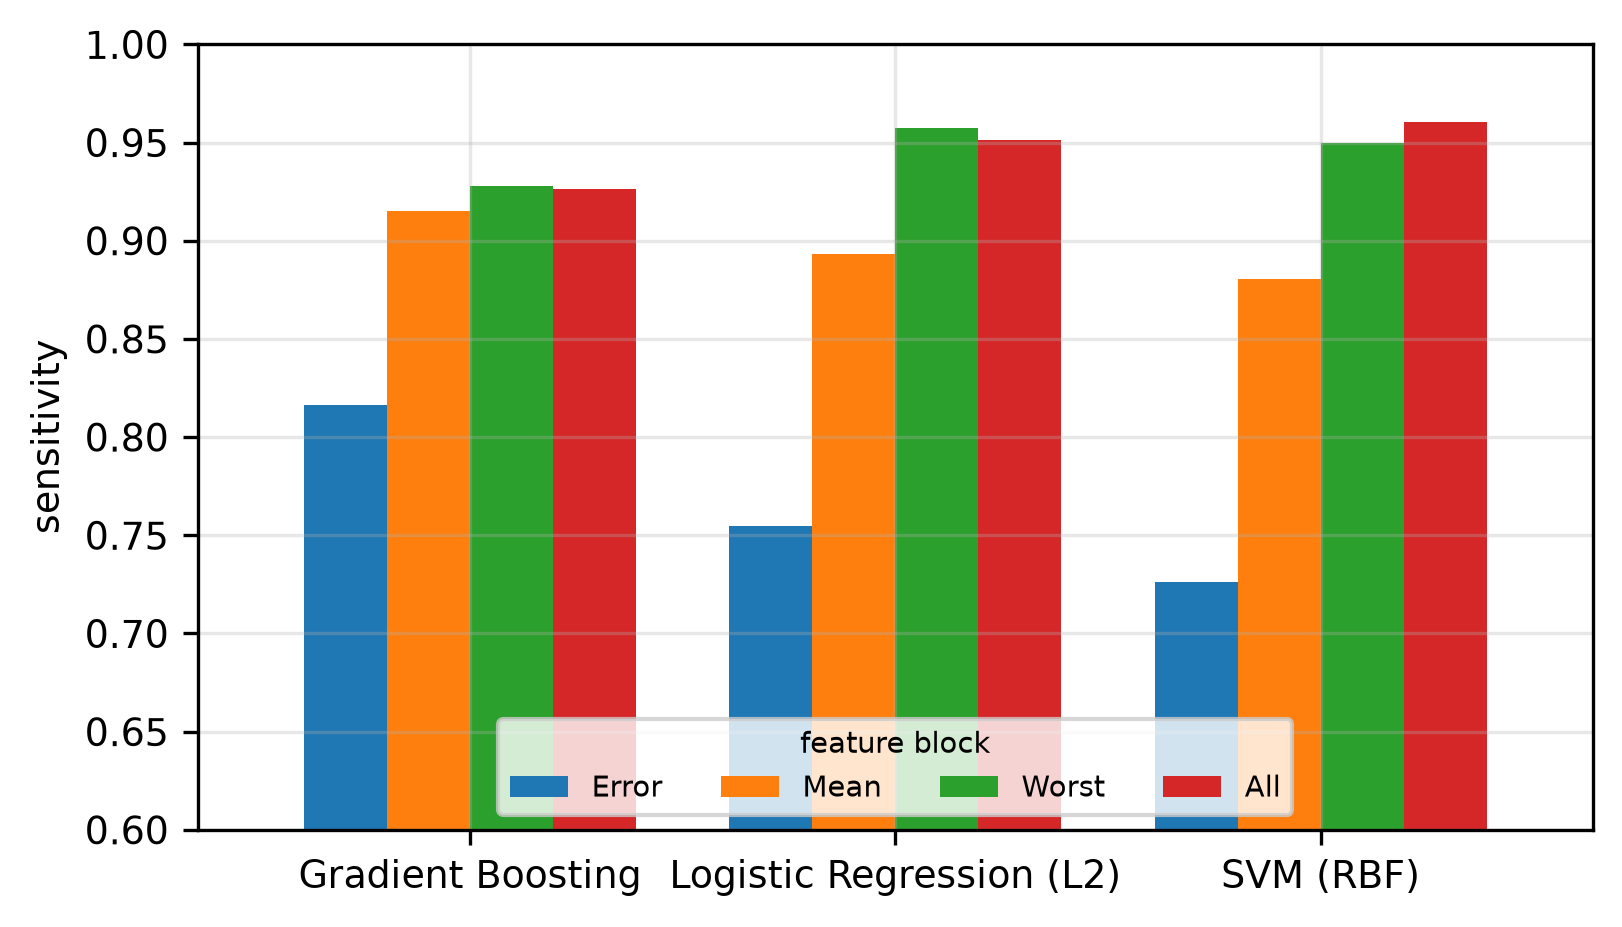

FIGURE: fig_models


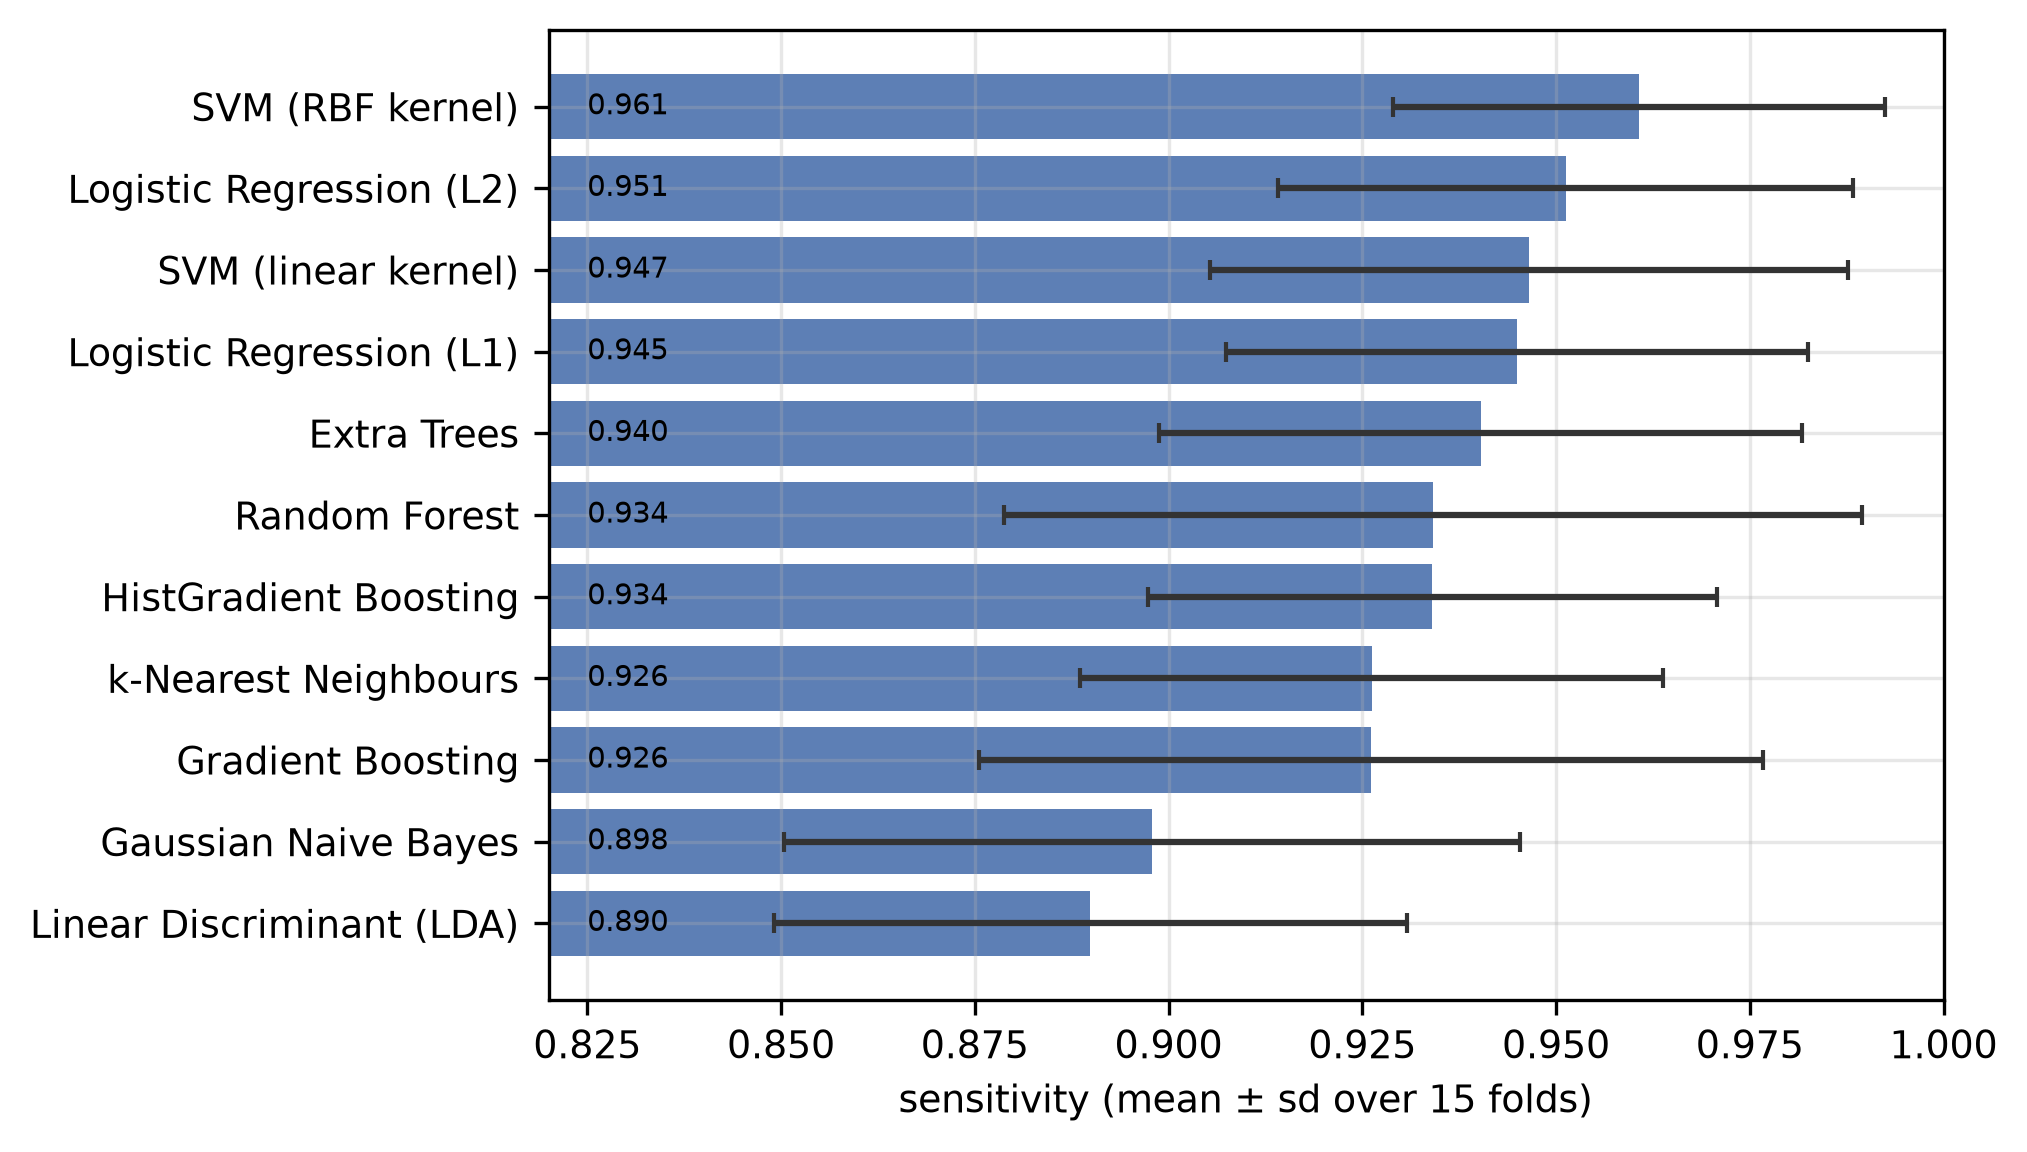

FIGURE: fig_models2


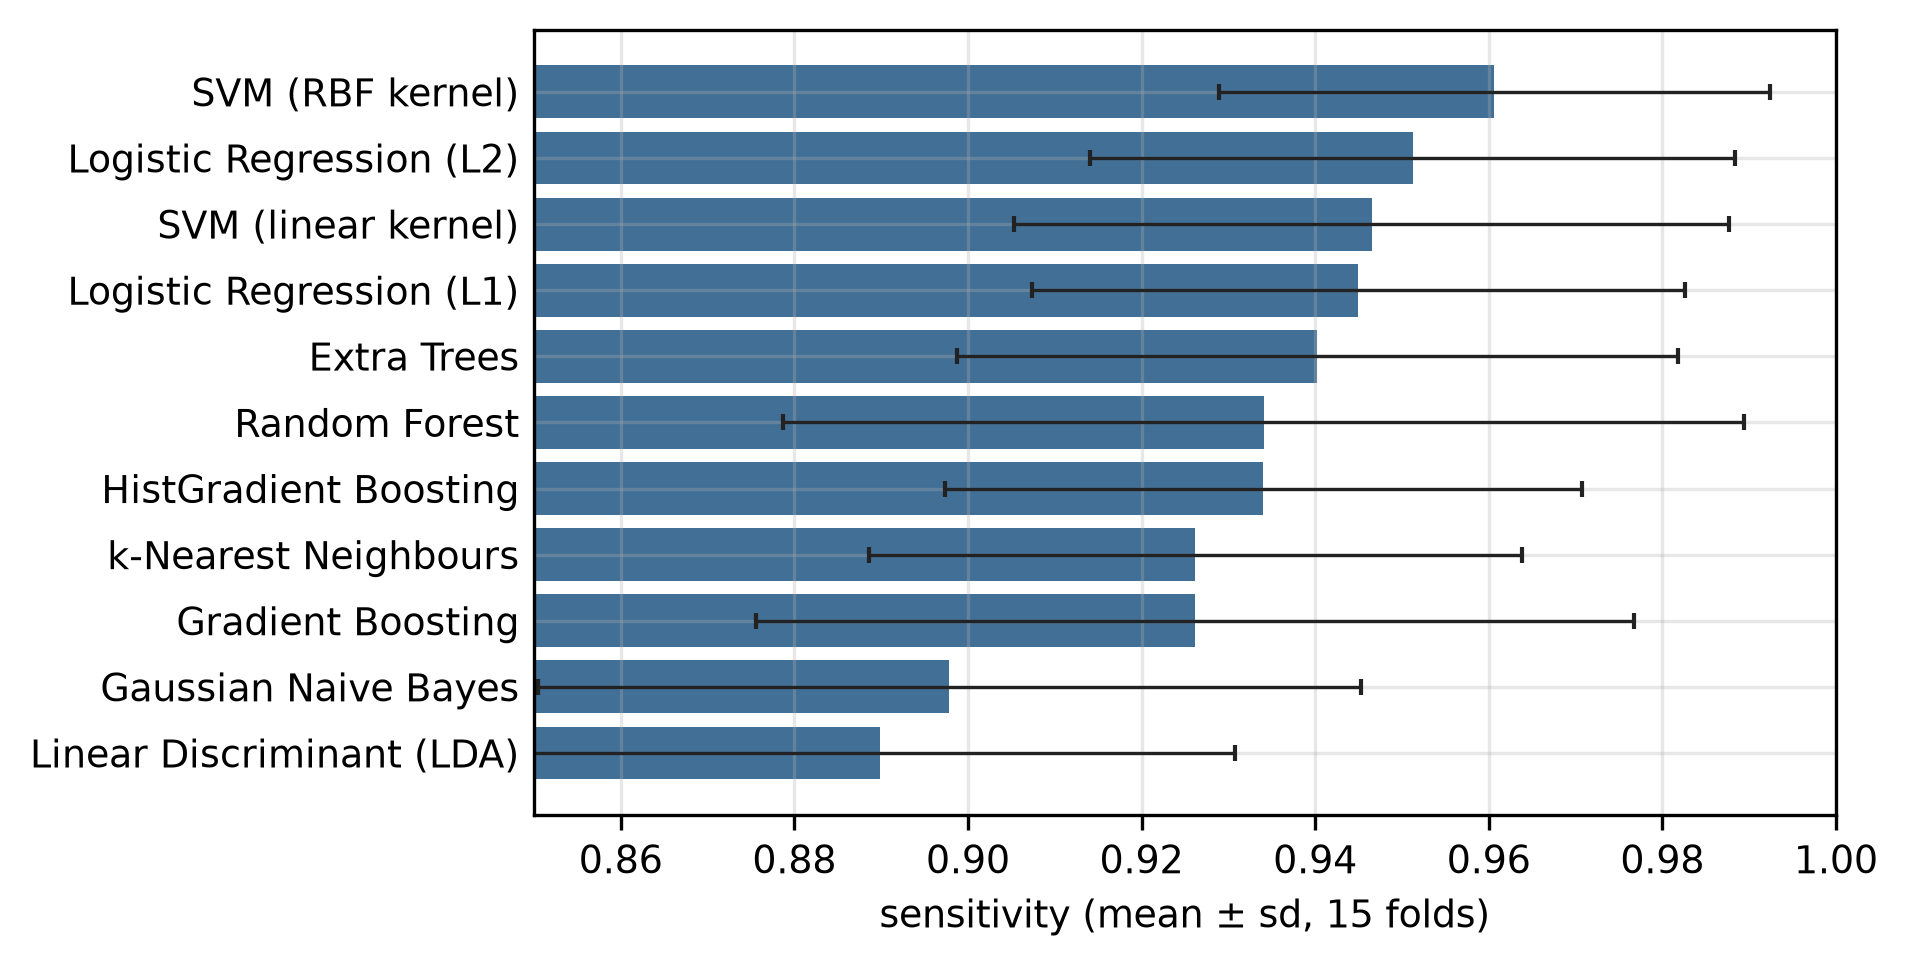

FIGURE: fig_threshold


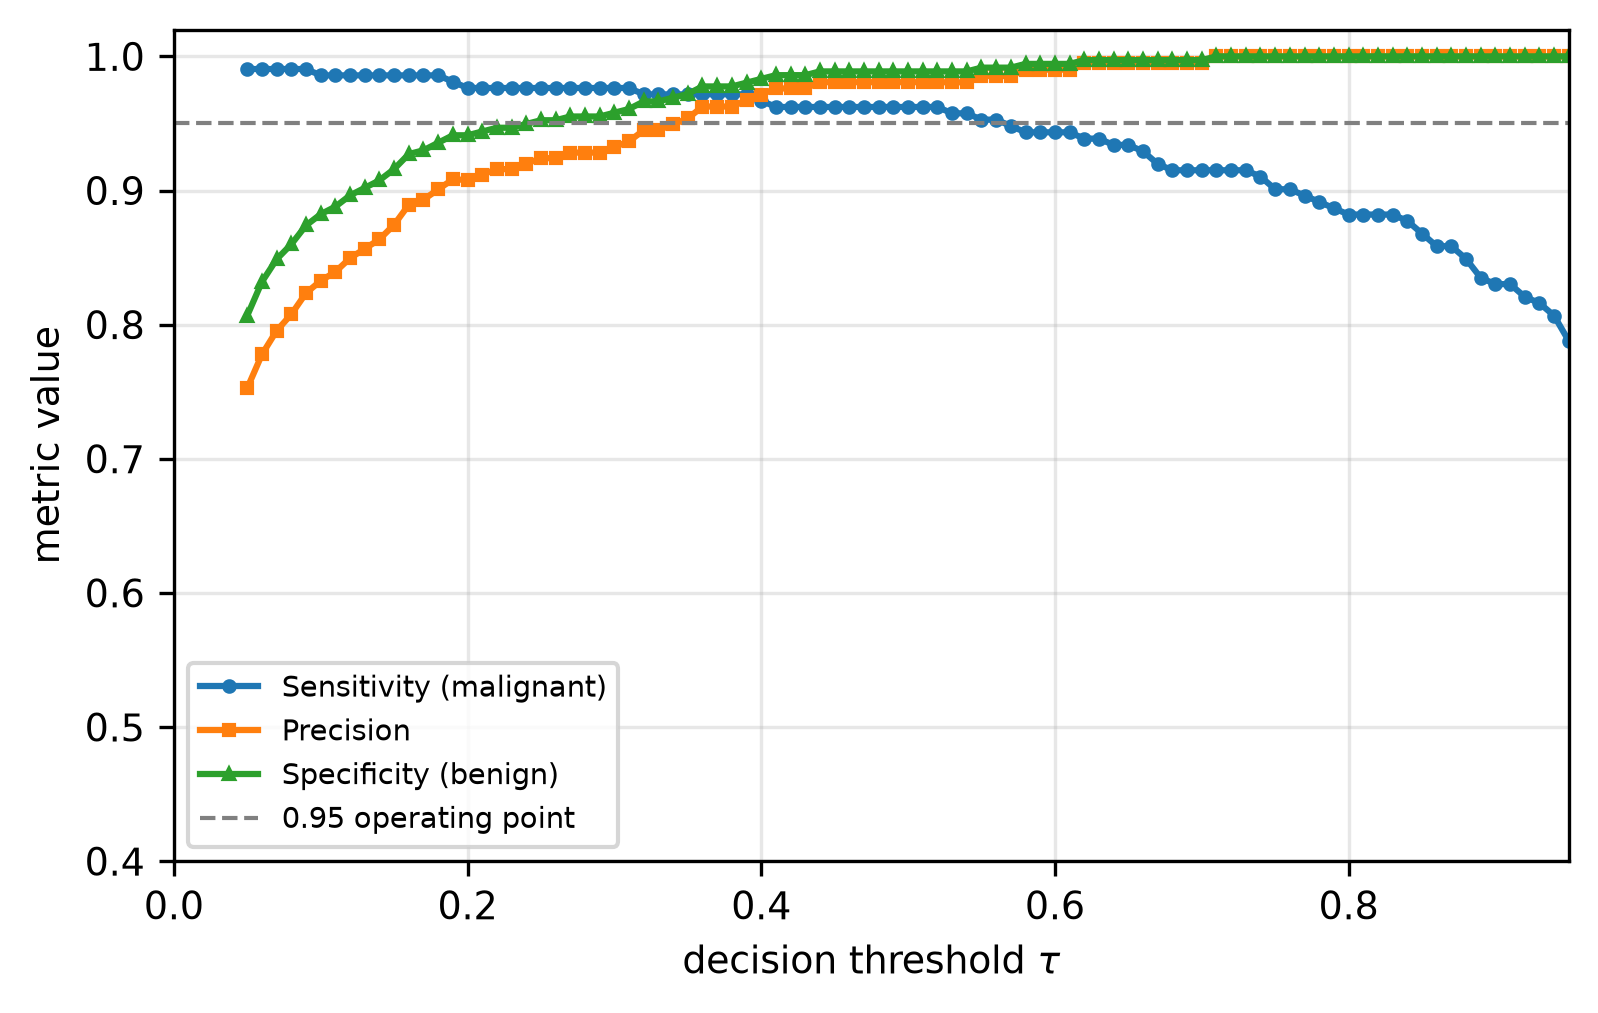

FIGURE: fig_threshold2


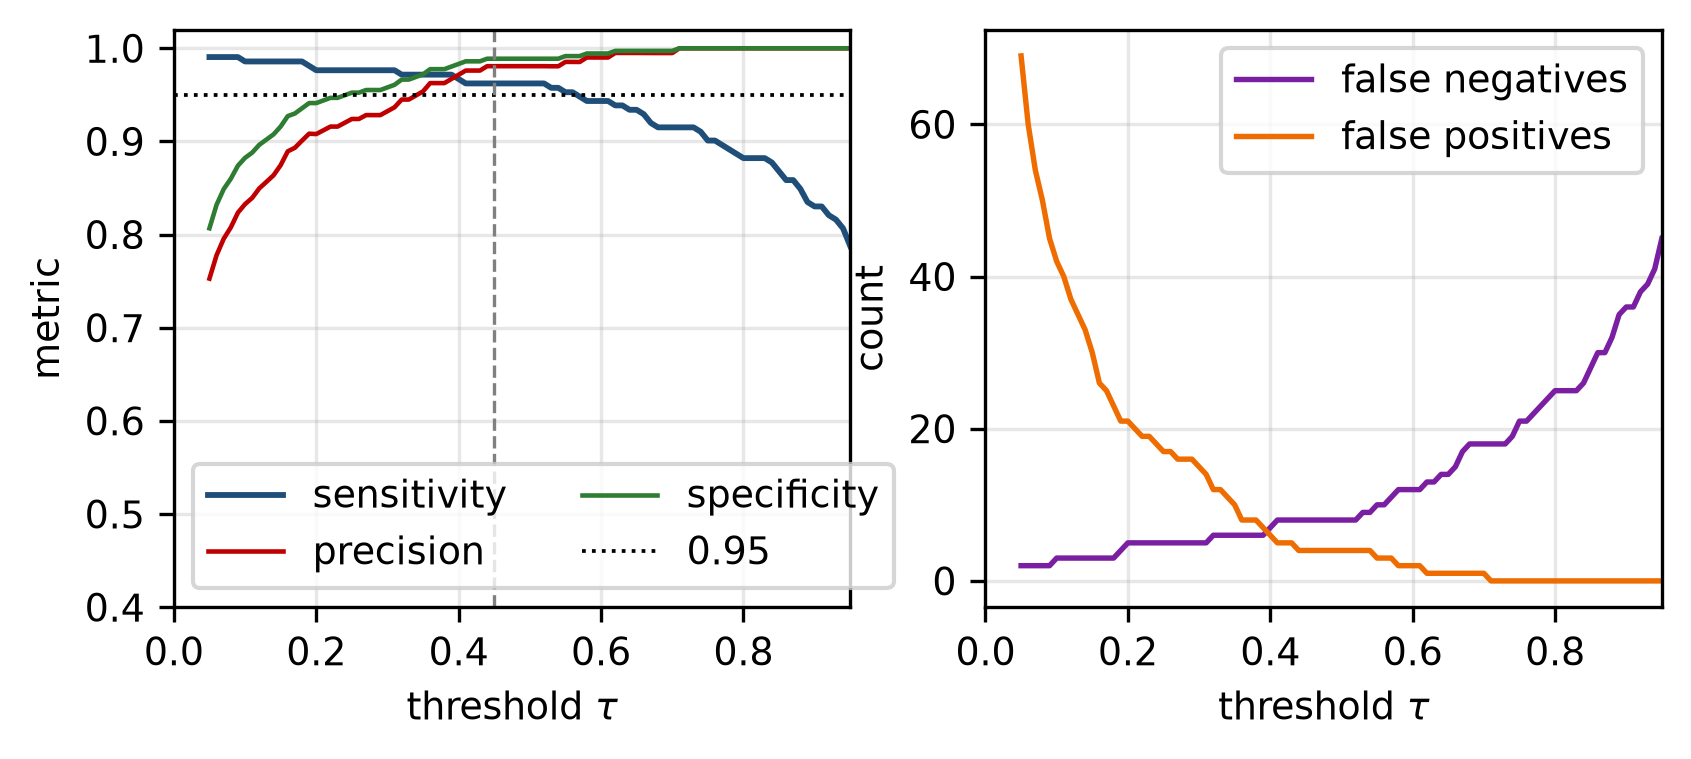

FIGURE: fig_reliability


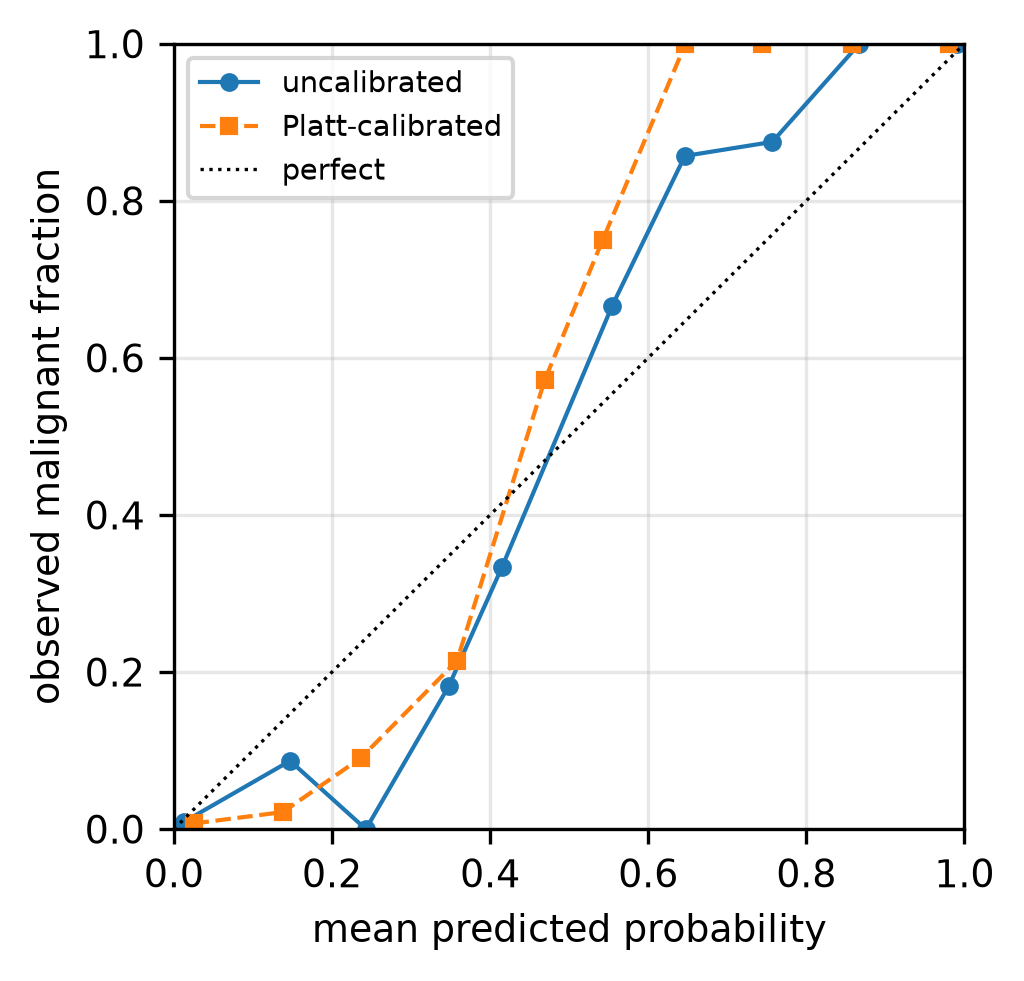

FIGURE: fig_kernel


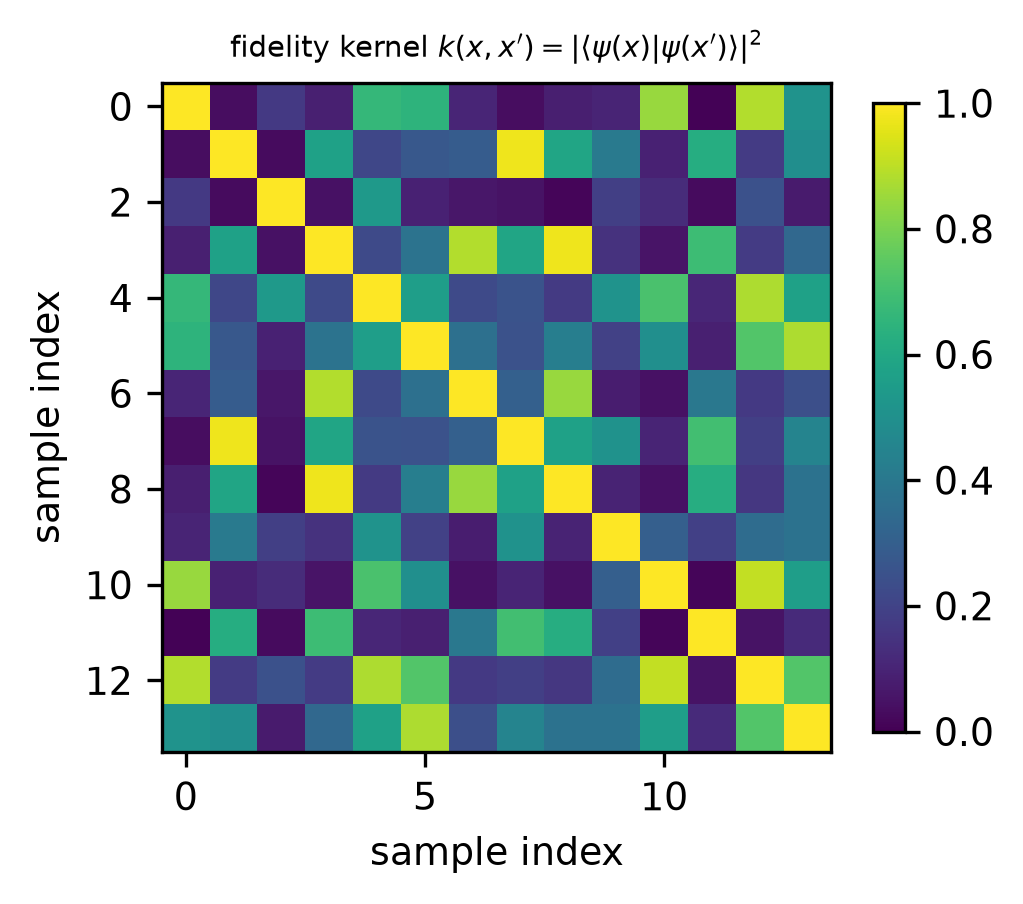

FIGURE: fig_learning


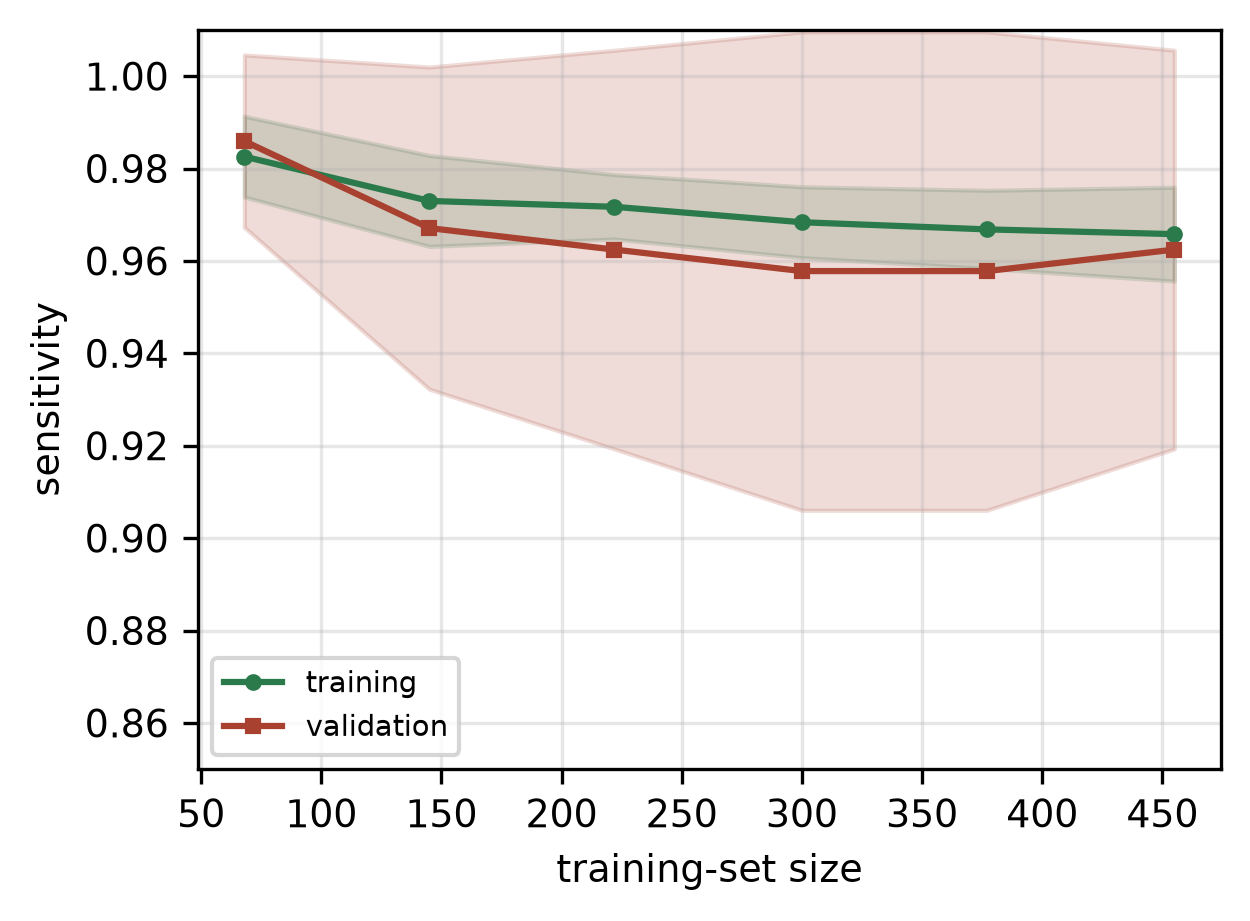

FIGURE: fig_multi_zoo_heatmap


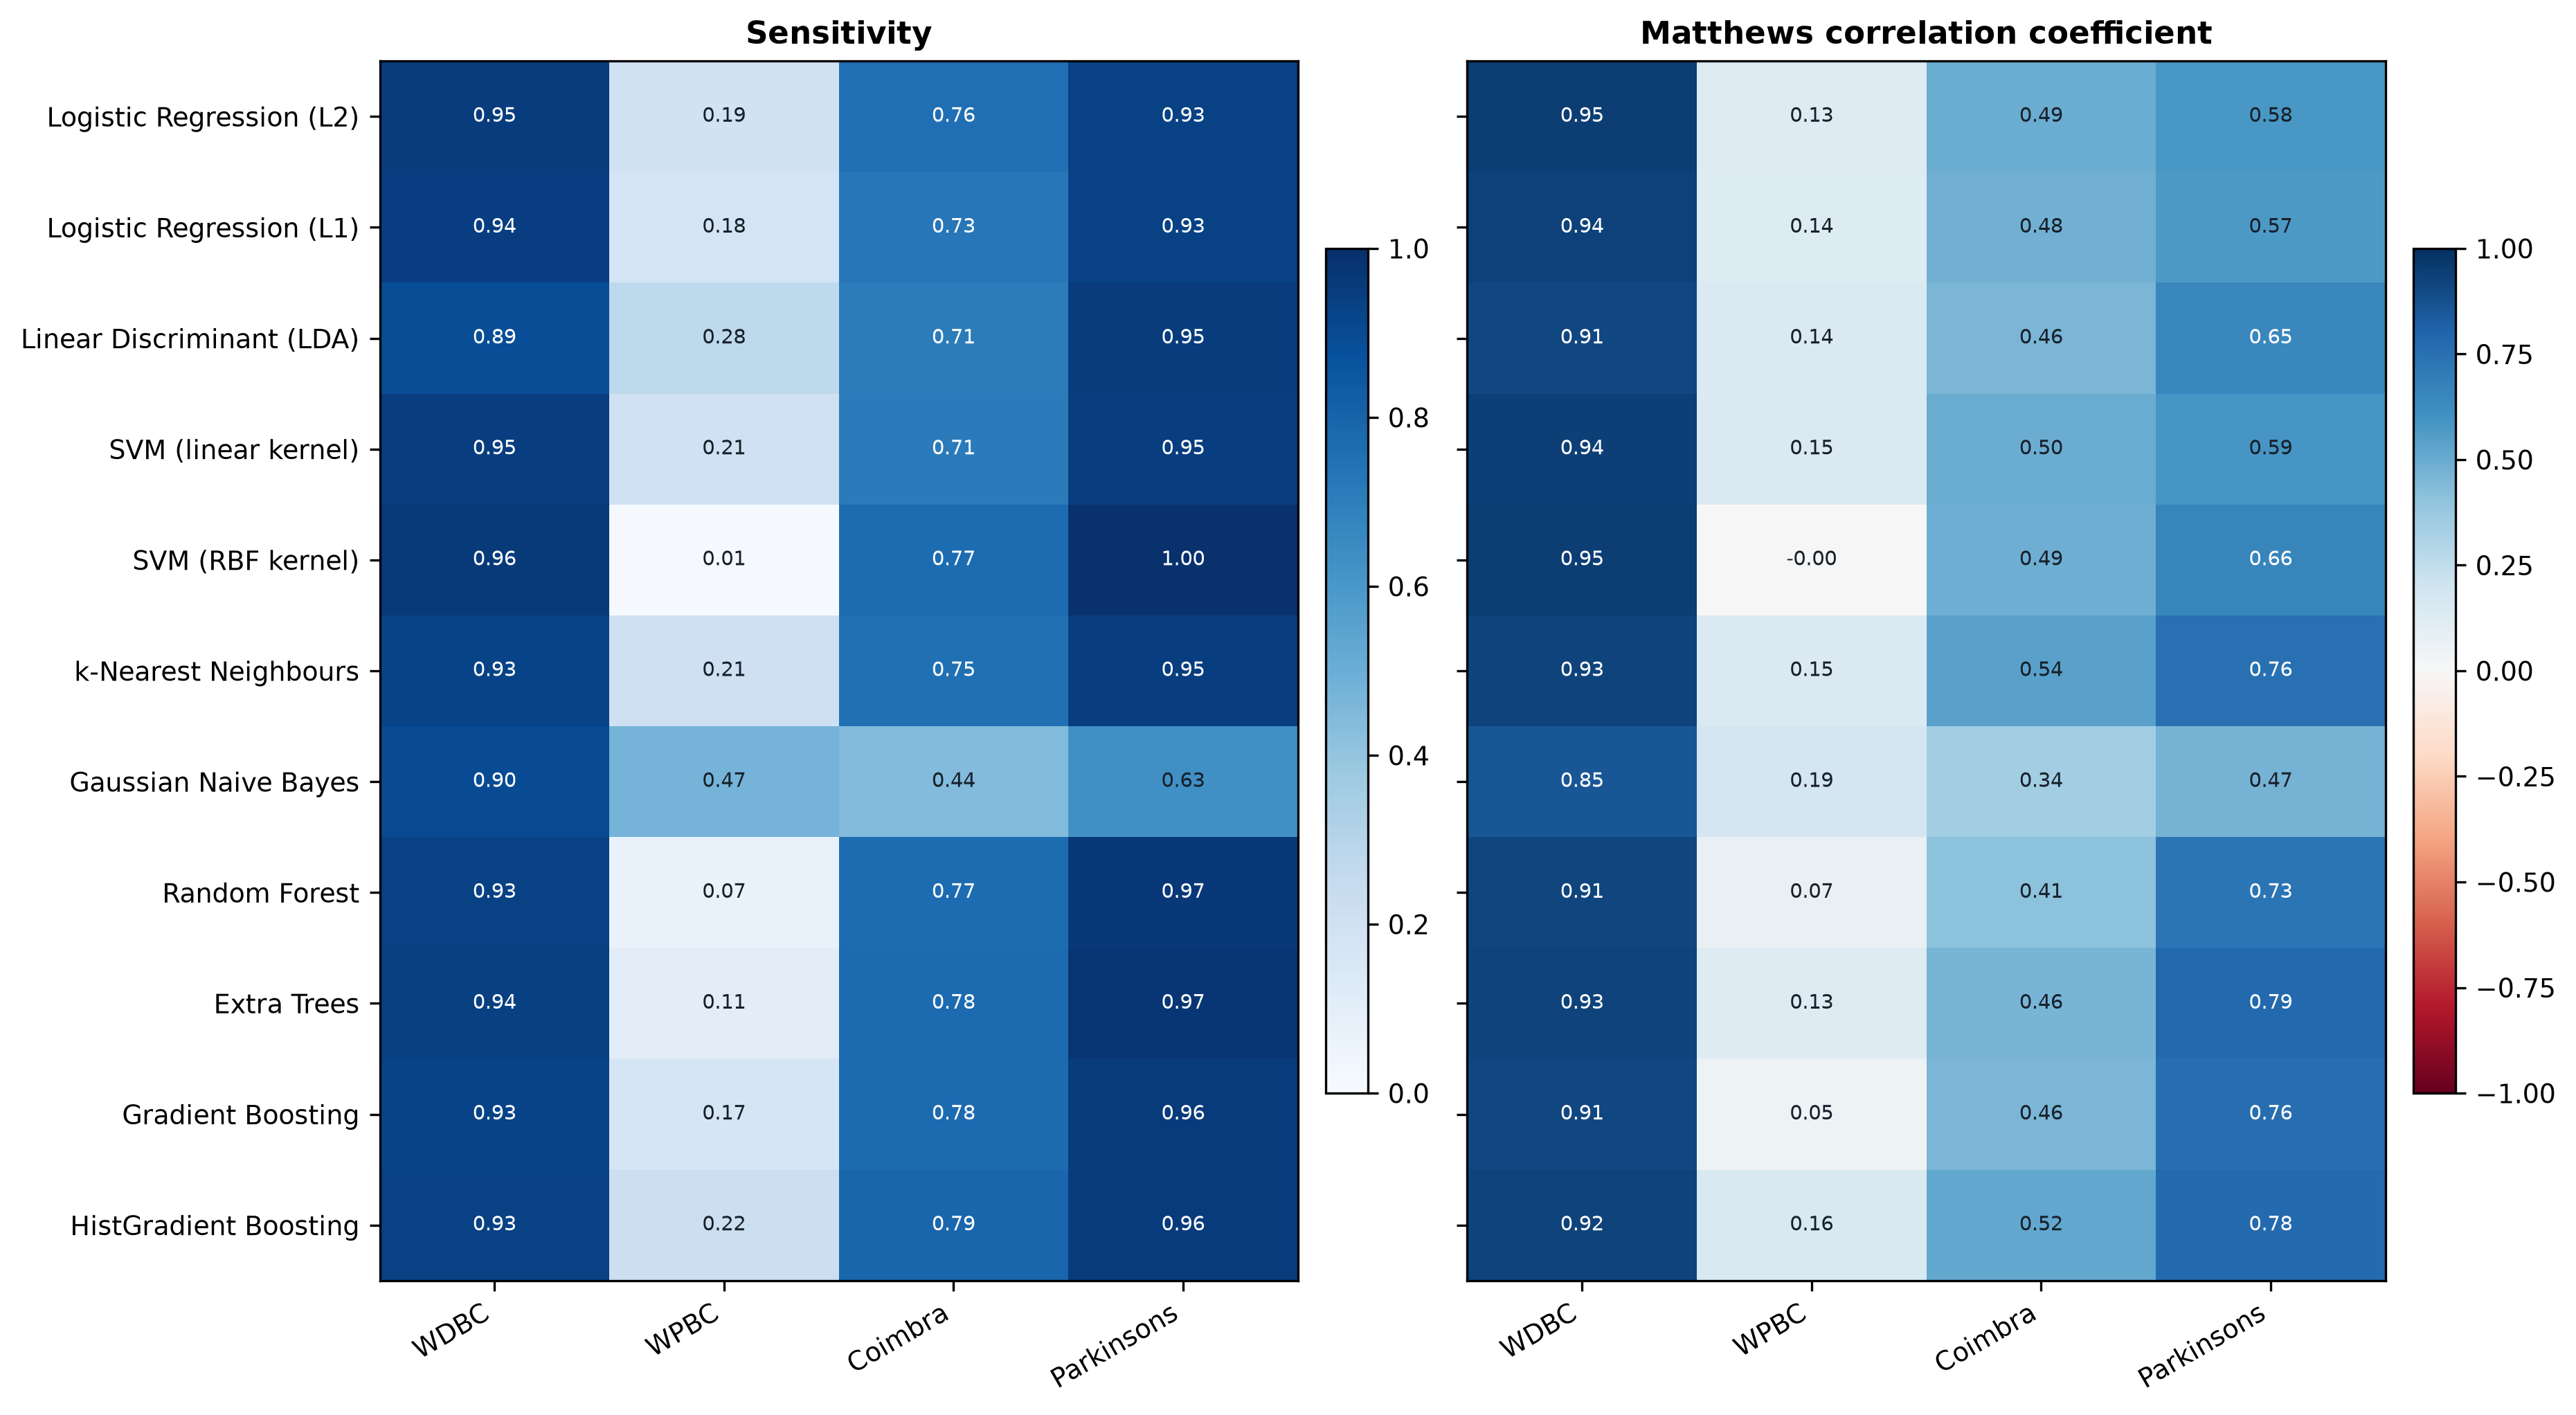

FIGURE: fig_multi_quantum_benchmark


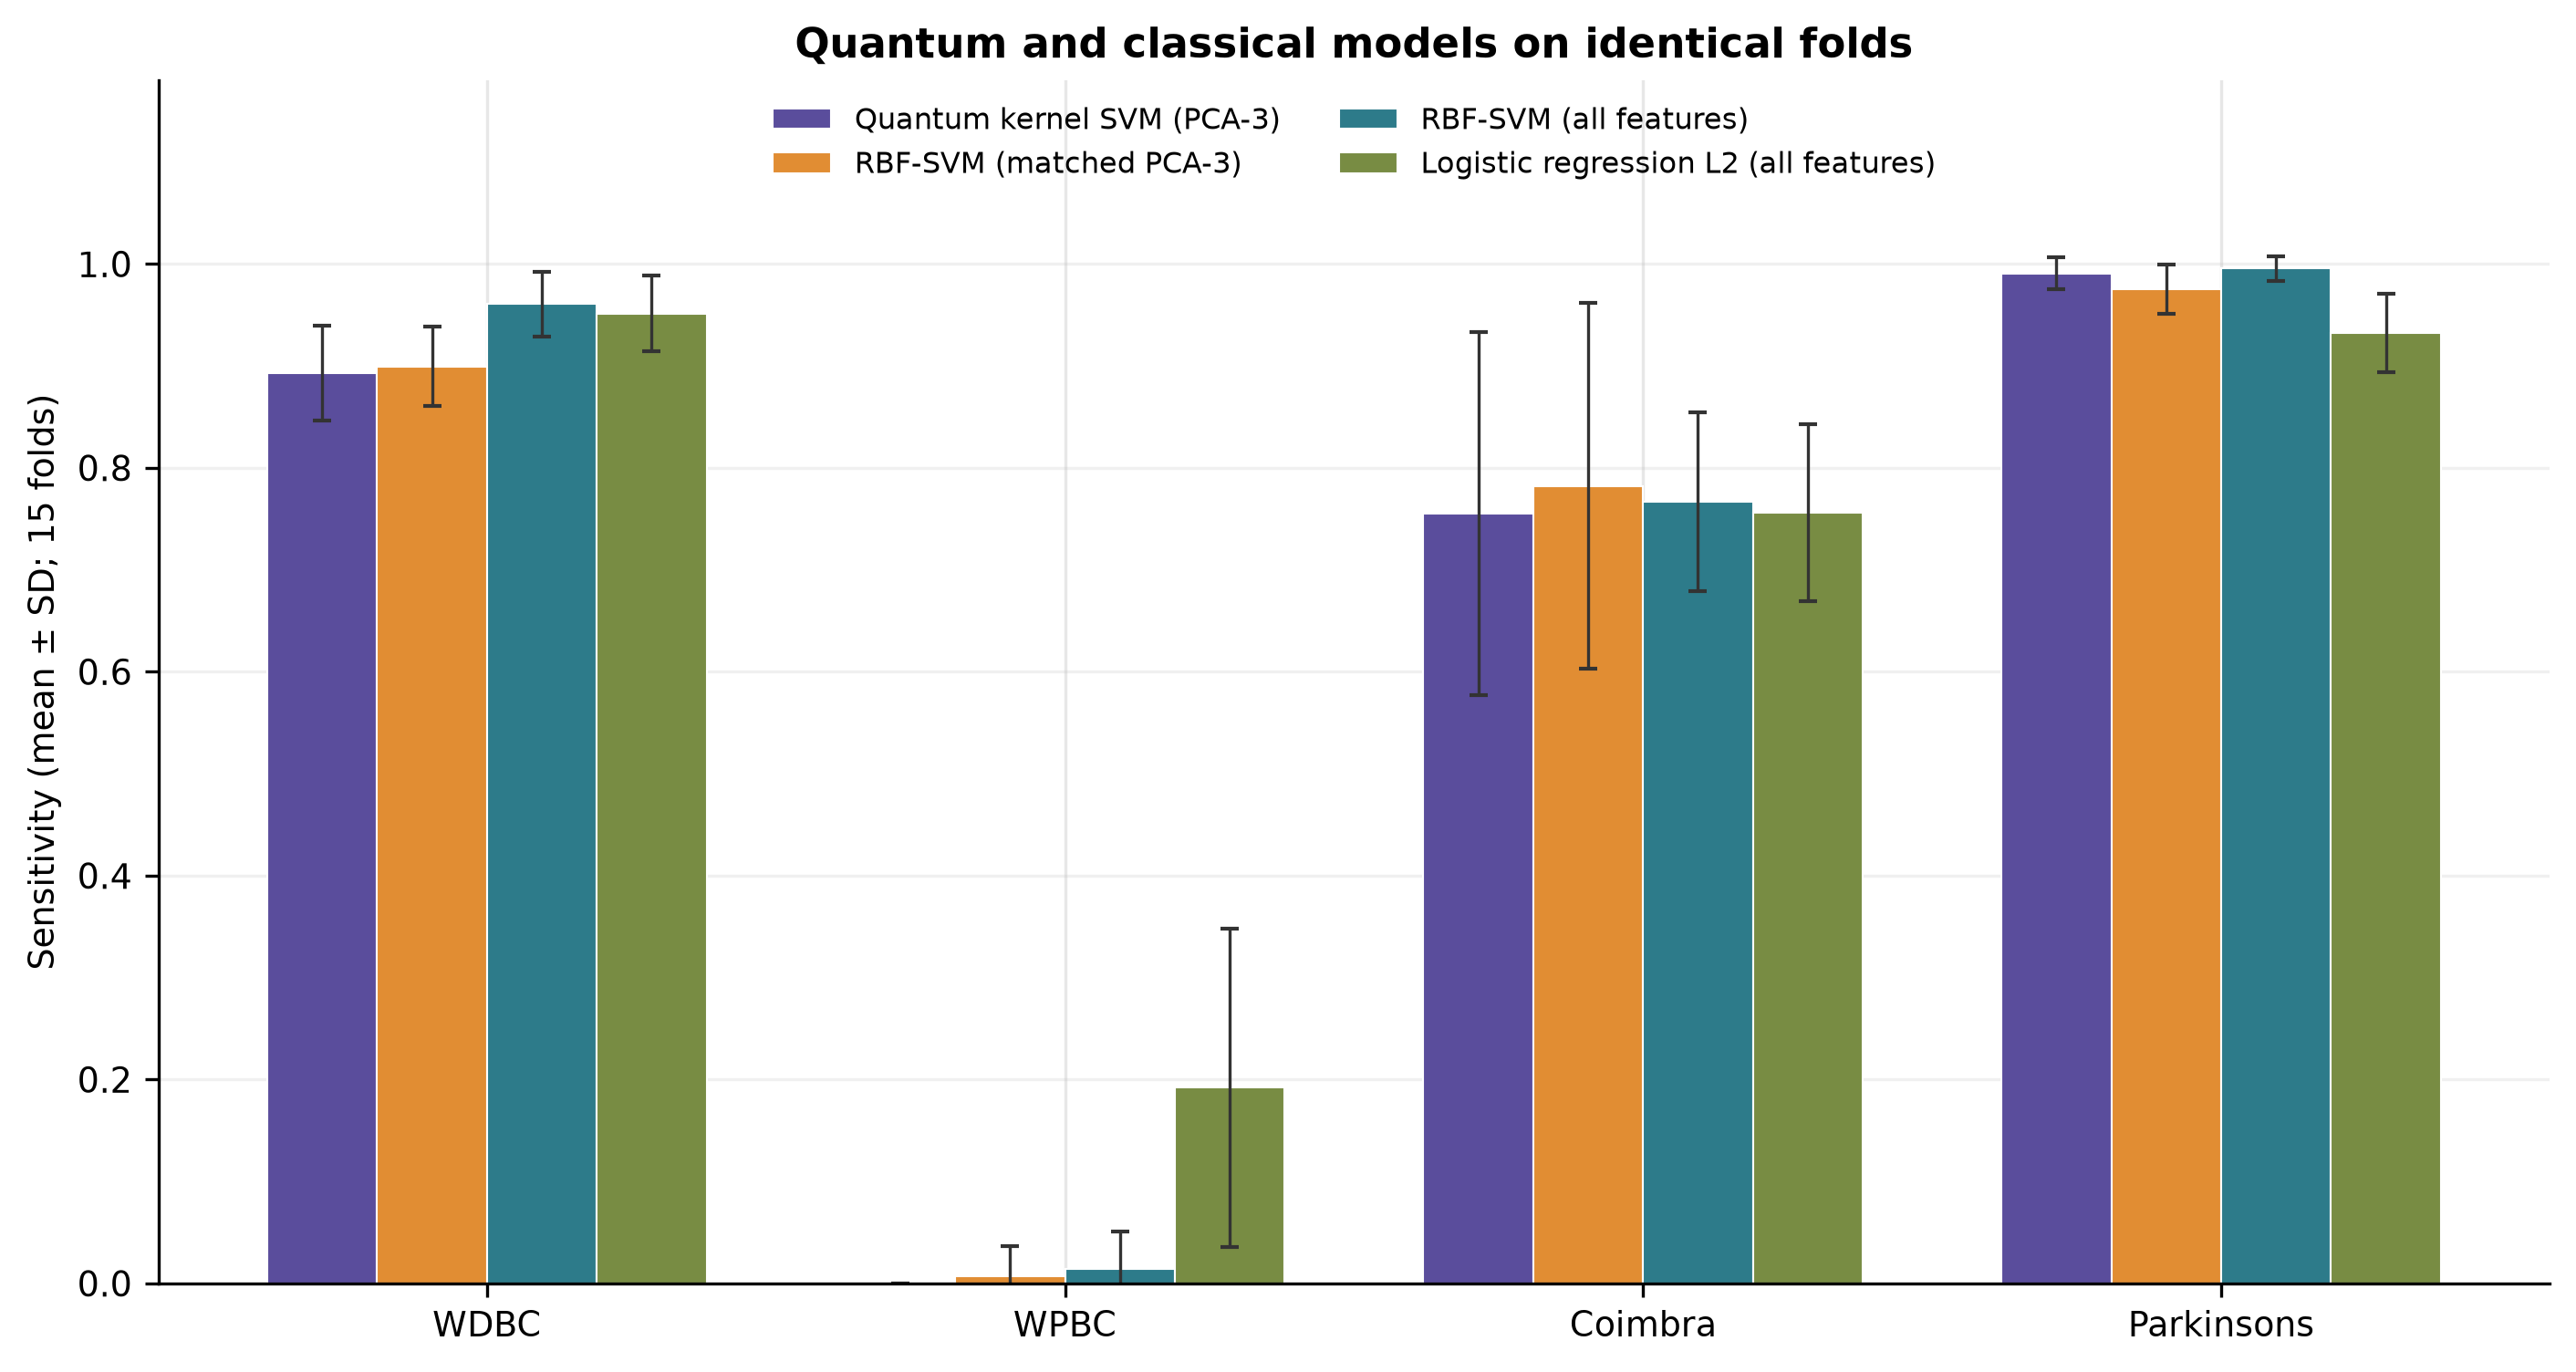

FIGURE: fig_multi_calibration


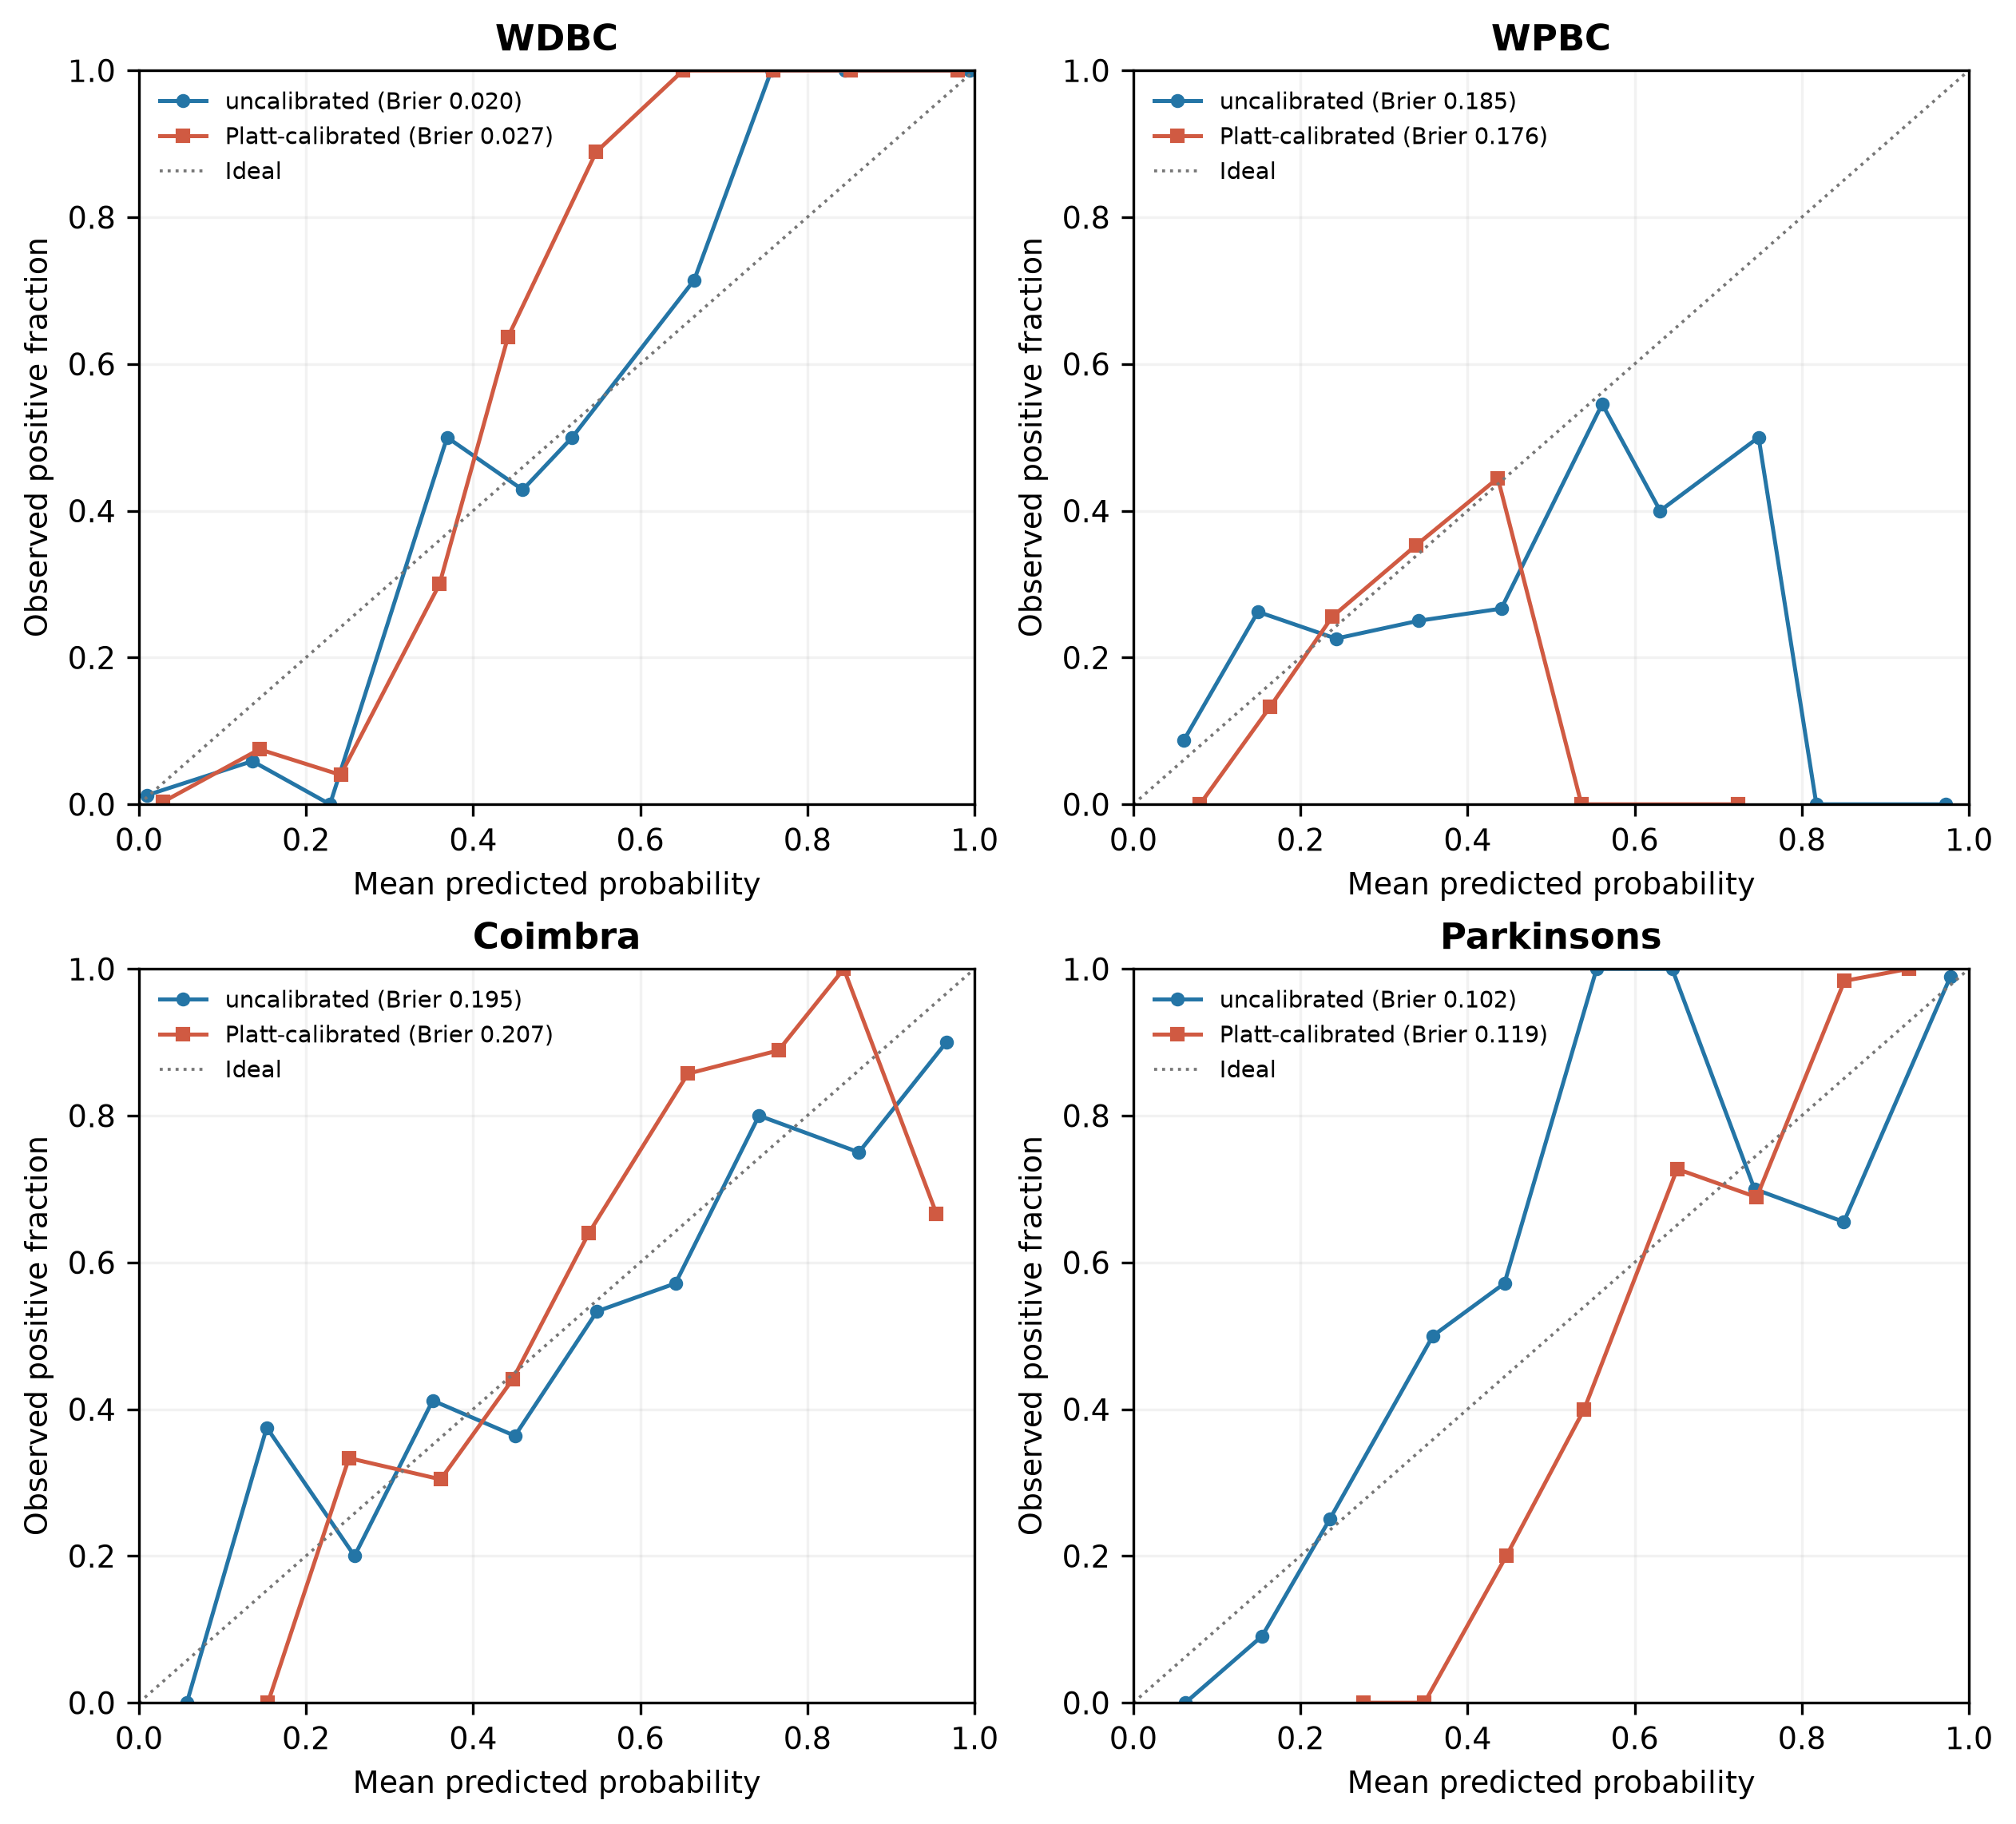

FIGURE: fig_multi_dca


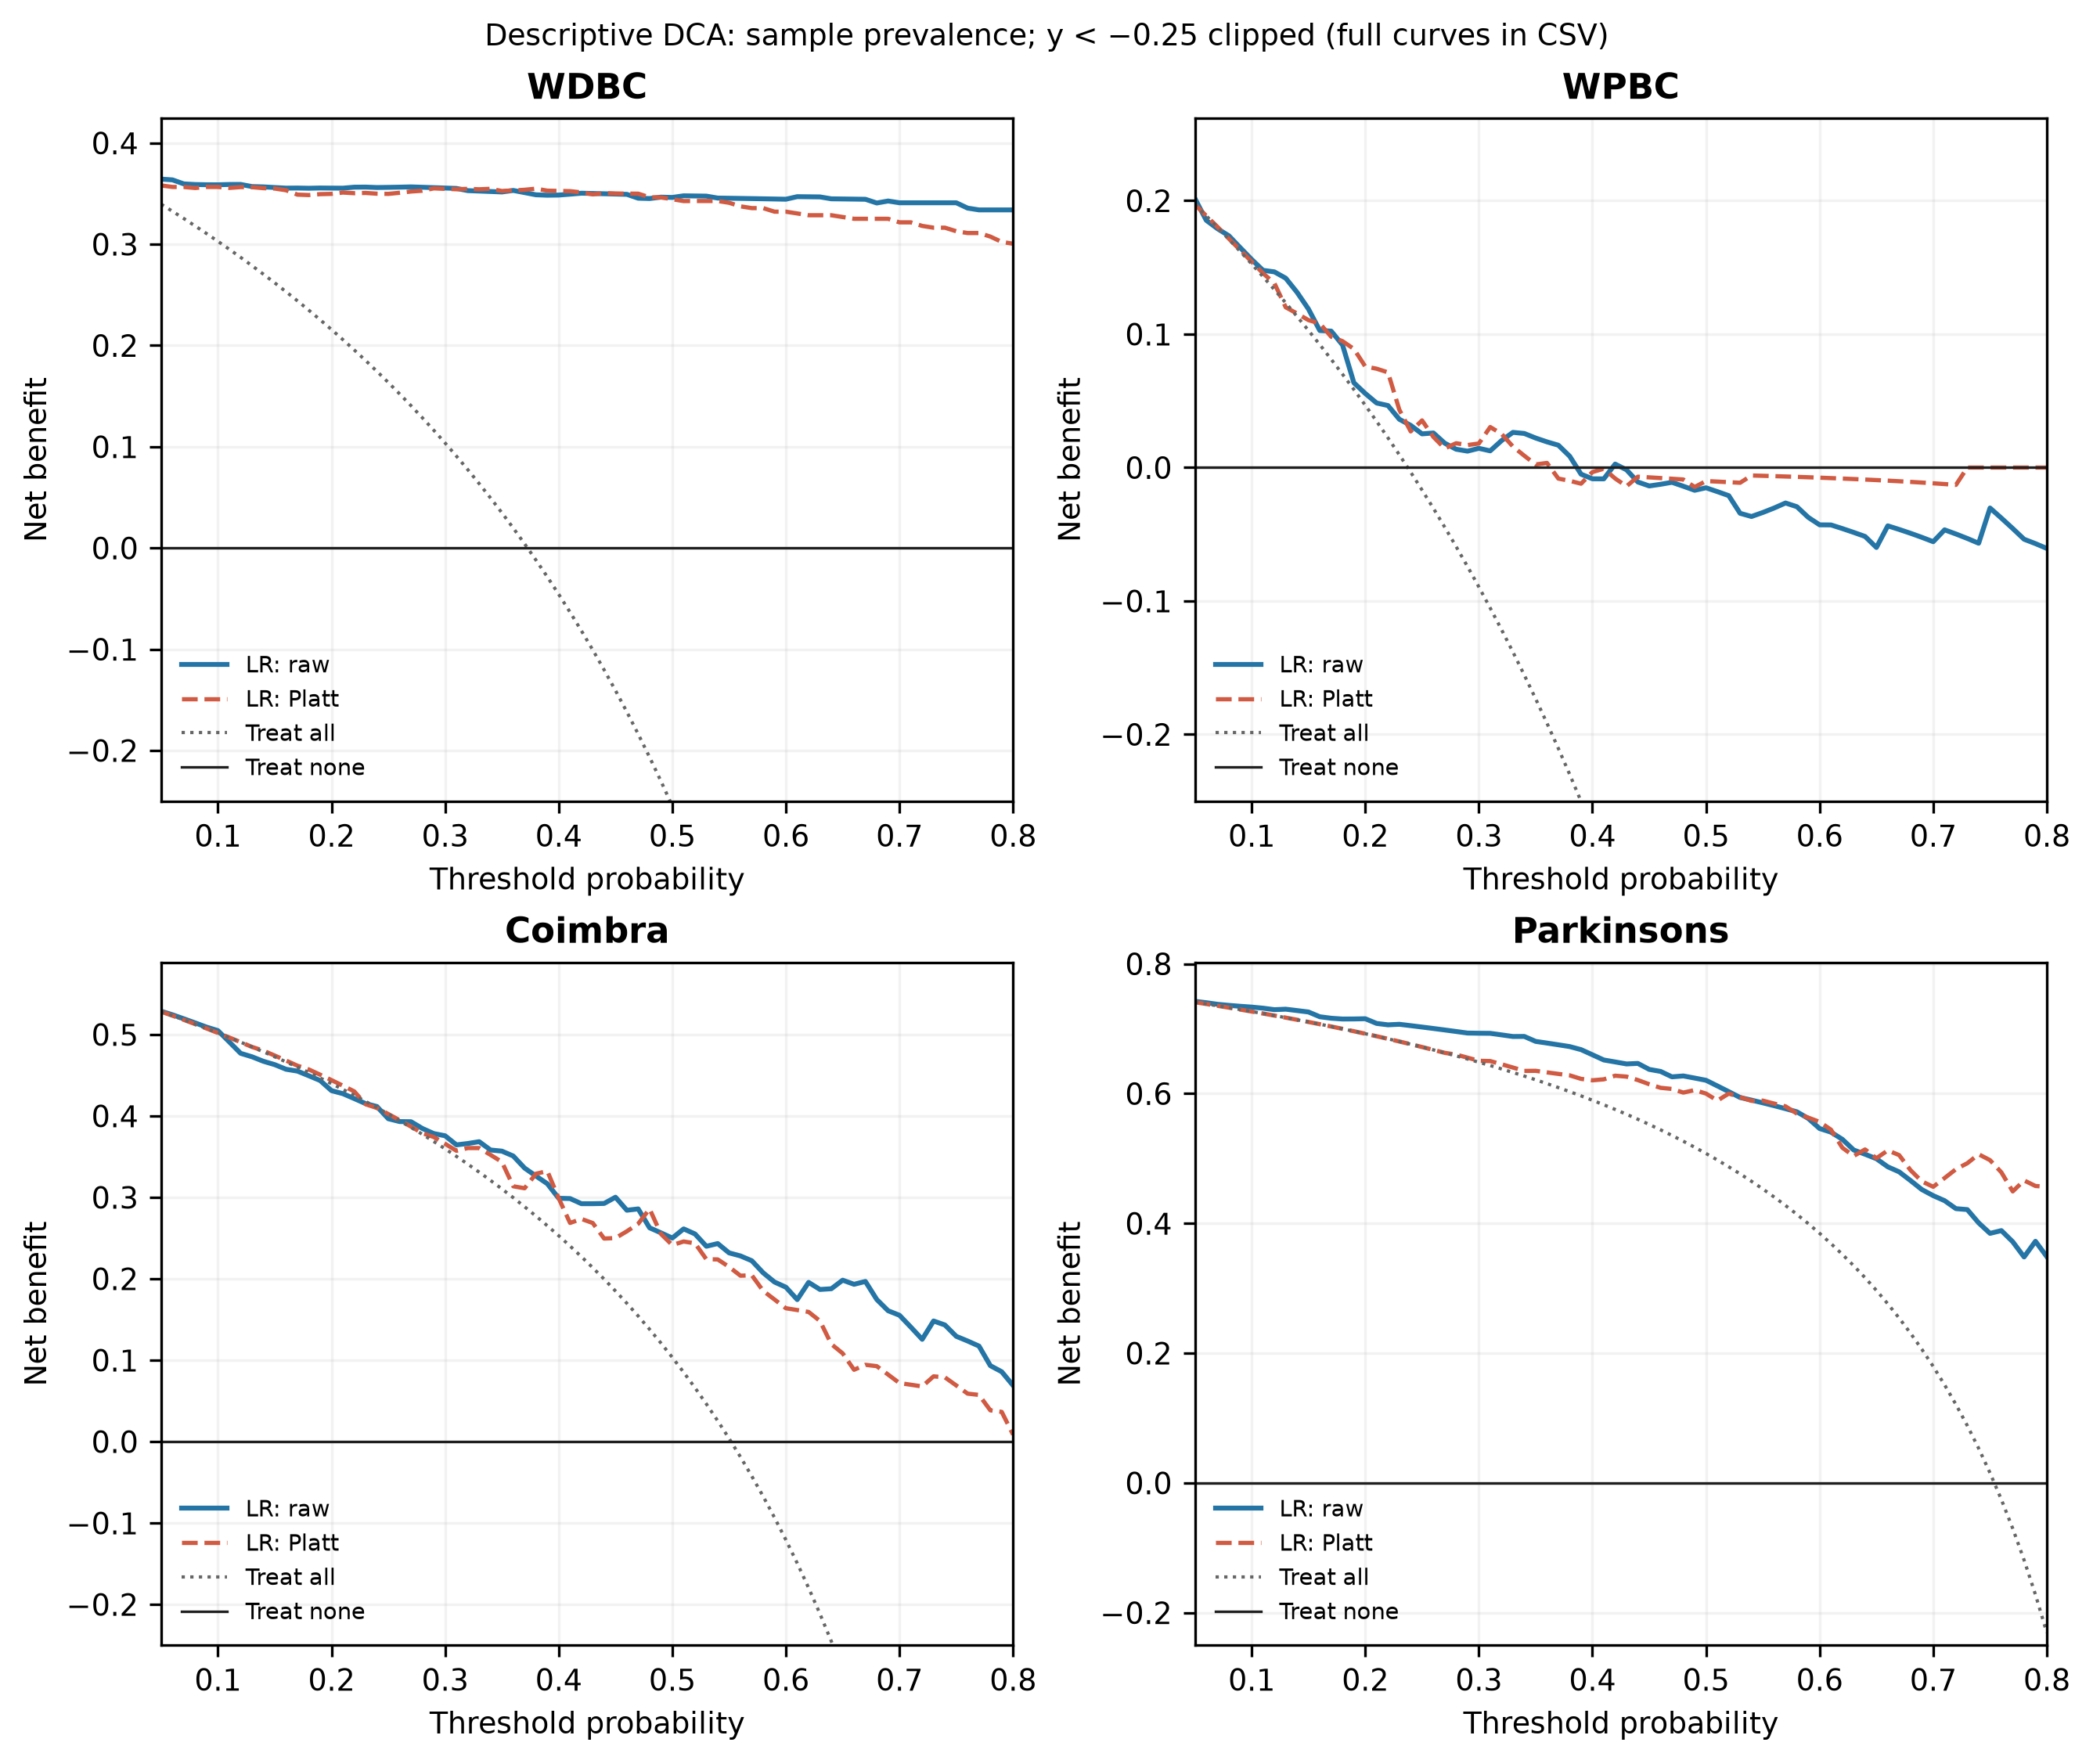

In [36]:
WDBC_FIGURES = ['fig_blocks', 'fig_models', 'fig_models2', 'fig_threshold', 'fig_threshold2', 'fig_reliability', 'fig_kernel', 'fig_learning']
MULTI_FIGURES = ['fig_multi_zoo_heatmap', 'fig_multi_quantum_benchmark', 'fig_multi_calibration', 'fig_multi_dca']
for name in WDBC_FIGURES + MULTI_FIGURES:
    print('FIGURE:', name)
    display(Image(filename=str(FIG / (name + '.png')), width=750))

**Interpretation.** Each plot is generated from the run's model outputs or checked kernel. Inspect the accompanying source CSVs and the stated axis limits before extracting a manuscript claim.

## 29. Complete primary tables at full precision

The following cell prints every row and column of the main experiment CSVs, including all threshold and decision-curve rows. Numeric values are formatted with up to 17 significant digits; companion fold-level, prediction-level and selected-feature files are available in `results/` for deeper auditing. The printed tables are descriptive outputs of the same execution, not substituted or invented values.

In [37]:
PRIMARY_TABLES = [
    'exp1_feature_blocks.csv', 'exp2_architectures.csv', 'exp2_model_zoo.csv', 'exp3_feature_selection.csv',
    'exp4a_threshold_curve.csv', 'exp4b_nested_threshold.csv', 'exp5a_calibration.csv', 'exp5b_reliability.csv',
    'exp5c_bootstrap_ci.csv', 'exp6_quantum_vs_classical.csv', 'exp7_mcnemar.csv', 'exp7_bootstrap_diff.csv',
    'exp8_learning_curve.csv', 'wdbc_numeric_reproducibility.csv', 'dataset_overlap_audit.csv', 'exp9_multi_dataset_blocks.csv',
    'exp10_multi_dataset_zoo.csv', 'exp11_multi_dataset_nested_threshold.csv',
    'exp12_multi_dataset_calibration.csv', 'exp12b_dca_curves.csv',
    'exp13_multi_dataset_quantum_benchmark.csv', 'exp13b_quantum_paired_tests.csv',
    'exp14_parkinsons_group_aware.csv',
    'exp15_legacy_pca3_all_datasets.csv',
    'exp16_legacy_calibration.csv',
    'exp17_legacy_threshold.csv',
    'exp18_3model_block_cross.csv',
    'exp19_parkinsons_split_overlap.csv',
    'exp20_model_coverage_audit.csv',
    'exp21_learning_curve_sampling_audit.csv']
for filename in PRIMARY_TABLES:
    frame = pd.read_csv(RESULTS / filename)
    print('\n' + '='*24 + ' ' + filename + ' ' + '='*24)
    print(frame.to_string(index=False, float_format=lambda x: format(x, '.17g')))


======================== exp1_feature_blocks.csv ========================
feature_block  n_features                    model    sensitivity_mean       sensitivity_sd      precision_mean    specificity_mean             f1_mean            mcc_mean        roc_auc_mean            fn_mean             fp_mean         fit_seconds
          All          30        Gradient Boosting 0.92617201919527525 0.050593910252650899 0.96043975803193038  0.9766562336984872 0.94196590587780682 0.91040936177645837 0.99248000203344677 3.1333333333333333  1.6666666666666667  7.4459741179998673
          All          30 Logistic Regression (L2)  0.9512366186784792   0.0371365961105583 0.98410313169530417 0.99066249347939483 0.96690804519479623  0.9489582370080204  0.9946430015637896 2.0666666666666669 0.66666666666666663 0.33630277500014921
          All          30                SVM (RBF)  0.9606496862310816 0.031739607939135502 0.97483977861175819  0.9850417318727176 0.96736029742258001 0.94881580906387042 

**Interpretation.** CSV files preserve the saved precision and are the authoritative source for numerical extraction. The two blank fixed-block stability values are documented not-applicable entries; all other result values are required to be finite.

## 30. Final executable quality gate

The final cell asserts existence, nonempty contents and finite numeric values for every required result CSV; it documents the two structurally not-applicable fixed-subset stability cells. It validates the PDF signatures, PNG integrity and 300-dpi metadata, raw and cleaned SHA-256 fingerprints, class counts, fold counts, bootstrap size and WPBC's four intentional missing predictors. A failure stops execution rather than silently reporting success.

In [38]:
from PIL import Image as PILImage

EXPECTED_RESULTS = [
    'exp1_feature_blocks.csv', 'exp2_model_zoo.csv', 'exp2_architectures.csv',
    'exp3_feature_selection.csv', 'exp4a_threshold_curve.csv', 'exp4b_nested_threshold.csv',
    'exp5a_calibration.csv', 'exp5b_reliability.csv', 'exp5c_bootstrap_ci.csv',
    'exp6_quantum_vs_classical.csv', 'exp7_mcnemar.csv', 'exp7_bootstrap_diff.csv',
    'exp8_learning_curve.csv', 'wdbc_numeric_reproducibility.csv', 'dataset_overlap_audit.csv',
    'exp9_multi_dataset_blocks.csv', 'exp9b_block_fold_metrics.csv', 'exp9c_selected_features.csv',
    'exp10_multi_dataset_zoo.csv', 'exp10b_multi_dataset_zoo_folds.csv',
    'exp11_multi_dataset_nested_threshold.csv', 'exp11b_nested_threshold_folds.csv', 'exp11c_nested_threshold_oof.csv',
    'exp12_multi_dataset_calibration.csv', 'exp12a_reliability_bins.csv', 'exp12b_dca_curves.csv', 'exp12c_calibration_oof.csv',
    'exp13_multi_dataset_quantum_benchmark.csv', 'exp13b_quantum_paired_tests.csv',
    'exp13c_quantum_fold_metrics.csv', 'exp13d_quantum_oof.csv',
    'exp14_parkinsons_group_aware.csv', 'exp14b_parkinsons_group_oof.csv',
    'exp15_legacy_pca3_all_datasets.csv',
    'exp15b_legacy_pca3_fold_metrics.csv',
    'exp15c_legacy_pca3_oof.csv',
    'exp16_legacy_calibration.csv',
    'exp16b_legacy_calibration_oof.csv',
    'exp17_legacy_threshold.csv',
    'exp17b_legacy_threshold_folds.csv',
    'exp17c_legacy_threshold_oof.csv',
    'exp18_3model_block_cross.csv',
    'exp18b_3model_block_folds.csv',
    'exp19_parkinsons_split_overlap.csv',
    'exp20_model_coverage_audit.csv',
    'exp21_learning_curve_sampling_audit.csv',
]
EXPECTED_FIGURES = ['fig_blocks', 'fig_models', 'fig_models2', 'fig_threshold', 'fig_threshold2',
                    'fig_reliability', 'fig_kernel', 'fig_learning', 'fig_multi_zoo_heatmap',
                    'fig_multi_quantum_benchmark', 'fig_multi_calibration', 'fig_multi_dca']
assert len(EXPECTED_RESULTS) == len(set(EXPECTED_RESULTS)) == 46
for filename in EXPECTED_RESULTS:
    path = RESULTS / filename
    assert path.is_file() and path.stat().st_size > 0, f'Missing or empty CSV: {path}'
    df = pd.read_csv(path)
    assert not df.empty, f'Empty CSV: {path}'
    # Exactly two fixed-subset stability cells are legitimately not applicable.
    if filename == 'exp3_feature_selection.csv':
        allowed = (df.configuration.str.startswith('fixed:') & df.fold_selection_stability_jaccard.isna())
        assert allowed.sum() == 2
        checked = df.copy()
        checked.loc[allowed, 'fold_selection_stability_jaccard'] = 1.0
    else:
        checked = df
    assert not checked.isna().any().any(), f'Unexpected missing value in {path}'
    numeric = checked.select_dtypes(include=[np.number])
    assert np.isfinite(numeric.to_numpy(dtype=float)).all(), f'Nonfinite numeric value in {path}'

for name in EXPECTED_FIGURES:
    pdf, png = FIG / (name + '.pdf'), FIG / (name + '.png')
    assert pdf.is_file() and pdf.stat().st_size > 500 and pdf.read_bytes()[:4] == b'%PDF', pdf
    assert b'/Subtype /Image' not in pdf.read_bytes(), f'Embedded raster in vector PDF: {pdf}'
    assert png.is_file() and png.stat().st_size > 500, png
    with PILImage.open(png) as img:
        img.verify()
    with PILImage.open(png) as img:
        assert img.width >= 500 and img.height >= 500, (png, img.size)
        dpi = img.info.get('dpi', (0, 0))
        assert abs(dpi[0] - 300) < 1 and abs(dpi[1] - 300) < 1, (png, dpi)

for line in (DATA / 'SHA256SUMS').read_text(encoding='utf-8').splitlines():
    digest, filename = line.split('  ', 1)
    assert sha256_file(filename) == digest, f'Checksum mismatch: {filename}'
for dataset, dset in DATASETS.items():
    clean = pd.read_csv(DATA / f'{dataset.lower()}_clean.csv')
    if dataset == 'WPBC':
        assert clean.isna().sum().sum() == 4 and clean.lymph_node_status.isna().sum() == 4
    else:
        assert not clean.isna().any().any()
assert multi_zoo.groupby('dataset').size().eq(11).all()
assert quantum_multi.groupby('dataset').size().eq(4).all()
assert (nested_multi.bootstrap_replicates == 2000).all()
assert dca_multi.groupby('dataset').size().eq(76).all()
print(f'PASS: {len(EXPECTED_RESULTS)} CSV results; {len(EXPECTED_FIGURES)} figures × PDF and 300-dpi PNG.')
print('PASS: all result cells finite, except exactly two documented not-applicable fixed-block stability values.')
print('PASS: four clean dataset exports, source hashes, class counts, fold counts, and required bootstrap replicates.')
print('PASS: WPBC has exactly four intentional missing measurements, imputed only within training pipelines.')
assert len(coverage) == 60 and coverage.groupby('dataset').size().eq(15).all()
assert len(block3_multi) == 39 and len(legacy_pca) == 4
print('PASS: original-estimator AST identity and all-dataset coverage audit, legacy variants and split-overlap checks.')


PASS: 46 CSV results; 12 figures × PDF and 300-dpi PNG.
PASS: all result cells finite, except exactly two documented not-applicable fixed-block stability values.
PASS: four clean dataset exports, source hashes, class counts, fold counts, and required bootstrap replicates.
PASS: WPBC has exactly four intentional missing measurements, imputed only within training pipelines.
PASS: original-estimator AST identity and all-dataset coverage audit, legacy variants and split-overlap checks.
